## Complete Pipline

In [ ]:
!pip install snntorch

In [ ]:
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset


import snntorch as snn
from snntorch import surrogate


from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.metrics import roc_auc_score, classification_report, confusion_matrix


import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings
import joblib
import json
import csv


warnings.filterwarnings('ignore', category=UserWarning, module='sklearn')



torch.manual_seed(0)
np.random.seed(0)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(0)
# -------------------------------------


#region: PLOTTING AND UTILITY FUNCTIONS
def save_fig(fig, path, dpi=300, transparent=False):
    p = Path(path)
    p.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(p, dpi=dpi, bbox_inches="tight", transparent=transparent)
    plt.close(fig)


def plot_raster_pretty(spike_tensor, idx=0, title="Raster", downsample_neurons=None, ax=None):
    if spike_tensor.shape[0] == 0: return None
    S = spike_tensor[idx].cpu().numpy()
    T, N = S.shape
    if downsample_neurons and downsample_neurons < N:
        pick = np.linspace(0, N-1, downsample_neurons).astype(int)
        S = S[:, pick]
        N = S.shape[1]


    events = [np.nonzero(S[:, n])[0] for n in range(N)]


    created = False
    if ax is None:
        fig, ax = plt.subplots(figsize=(12, 4), dpi=180)
        created = True
    else:
        fig = ax.figure


    ax.eventplot(events, colors="black", lineoffsets=np.arange(N), linelengths=0.9, linewidths=1.2)
    ax.set_title(f"{title}\nT={T} | N={N}", weight="bold")
    ax.set_xlabel("Time")
    ax.set_ylabel("Neuron")
    ax.set_xlim(-1, T)
    ax.set_ylim(-1, N)
    ax.set_xticks(np.arange(0, T, max(1, 5)))
    ax.set_yticks(np.arange(0, N, max(1, 5)))
    ax.grid(True, axis="x", linestyle=":", linewidth=0.6, alpha=0.6)
    for s in ["top", "right"]: ax.spines[s].set_visible(False)
    if created: plt.tight_layout(); plt.show()
    return fig


# Plot Average Spike Counts (Neuron & Timestep)
def plot_avg_spike_counts_pretty(spike_tensor, title_prefix="", figsize=(8, 4), dpi=160):
    if spike_tensor.shape[0] == 0: return
    S = spike_tensor
    avg_per_neuron = (S.sum(dim=(0,1)).cpu().numpy() if hasattr(S,"cpu") else S.sum(axis=(0,1))) / S.shape[0]
    avg_per_time   = (S.sum(dim=(0,2)).cpu().numpy() if hasattr(S,"cpu") else S.sum(axis=(0,2))) / S.shape[0]
    fig, axs = plt.subplots(1,2, figsize=figsize, dpi=dpi)
    axs[0].bar(range(len(avg_per_neuron)), avg_per_neuron)
    axs[0].set_title(f"{title_prefix} Avg spikes / neuron", weight="bold")
    axs[0].set_xlabel("Neuron")
    axs[0].set_ylabel("Avg")
    axs[0].grid(True, axis="y", linestyle=":", alpha=0.5)
    axs[1].plot(avg_per_time)
    axs[1].set_title(f"{title_prefix} Avg spikes / timestep", weight="bold")
    axs[1].set_xlabel("Time")
    axs[1].set_ylabel("Avg")
    axs[1].grid(True, linestyle=":", alpha=0.5)
    plt.tight_layout()
    plt.show()


def plot_anomaly_scores_pretty(test_scores, y_test_win, threshold):
    normal_idx  = np.where(y_test_win == 0)[0]
    anomaly_idx = np.where(y_test_win == 1)[0]


    plt.figure(figsize=(12, 6), dpi=160)
    plt.scatter(normal_idx,  test_scores[normal_idx],  s=10, alpha=0.6, label='Normal')
    plt.scatter(anomaly_idx, test_scores[anomaly_idx], s=12, alpha=0.75, label='Anomaly')
    plt.axhline(y=threshold, linestyle='--', label=f'Threshold={threshold:.4f}')
    plt.title("Anomaly Scores per Window", weight="bold")
    plt.xlabel("Window")
    plt.ylabel("Score")
    plt.yscale("log")
    plt.grid(True, linestyle=":", alpha=0.5)
    plt.legend(frameon=False)
    plt.tight_layout()
    plt.show()
#endregion


# Added
def _multi_panel_inputs_recons(idx_list, test_scores,
                               recon_spikes, poisson_input_spikes,
                               labels_for_rows, outpath,
                               cmap_raster="gray_r", cmap_diff="magma", dpi=300):
    """
    Build an N x 3 panel:
      Cols = [Input raster | Recon raster | |Recon-Input|]
    Uses precomputed 'recon_spikes' and 'poisson_input_spikes' (no model forward here).
    """
    Path(outpath).parent.mkdir(parents=True, exist_ok=True)
    scores = np.asarray(test_scores)
    n_rows = len(idx_list)
    if n_rows == 0:
        print(f"[skip] No rows to plot for {outpath}")
        return


    fig, axs = plt.subplots(n_rows, 3, figsize=(14, 3.2*n_rows), dpi=160)
    if n_rows == 1:
        axs = np.expand_dims(axs, axis=0)


    for r, idx in enumerate(idx_list):
        inp  = poisson_input_spikes[idx].cpu().numpy()
        rec  = recon_spikes[idx].cpu().numpy()
        diff = np.abs(rec - inp)
        lbl  = labels_for_rows[r]


        axs[r, 0].imshow(inp.T,  aspect="auto", cmap=cmap_raster, origin="lower")
        axs[r, 0].set_title(f"{lbl} Input (win {idx}, score={scores[idx]:.6f})")
        axs[r, 0].set_xlabel("Time"); axs[r, 0].set_ylabel("Neuron")


        axs[r, 1].imshow(rec.T,  aspect="auto", cmap=cmap_raster, origin="lower")
        axs[r, 1].set_title(f"{lbl} Recon (win {idx})")
        axs[r, 1].set_xlabel("Time"); axs[r, 1].set_ylabel("Neuron")


        im = axs[r, 2].imshow(diff.T, aspect="auto", cmap=cmap_diff, origin="lower")
        axs[r, 2].set_title(f"{lbl} |Recon-Input| (win {idx})")
        axs[r, 2].set_xlabel("Time"); axs[r, 2].set_ylabel("Neuron")
        fig.colorbar(im, ax=axs[r, 2], fraction=0.046, pad=0.04)


        for c in range(3):
            for s in ["top", "right"]:
                axs[r, c].spines[s].set_visible(False)


    plt.tight_layout()
    fig.savefig(outpath, dpi=dpi, bbox_inches="tight")
    plt.show()
    print(f"[saved] {outpath}")


# _multi_panel_inputs_recons region ended


def fig_gt_based(model, X_test_win, test_scores, y_test_win, device,
                 k_norm=3, k_anom=3, outpath="reports/fig_GT_case_study.png",
                 recon_spikes=None, poisson_input_spikes=None):
    scores = np.asarray(test_scores)
    ytrue  = np.asarray(y_test_win)
    pool_norm = np.where(ytrue == 0)[0]
    pool_anom = np.where(ytrue == 1)[0]
    idx_norm = pool_norm[np.argsort(scores[pool_norm])][:k_norm].tolist()
    idx_anom = pool_anom[np.argsort(-scores[pool_anom])][:k_anom].tolist()
    idx_list = idx_norm + idx_anom
    labels   = ["GT Normal"] * len(idx_norm) + ["GT Anomaly"] * len(idx_anom)


    _multi_panel_inputs_recons(
        idx_list, test_scores,
        recon_spikes=recon_spikes,
        poisson_input_spikes=poisson_input_spikes,
        labels_for_rows=labels, outpath=outpath
    )


def fig_pred_based(model, X_test_win, test_scores, y_pred, device,
                   k_norm=3, k_anom=3, outpath="reports/fig_PRED_case_study.png",
                   recon_spikes=None, poisson_input_spikes=None):
    scores = np.asarray(test_scores)
    ypred  = np.asarray(y_pred)
    pool_norm = np.where(ypred == 0)[0]
    pool_anom = np.where(ypred == 1)[0]
    idx_norm = pool_norm[np.argsort(scores[pool_norm])][:k_norm].tolist()
    idx_anom = pool_anom[np.argsort(-scores[pool_anom])][:k_anom].tolist()
    idx_list = idx_norm + idx_anom
    labels   = ["Pred Normal"] * len(idx_norm) + ["Pred Anomaly"] * len(idx_anom)


    _multi_panel_inputs_recons(
        idx_list, test_scores,
        recon_spikes=recon_spikes,
        poisson_input_spikes=poisson_input_spikes,
        labels_for_rows=labels, outpath=outpath
    )


def fig_errors(model, X_test_win, test_scores, y_test_win, y_pred, device,
               k_fp=3, k_fn=3, outpath="reports/fig_errors_FP_FN.png",
               recon_spikes=None, poisson_input_spikes=None):
    scores = np.asarray(test_scores)
    ytrue  = np.asarray(y_test_win)
    ypred  = np.asarray(y_pred)
    fp_pool = np.where((ytrue == 0) & (ypred == 1))[0]
    fn_pool = np.where((ytrue == 1) & (ypred == 0))[0]
    idx_fp = fp_pool[np.argsort(-scores[fp_pool])][:k_fp].tolist() if len(fp_pool) else []
    idx_fn = fn_pool[np.argsort(-scores[fn_pool])][:k_fn].tolist() if len(fn_pool) else []
    idx_list = idx_fp + idx_fn
    if len(idx_list) == 0:
        print("[info] No FP/FN to plot."); return
    labels = ["False Positive"] * len(idx_fp) + ["False Negative"] * len(idx_fn)


    _multi_panel_inputs_recons(
        idx_list, test_scores,
        recon_spikes=recon_spikes,
        poisson_input_spikes=poisson_input_spikes,
        labels_for_rows=labels, outpath=outpath
    )


def compare_input_vs_recon(model, X_test_win, device, num_samples=3,
                           style="event", seed=0, show_diff=True, idx_list=None,
                           recon_spikes=None, poisson_input_spikes=None):
    if isinstance(X_test_win, np.ndarray):
        X_test_torch = torch.tensor(X_test_win, dtype=torch.float32, device=device)
    else:
        X_test_torch = X_test_win.to(device)


    if recon_spikes is None or poisson_input_spikes is None:
        poi = make_fixed_poisson(X_test_torch, seed=seed).cpu()
        with torch.no_grad():
            rec = model(X_test_torch, pre_spikes=poi.to(device)).cpu()
    else:
        poi, rec = poisson_input_spikes.cpu(), recon_spikes.cpu()


    N = X_test_torch.shape[0]
    if idx_list is None: idx_list = list(range(min(num_samples, N)))


    def _imshow(ax, mat, title):
        ax.imshow(mat.T, aspect="auto", cmap="gray_r", origin="lower")
        ax.set_title(title); ax.set_xlabel("Time"); ax.set_ylabel("Neuron")


    def _eventplot(ax, mat, title):
        T, F = mat.shape
        events = [np.nonzero(mat[:, n])[0] for n in range(F)]
        ax.eventplot(events, colors="black", lineoffsets=np.arange(F), linelengths=0.9, linewidths=1.0)
        ax.set_title(title); ax.set_xlabel("Time"); ax.set_ylabel("Neuron")
        ax.set_xlim(-1, T); ax.set_ylim(-1, F)
        ax.grid(True, axis="x", linestyle=":", linewidth=0.6, alpha=0.6)
        for s in ["top", "right"]: ax.spines[s].set_visible(False)


    scores = np.zeros(len(X_test_win))  # optional if you want to display scores
    for idx in idx_list:
        inp = poi[idx].numpy()
        rc  = rec[idx].numpy()
        diff = np.abs(rc - inp)


        if show_diff:
            fig, axs = plt.subplots(1, 3, figsize=(15, 4), dpi=160)
        else:
            fig, axs = plt.subplots(1, 2, figsize=(10, 4), dpi=160)
        axs = np.atleast_1d(axs)


        if style == "event":
            _eventplot(axs[0], inp,  f"Input (win {idx})")
            _eventplot(axs[1], rc,   f"Recon (win {idx})")
        else:
            _imshow(axs[0], inp,  f"Input (win {idx})")
            _imshow(axs[1], rc,   f"Recon (win {idx})")


        if show_diff:
            im = axs[2].imshow(diff.T, aspect="auto", cmap="magma", origin="lower")
            axs[2].set_title(f"|Recon-Input| (win {idx})"); axs[2].set_xlabel("Time"); axs[2].set_ylabel("Neuron")
            fig.colorbar(im, ax=axs[2], fraction=0.046, pad=0.04)


        plt.tight_layout(); plt.show()
#endregion


#region: DATA PREPARATION
def create_specific_split(file_path, normal_count=25000, anomaly_count=25000):
    """Splits a dataset into a training set with specific counts and a test set with the rest."""
    print(f"Loading data from {file_path}...")
    df = pd.read_csv(file_path)
    print(f"Full dataset shape: {df.shape}")


    # Shuffle the entire dataset once to ensure randomness
    df = df.sample(frac=1, random_state=42).reset_index(drop=True)


    normal_df = df[df['label'] == 0]
    anomaly_df = df[df['label'] == 1]


    # Handle cases where there isn't enough data
    if len(normal_df) < normal_count:
        normal_count = len(normal_df)
        print(f"Warning: Using {normal_count} normal samples, as that's all that is available.")
    if len(anomaly_df) < anomaly_count:
        anomaly_count = len(anomaly_df)
        print(f"Warning: Using {anomaly_count} anomaly samples, as that's all that is available.")


    train_normal_samples = normal_df.head(normal_count)
    train_anomaly_samples = anomaly_df.head(anomaly_count)


    # Combine and shuffle the training set
    train_df = pd.concat([train_normal_samples, train_anomaly_samples]).sample(frac=1, random_state=42).reset_index(drop=True)


    # Create the test set from the remaining data
    train_indices = pd.concat([train_normal_samples, train_anomaly_samples]).index
    test_df = df.drop(train_indices).reset_index(drop=True)


    print("\n--- Split Summary ---")
    print(f"Training set shape: {train_df.shape}")
    print(f"Test set shape: {test_df.shape}")
    print("---------------------\n")
    return train_df, test_df


def get_preprocessor(df_normal_train):
    """Creates and fits the preprocessing pipelines ONLY on normal training data."""
    X = df_normal_train.drop(columns=['label', 'type'], errors='ignore')


    drop_cols = ['src_ip', 'dst_ip', 'dns_query', 'ssl_subject', 'ssl_issuer', 'http_uri',
                 'http_user_agent', 'http_orig_mime_types', 'http_resp_mime_types', 'weird_addl']
    X = X.drop(columns=[c for c in drop_cols if c in X.columns], errors='ignore')


    num_cols = X.select_dtypes(include=np.number).columns.tolist()
    cat_cols = X.select_dtypes(exclude=np.number).columns.tolist()


    num_tf = Pipeline([('imputer', SimpleImputer(strategy='median')), ('scaler', StandardScaler())])
    cat_tf = Pipeline([('imputer', SimpleImputer(strategy='most_frequent')),
                       ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))])


    preprocessor = ColumnTransformer([('num', num_tf, num_cols), ('cat', cat_tf, cat_cols)], remainder='passthrough')


    Xp = preprocessor.fit_transform(X)
    scaler = MinMaxScaler().fit(Xp)


    print("Preprocessor and scaler fitted on normal training data.")
    return preprocessor, scaler, preprocessor.get_feature_names_out().shape[0]


def apply_preprocessing_and_windowing(df, preprocessor, scaler, window_size, stride):
    """Applies fitted preprocessing and creates sliding windows."""
    df = df.sort_values(by='label').reset_index(drop=True)


    df.replace('-', np.nan, inplace=True)
    bool_cols = ['dns_AA', 'dns_RD', 'dns_RA', 'dns_rejected', 'ssl_resumed', 'ssl_established']
    for c in bool_cols:
        if c in df.columns: df[c] = df[c].astype(str).str.lower().map({'t': 1, 'f': 0})
    if 'http_trans_depth' in df.columns:
        df['http_trans_depth'] = pd.to_numeric(df['http_trans_depth'], errors='coerce')


    y_arr = df['label'].values.astype(int)
    X = df.drop(columns=['label', 'type'], errors='ignore')


    Xp = preprocessor.transform(X)
    Xn = scaler.transform(Xp)


    win_X, win_y = [], []
    for start in range(0, len(Xn) - window_size + 1, stride):
        wX = Xn[start:start+window_size]
        wy = y_arr[start:start+window_size]
        win_X.append(wX)
        win_y.append(int(wy.any())) # A window is an anomaly if any point within it is an anomaly


    return np.stack(win_X), np.array(win_y), Xn, y_arr
#endregion


#region: SNN MODEL AND TRAIN/EVAL FUNCTIONS
class SNNAutoencoder(nn.Module):
    def __init__(self, num_features, hidden_size=64):
        super().__init__()
        self.spike_grad = surrogate.fast_sigmoid(slope=25)
        self.fc1 = nn.Linear(num_features, hidden_size)
        self.lif1 = snn.Leaky(beta=0.5, spike_grad=self.spike_grad)
        self.fc2 = nn.Linear(hidden_size, num_features)
        self.lif2 = snn.Leaky(beta=0.5, spike_grad=self.spike_grad)


    def forward(self, x, pre_spikes=None):
        B, T, _ = x.shape
        mem1 = self.lif1.init_leaky()
        mem2 = self.lif2.init_leaky()


        output_spikes = []
        for t in range(T):
            x_in_t = pre_spikes[:, t, :] if pre_spikes is not None else (torch.rand_like(x[:, t, :]) < x[:, t, :]).float()
            cur1 = self.fc1(x_in_t)
            spk1, mem1 = self.lif1(cur1, mem1)
            cur2 = self.fc2(spk1)
            spk2, mem2 = self.lif2(cur2, mem2)
            output_spikes.append(spk2)
        return torch.stack(output_spikes, dim=1)


def train(model, loader, optimizer, loss_fn, epochs=20, device='cpu'):
    model.train()
    for ep in range(epochs):
        total_loss = 0.0
        for (x_batch,) in loader:
            x_batch = x_batch.to(device)
            out_spk = model(x_batch)


            target_counts = x_batch.sum(dim=1)
            pred_counts = out_spk.sum(dim=1)
            loss = loss_fn(pred_counts, target_counts)


            optimizer.zero_grad()
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
            optimizer.step()
            total_loss += loss.item() * x_batch.size(0)
        print(f"Epoch {ep+1}/{epochs}: avg loss = {total_loss/len(loader.dataset):.6f}")


def make_fixed_poisson(x_tensor, seed=0):
    """Generates a deterministic Poisson spike train for consistent evaluation."""
    with torch.random.fork_rng():
        torch.manual_seed(seed)
        return torch.stack(
            [(torch.rand_like(x_tensor[:, t, :]) < x_tensor[:, t, :]).float() for t in range(x_tensor.shape[1])],
            dim=1
        )

# def anomaly_scores(model, loader, device='cpu', seed=0):
#     model.eval()
#     all_scores, all_spikes_out = [], []
#     with torch.no_grad():
#         for (x_batch,) in loader:
#             x_batch = x_batch.to(device)
#             poi_spikes = make_fixed_poisson(x_batch, seed=seed).to(device)
#             out_spk = model(x_batch, pre_spikes=poi_spikes)

#             error = torch.mean((out_spk.sum(dim=1) - x_batch.sum(dim=1)).abs(), dim=1)
#             all_scores.extend(error.cpu().numpy())
#             all_spikes_out.append(out_spk.cpu())

#     return np.array(all_scores), torch.cat(all_spikes_out, dim=0)


def anomaly_scores(model, loader, device='cpu', seed=0):
    model.eval()
    all_scores, all_spikes_out = [], []
    with torch.no_grad():
        for (x_batch,) in loader:
            x_batch = x_batch.to(device)
            poi_spikes = make_fixed_poisson(x_batch, seed=seed).to(device)
            out_spk = model(x_batch, pre_spikes=poi_spikes)
            T = x_batch.shape[1]   # timesteps
            N = x_batch.shape[2]   # neurons/features
            error = torch.mean((out_spk.sum(dim=1) - x_batch.sum(dim=1)).abs(), dim=1) / (T * N)


            all_scores.extend(error.cpu().numpy())
            all_spikes_out.append(out_spk.cpu())


    return np.array(all_scores), torch.cat(all_spikes_out, dim=0)


#endregion



# ======================== MAIN EXECUTION ==========================

if __name__ == '__main__':
    # --- 1. CONFIGURATION ---
    from pathlib import Path

    FULL_DATASET_PATH = Path("data") / "train_test_network.csv"

    if not FULL_DATASET_PATH.exists():
        raise FileNotFoundError(
            f"Dataset not found at '{FULL_DATASET_PATH}'. "
            "Download train_test_network.csv from the official TON_IoT source "
            "and place it inside the data/ directory."
        )
    WINDOW_SIZE, STRIDE, BATCH, EPOCHS, LR = 25, 10, 128, 20, 1e-3
    OUTPUT_DIR = Path("data")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)


    # --- 2. DATA SPLITTING & PREPARATION ---
    train_df, test_df = create_specific_split(
    FULL_DATASET_PATH,
    normal_count=10000,
    anomaly_count=10000      )


    normal_train_df = train_df[train_df['label'] == 0]
    preprocessor, scaler, NUM_FEATURES = get_preprocessor(normal_train_df)


    # --- Get both windowed and non-windowed data ---
    X_test_win, y_test_win, X_test_flat, y_test_flat = apply_preprocessing_and_windowing(
        test_df, preprocessor, scaler, window_size=WINDOW_SIZE, stride=STRIDE
    )


    X_train_win_all, y_train_win_all, X_train_flat, y_train_flat = apply_preprocessing_and_windowing(
        train_df, preprocessor, scaler, window_size=WINDOW_SIZE, stride=STRIDE
    )
    X_train_normal_only_win = X_train_win_all[y_train_win_all == 0]


    # Safety check to prevent crashing if no normal windows are found
    if len(X_train_normal_only_win) == 0:
        raise ValueError("No purely normal windows were created for training. "
                         "This can happen if normal data points are too sparse. "
                         "Try reducing WINDOW_SIZE or ensure your training split has enough normal data.")


    print(f"\nNumber of features after preprocessing: {NUM_FEATURES}")
    print(f"Number of normal windows for training: {len(X_train_normal_only_win)}")
    print(f"Number of windows for testing: {len(X_test_win)}\n")


    # --- 2.5. SAVE BOTH NON-WINDOWED AND WINDOWED DATA AS CSV ---
    print("Saving preprocessed data as CSV files...\n")

    # ===== NON-WINDOWED DATA - FOR ISOLATION FOREST =====
    print("--- Non-Windowed Data (for Isolation Forest - Spatial) ---")

    # Training non-windowed (only normal samples)
    X_train_normal_flat = X_train_flat[y_train_flat == 0]
    train_nonwindow_data = []
    for i, row in enumerate(X_train_normal_flat):
        train_nonwindow_data.append(np.concatenate([[0], row]))  # Label 0 = normal

    train_nonwindow_df = pd.DataFrame(
        train_nonwindow_data,
        columns=['label'] + [f'feature_{j}' for j in range(NUM_FEATURES)]
    )
    train_nonwindow_csv = OUTPUT_DIR / "train_nonwindow.csv"
    train_nonwindow_df.to_csv(train_nonwindow_csv, index=False)
    print(f" Training non-windowed data saved: {train_nonwindow_csv}")
    print(f"  Shape: {train_nonwindow_df.shape} ")

    # Test non-windowed
    test_nonwindow_data = []
    for i, row in enumerate(X_test_flat):
        test_nonwindow_data.append(np.concatenate([[y_test_flat[i]], row]))

    test_nonwindow_df = pd.DataFrame(
        test_nonwindow_data,
        columns=['label'] + [f'feature_{j}' for j in range(NUM_FEATURES)]
    )
    test_nonwindow_csv = OUTPUT_DIR / "test_nonwindow.csv"
    test_nonwindow_df.to_csv(test_nonwindow_csv, index=False)
    print(f" Test non-windowed data saved: {test_nonwindow_csv}")
    print(f"  Shape: {test_nonwindow_df.shape} \n")

    # ===== WINDOWED DATA - FOR SNN AND DQN =====
    print("--- Windowed Data (for SNN & DQN - Temporal) ---")

    # Training windowed
    train_window_data = []
    for i, window in enumerate(X_train_win_all):
        flat_window = window.flatten()
        label = y_train_win_all[i]
        train_window_data.append(np.concatenate([[label], flat_window]))

    train_window_df = pd.DataFrame(
        train_window_data,
        columns=['label'] + [f'feature_{j}' for j in range(NUM_FEATURES * WINDOW_SIZE)]
    )
    train_window_csv = OUTPUT_DIR / "train_window.csv"
    train_window_df.to_csv(train_window_csv, index=False)
    print(f" Training windowed data saved: {train_window_csv}")
    print(f"  Shape: {train_window_df.shape} ")

    # Test windowed
    test_window_data = []
    for i, window in enumerate(X_test_win):
        flat_window = window.flatten()
        label = y_test_win[i]
        test_window_data.append(np.concatenate([[label], flat_window]))

    test_window_df = pd.DataFrame(
        test_window_data,
        columns=['label'] + [f'feature_{j}' for j in range(NUM_FEATURES * WINDOW_SIZE)]
    )
    test_window_csv = OUTPUT_DIR / "test_window.csv"
    test_window_df.to_csv(test_window_csv, index=False)
    print(f" Test windowed data saved: {test_window_csv}")
    print(f"  Shape: {test_window_df.shape} \n")

    print("="*60)
    print("SUMMARY: Data saved for all components")
    print("="*60)
    print(f"IF (Spatial) Use: train_nonwindow.csv, test_nonwindow.csv ")
    print(f"SNN (Temporal) Already computed from windowed data")
    print(f"DQN (RL)     Use: train_window.csv, test_window.csv ")
    print("="*60 + "\n")


    # --- 3. DATALOADERS ---
    train_loader = DataLoader(
        TensorDataset(torch.tensor(X_train_normal_only_win, dtype=torch.float32)),
        batch_size=BATCH, shuffle=True
    )
    test_loader = DataLoader(
        TensorDataset(torch.tensor(X_test_win, dtype=torch.float32)),
        batch_size=BATCH, shuffle=False
    )


    # --- 4. MODEL TRAINING ---
    device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
    print(f"Using device: {device}")
    model = SNNAutoencoder(NUM_FEATURES, hidden_size=64).to(device)
    optimizer = optim.Adam(model.parameters(), lr=LR)
    loss_fn = nn.MSELoss()


    print(" Starting model training...")
    train(model, train_loader, optimizer, loss_fn, epochs=EPOCHS, device=device)
    print("Training complete.")


    # --- 5. MODEL EVALUATION ---
    print("\nEvaluating model on the test set...")
    test_scores, recon_spikes = anomaly_scores(model, test_loader, device=device, seed=0)
    train_scores, _ = anomaly_scores(model, train_loader, device=device, seed=0)


    threshold = np.percentile(train_scores, 98)
    print(f"Anomaly threshold set to: {threshold:.4f}")
    y_pred = (test_scores > threshold).astype(int)


    # --- 6. METRICS AND VISUALIZATION ---
    from sklearn.metrics import precision_score, recall_score, f1_score, accuracy_score, balanced_accuracy_score, matthews_corrcoef


    auc = roc_auc_score(y_test_win, test_scores)
    precision = precision_score(y_test_win, y_pred)
    recall = recall_score(y_test_win, y_pred)
    f1 = f1_score(y_test_win, y_pred)
    acc = accuracy_score(y_test_win, y_pred)
    balanced_acc = balanced_accuracy_score(y_test_win, y_pred)
    mcc = matthews_corrcoef(y_test_win, y_pred)


    print(f"\nROC AUC Score       : {auc:.4f}")
    print(f"Precision           : {precision:.4f}")
    print(f"Recall              : {recall:.4f}")
    print(f"F1 Score            : {f1:.4f}")
    print(f"Accuracy            : {acc:.4f}")
    print(f"Balanced Accuracy   : {balanced_acc:.4f}")
    print(f"Matthews Corr Coef  : {mcc:.4f}")


    print("\nClassification Report (on Test Set):")
    print(classification_report(y_test_win, y_pred, target_names=['Normal', 'Anomaly']))


    from sklearn.metrics import (
    precision_score, recall_score, f1_score, balanced_accuracy_score,
    matthews_corrcoef, jaccard_score, cohen_kappa_score
    )


    # Ensure you have binary labels: 0 = Normal, 1 = Anomaly
    print("\n=== Additional Metrics (SNN) ===")


    # Jaccard Score
    jaccard = jaccard_score(y_test_win, y_pred)


    # Cohen's Kappa
    kappa = cohen_kappa_score(y_test_win, y_pred)


    print(f"Jaccard Score:       {jaccard:.4f}")
    print(f"Cohen's Kappa:       {kappa:.4f}")



    print("\nDisplaying confusion matrix...")
    cm = confusion_matrix(y_test_win, y_pred)
    plt.figure(figsize=(5, 4), dpi=120)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Normal', 'Anomaly'], yticklabels=['Normal', 'Anomaly'])
    plt.title('Confusion Matrix', weight='bold'); plt.xlabel('Predicted'); plt.ylabel('Actual')
    plt.tight_layout(); plt.show()


    plot_anomaly_scores_pretty(test_scores, y_test_win, threshold)



    # --- 7. SAVE METRICS TO FILES ---
    metrics = {
        "ROC_AUC": float(auc),
        "Precision": float(precision),
        "Recall": float(recall),
        "F1_Score": float(f1),
        "Accuracy": float(acc),
        "Balanced_Accuracy": float(balanced_acc),
        "Matthews_Corrcoef": float(mcc),
        "Jaccard_Score": float(jaccard),
        "Cohen_Kappa": float(kappa),
        "Threshold": float(threshold),
        "Num_Normal_Windows": int(len(X_train_normal_only_win)),
        "Num_Test_Windows": int(len(X_test_win)),
        "Window_Size": WINDOW_SIZE,
        "Stride": STRIDE,
        "Epochs": EPOCHS,
        "Batch_Size": BATCH,
        "Learning_Rate": LR
    }


    # Ensure directory exists
    OUT_DIR = Path("reports_2/snn_anomaly_detection")
    OUT_DIR.mkdir(parents=True, exist_ok=True)


    # Save as JSON
    json_path = OUT_DIR / "evaluation_metrics.json"
    with open(json_path, 'w') as f_json:
        json.dump(metrics, f_json, indent=4)
    print(f" Metrics saved to {json_path.resolve()}")


    # Save as CSV (appendable)
    csv_path = OUT_DIR / "evaluation_metrics.csv"
    csv_header = list(metrics.keys())
    csv_row = list(metrics.values())


    # Write CSV with header if file doesn't exist
    if not csv_path.exists():
        with open(csv_path, 'w', newline='') as f_csv:
            writer = csv.writer(f_csv)
            writer.writerow(csv_header)
            writer.writerow(csv_row)
    else:
        with open(csv_path, 'a', newline='') as f_csv:
            writer = csv.writer(f_csv)
            writer.writerow(csv_row)
    print(f" Metrics saved to {csv_path.resolve()}")


    # --- 7. AVERAGE SPIKE COUNTS FOR PREDICTED NORMAL AND ANOMALY WINDOWS ---
    # Separate spikes based on predicted labels
    pred_anom_spikes = recon_spikes[(y_pred == 1)]
    pred_norm_spikes = recon_spikes[(y_pred == 0)]


    print("pred_norm_spikes shape:", pred_norm_spikes.shape)
    print("pred_anom_spikes shape:", pred_anom_spikes.shape)




    # Plot average spike counts for predicted normal windows
    if pred_norm_spikes.shape[0] > 0:
        plot_avg_spike_counts_pretty(pred_norm_spikes, title_prefix="Pred Normal")


    # Plot average spike counts for predicted anomaly windows
    if pred_anom_spikes.shape[0] > 0:
        plot_avg_spike_counts_pretty(pred_anom_spikes, title_prefix="Pred Anomaly")


    # --- 7. SAVE OUTPUTS AND PLOTS ---
    OUT_DIR = Path("reports/snn_anomaly_detection")
    OUT_DIR.mkdir(parents=True, exist_ok=True)


    # Find and plot representative raster plots
    pred_anom_idx = np.where(y_pred == 1)[0]
    pred_norm_idx = np.where(y_pred == 0)[0]


    idx_anom = pred_anom_idx[np.argmax(test_scores[pred_anom_idx])] if len(pred_anom_idx) > 0 else None
    idx_norm = pred_norm_idx[np.argmin(test_scores[pred_norm_idx])] if len(pred_norm_idx) > 0 else None


    if idx_norm is not None:
        fig = plot_raster_pretty(recon_spikes, idx=idx_norm,
                                 title=f"Raster • Pred Normal (win {idx_norm}, score={test_scores[idx_norm]:.4f})",
                                 downsample_neurons=60)
        if fig: save_fig(fig, OUT_DIR / "raster_pred_normal.png")


    if idx_anom is not None:
        fig = plot_raster_pretty(recon_spikes, idx=idx_anom,
                                 title=f"Raster • Pred Anomaly (win {idx_anom}, score={test_scores[idx_anom]:.4f})",
                                 downsample_neurons=60)
        if fig: save_fig(fig, OUT_DIR / "raster_pred_anomaly.png")


    print(f"\n[INFO] Reports and figures saved to: {OUT_DIR.resolve()}")



    # --- 8. ADDITIONAL CASE STUDY PLOTS ---
    # Generate deterministic Poisson input spikes for the case study (if not already generated)
    X_test_torch = torch.tensor(X_test_win, dtype=torch.float32, device=device)
    poi_fixed = make_fixed_poisson(X_test_torch, seed=0).cpu()
    with torch.no_grad():
        recon_fixed = model(X_test_torch, pre_spikes=poi_fixed.to(device)).cpu()


    # Now use the generated spikes and reconstructions for the case study plots
    fig_gt_based(model, X_test_win, test_scores, y_test_win, device, k_norm=3, k_anom=3, outpath=OUT_DIR / "fig_GT_case_study.pdf", recon_spikes=recon_fixed, poisson_input_spikes=poi_fixed)
    fig_pred_based(model, X_test_win, test_scores, y_pred, device, k_norm=3, k_anom=3, outpath=OUT_DIR / "fig_PRED_case_study.pdf", recon_spikes=recon_fixed, poisson_input_spikes=poi_fixed)
    fig_errors(model, X_test_win, test_scores, y_test_win, y_pred, device, k_fp=3, k_fn=3, outpath=OUT_DIR / "fig_errors_FP_FN.pdf", recon_spikes=recon_fixed, poisson_input_spikes=poi_fixed)


    print(f"Reports and figures saved to: {OUT_DIR.resolve()}")



 ISOLATION FOREST MODEL TRAINING AND EVALUATION (Enhanced)

Preparing flat (non-windowed) data for Isolation Forest...

Training Isolation Forest on normal rows...
Isolation Forest training complete.

Scoring train/test with decision_function (higher = more NORMAL)...
Anomaly threshold (percentile 40) = 0.076786

=== Classification Report (Isolation Forest on test_df) ===
              precision    recall  f1-score   support

      Normal       0.99      0.60      0.75     40000
     Anomaly       0.90      1.00      0.95    151043

    accuracy                           0.91    191043
   macro avg       0.94      0.80      0.85    191043
weighted avg       0.92      0.91      0.91    191043


=== Confusion Matrix (Isolation Forest) ===


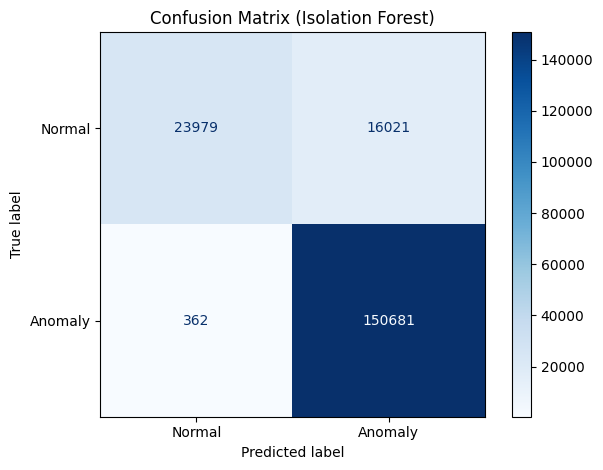


=== AUC-ROC Score (Isolation Forest) ===
AUC-ROC: 0.7843


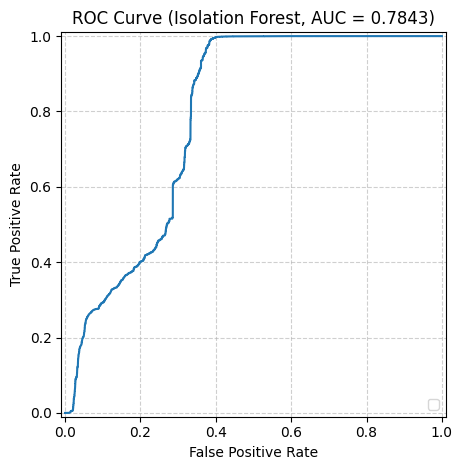


=== Precision-Recall AUC (Isolation Forest) ===
Average Precision (AUC-PR): 0.8957


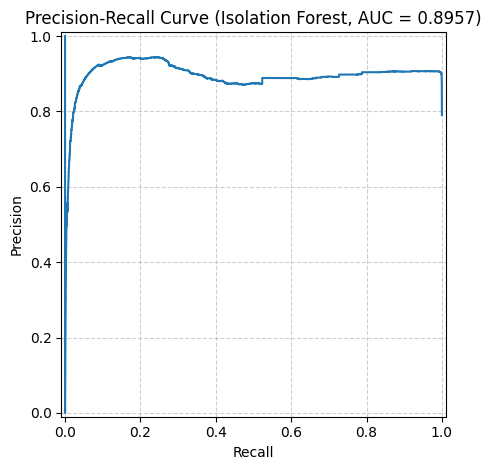


Plotting score distribution...


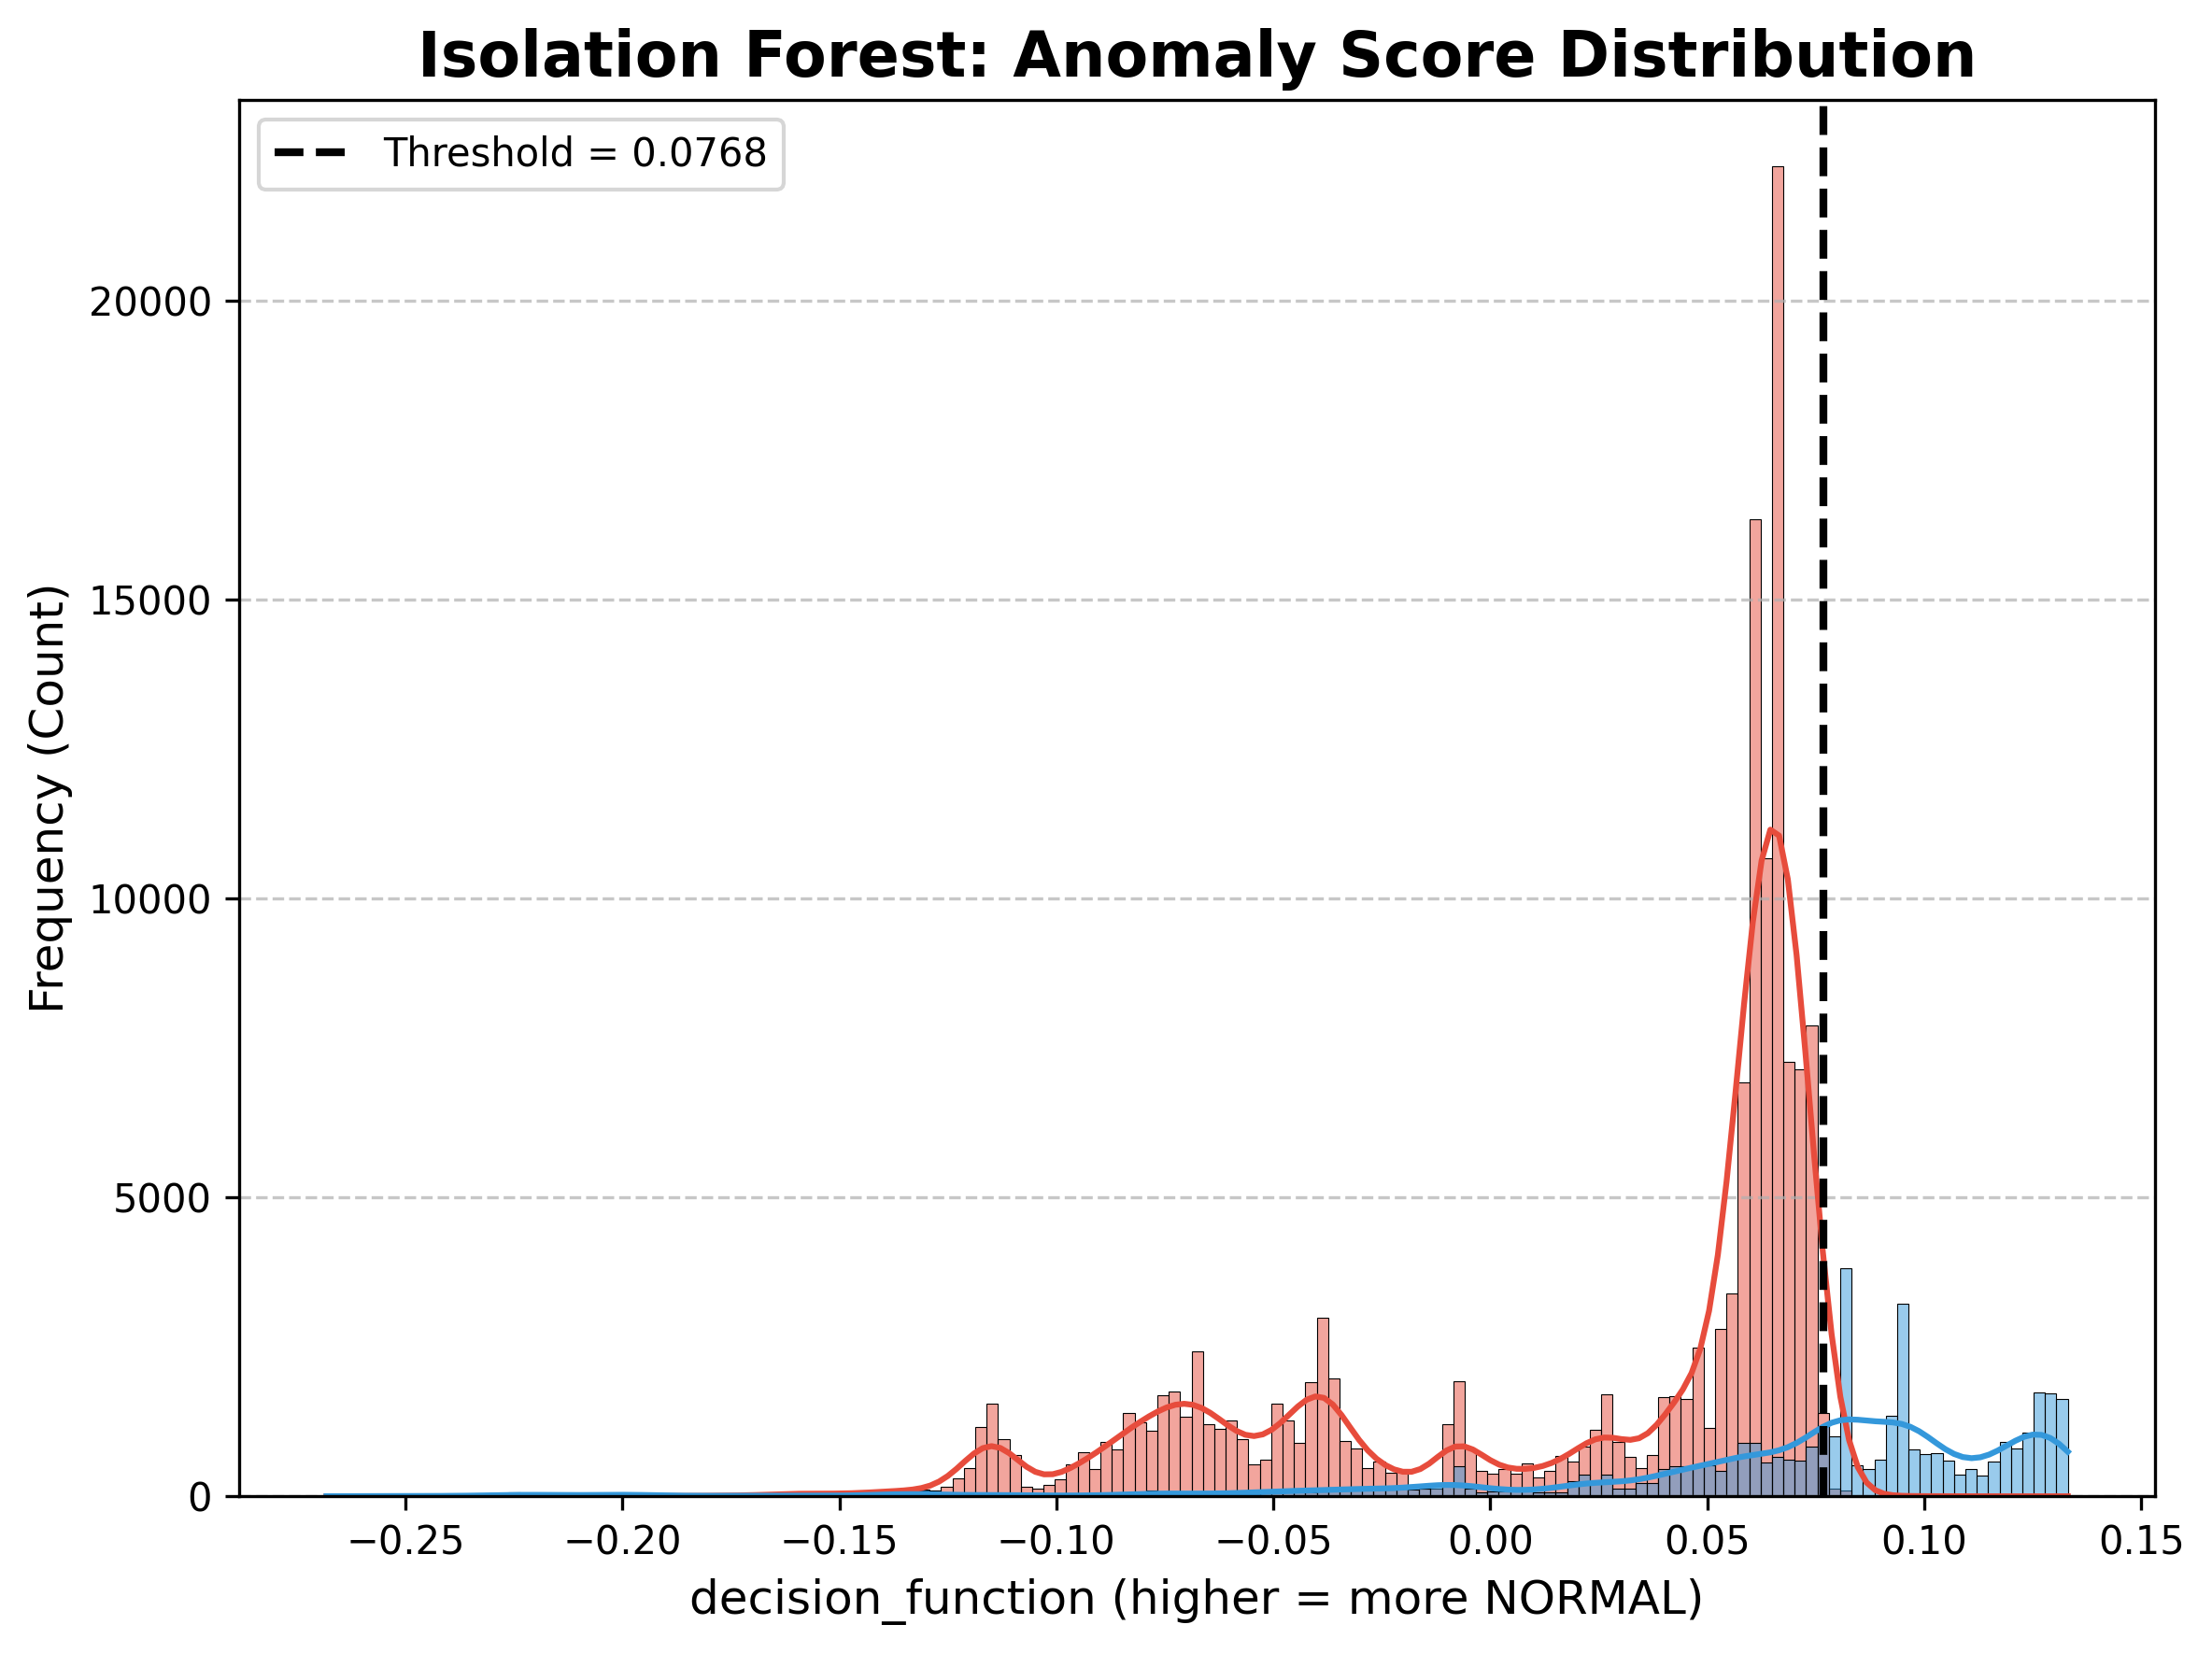


Generating additional visualizations (MATLAB-inspired)...


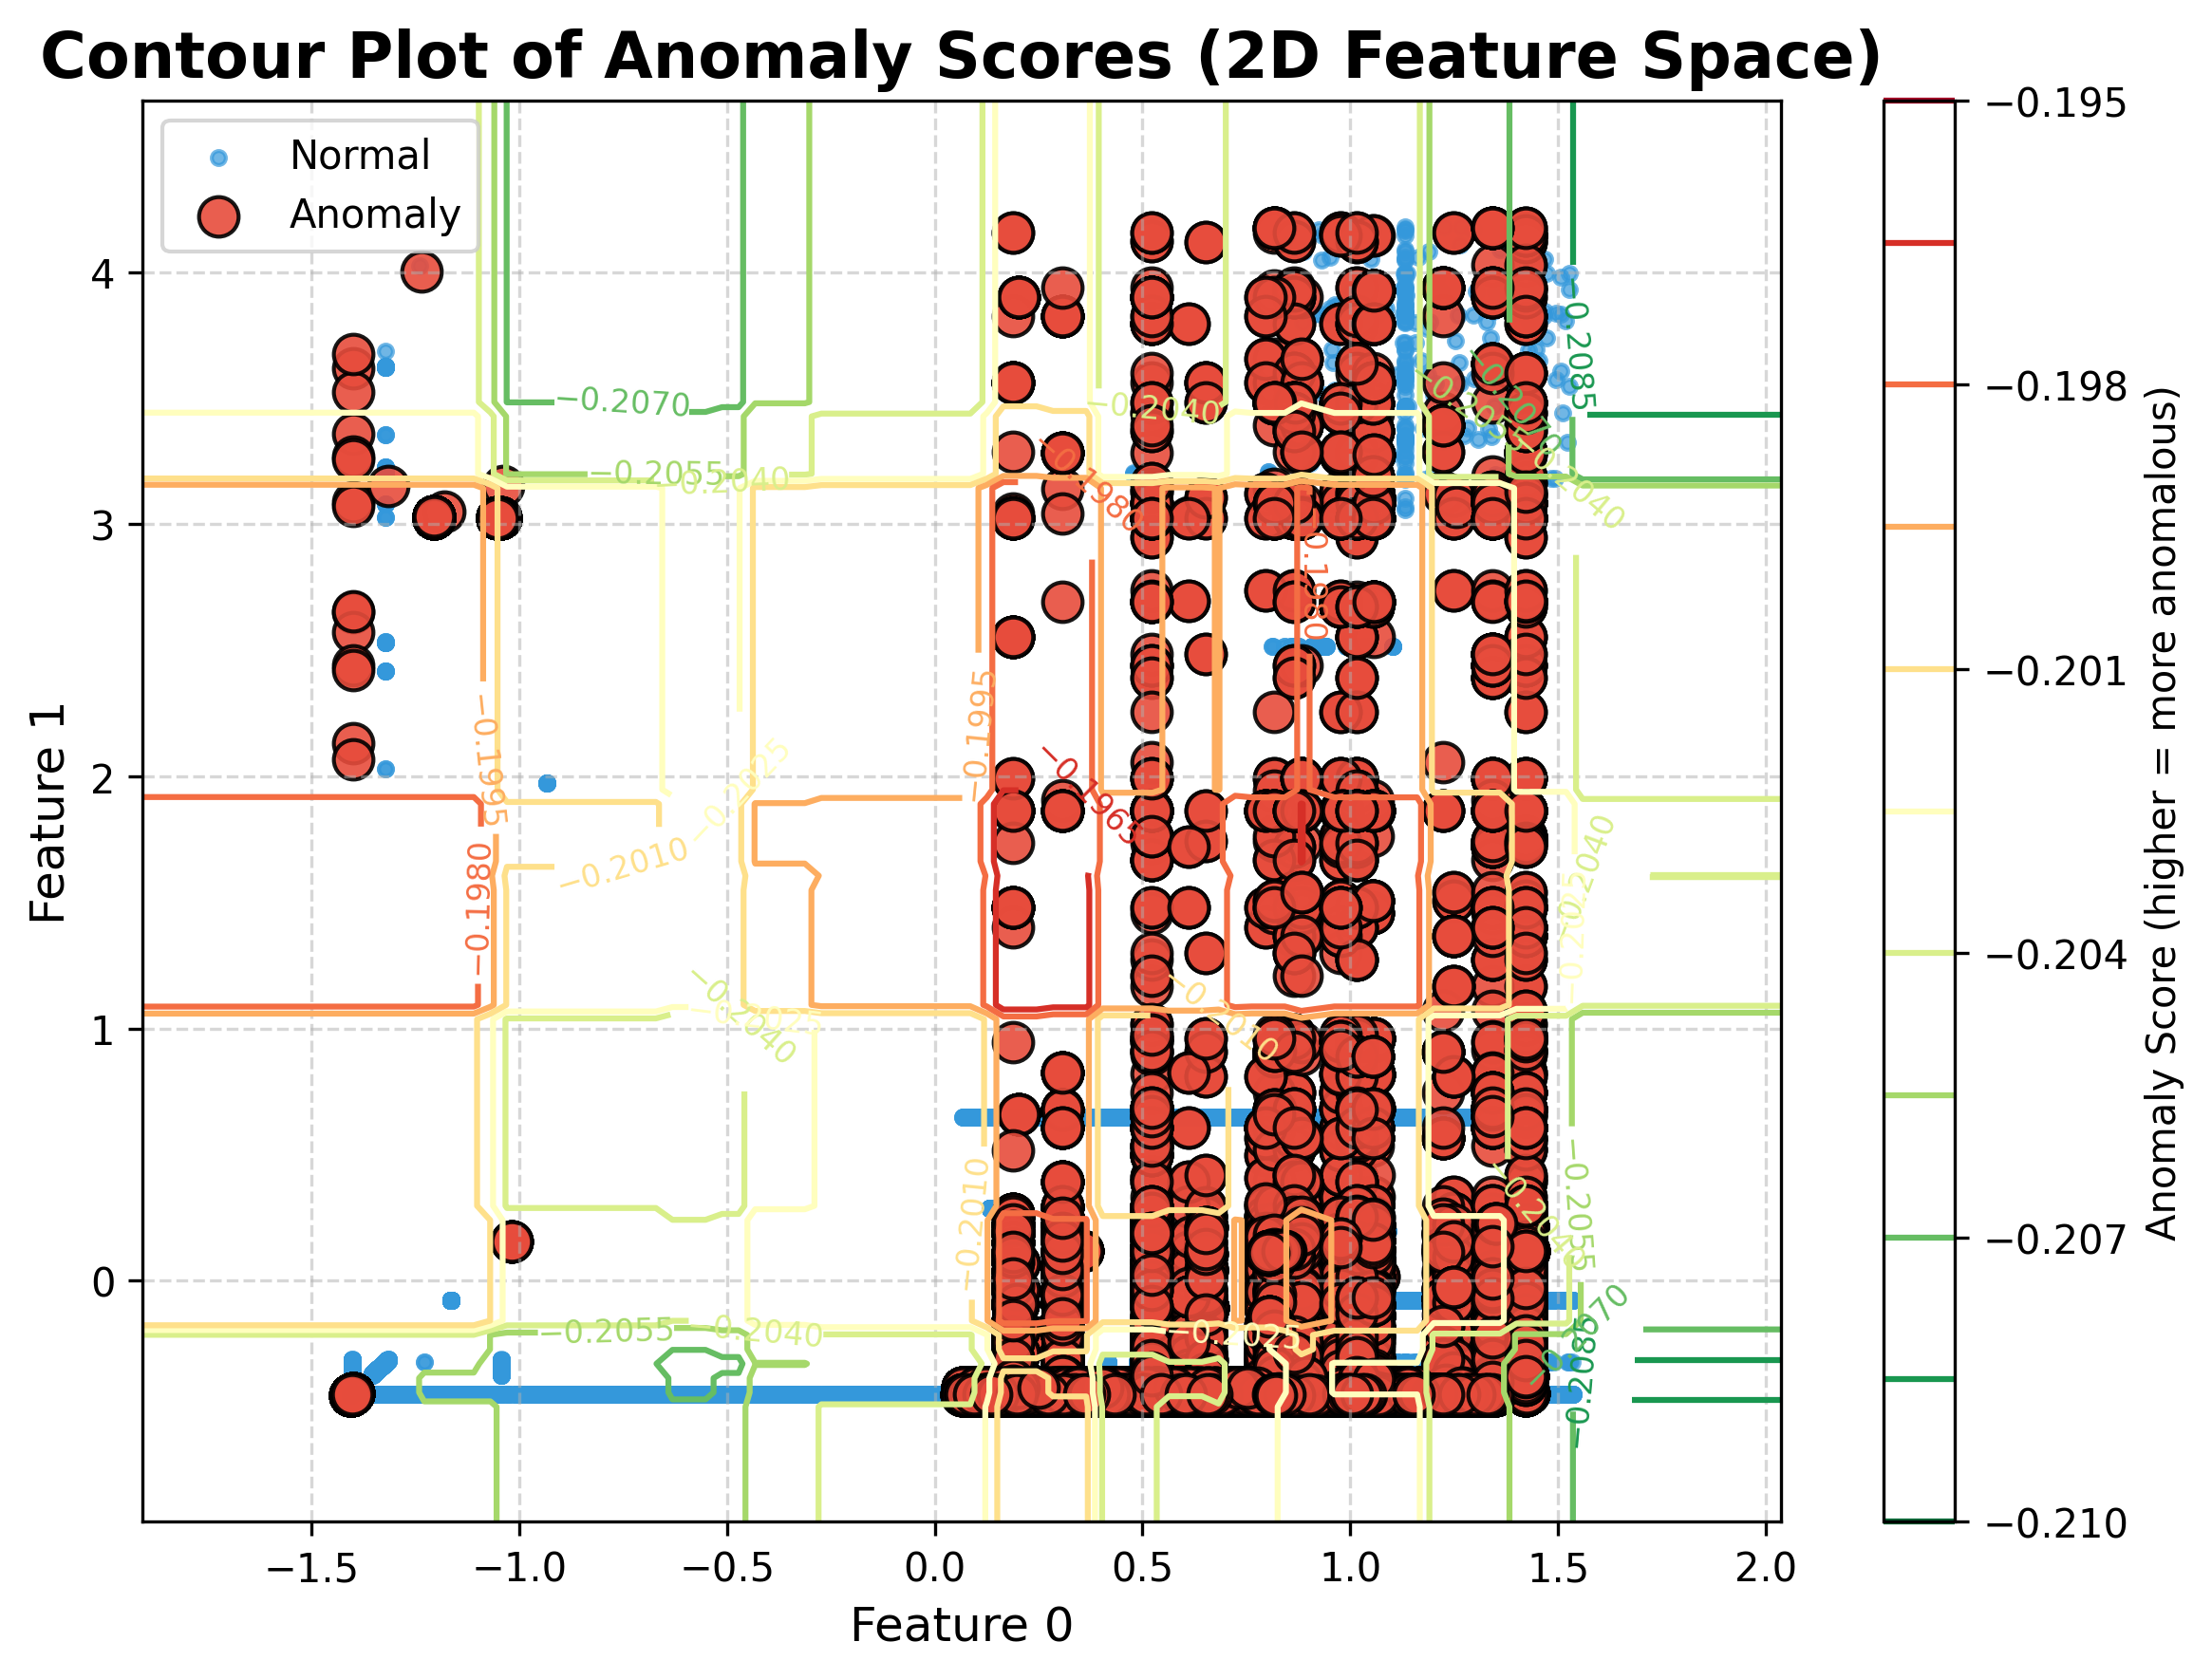

/tmp/ipython-input-3538770298.py:121: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_scores, x='Type', y='Score', ax=ax2, palette=['#3498db', '#e74c3c'])


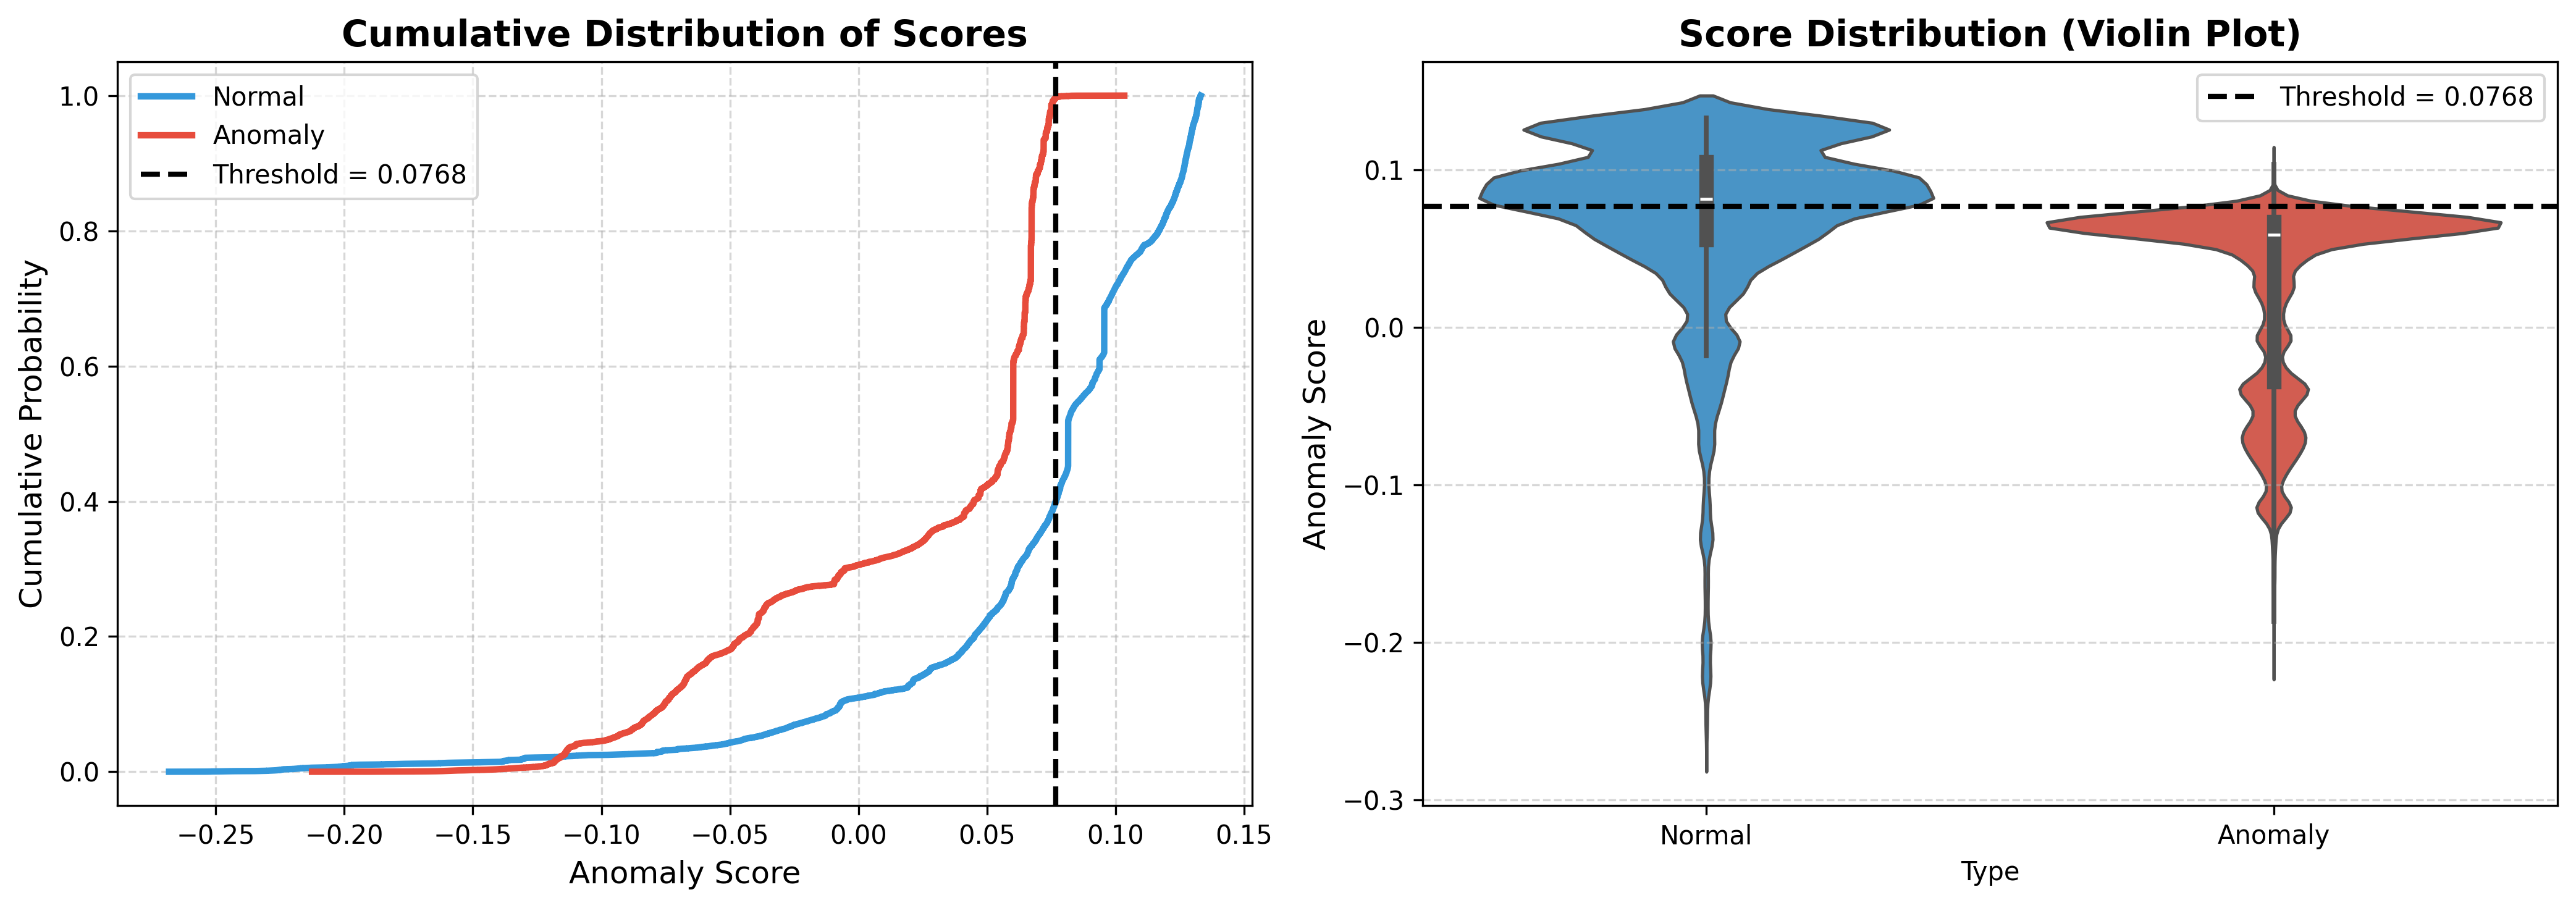


 ALL VISUALIZATIONS COMPLETE


In [ ]:
# === Isolation Forest (standalone, uses test_df directly) ===
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import roc_auc_score, roc_curve, RocCurveDisplay
from sklearn.metrics import precision_recall_curve, average_precision_score, PrecisionRecallDisplay
from sklearn.decomposition import PCA
from sklearn.manifold import TSNE


# ---------- helper: plot of IF scores ----------
def plot_if_scores(scores, labels, threshold, save_path="if_score_distribution.pdf"):
    results_df = pd.DataFrame({'score': scores, 'label': labels})
    plt.figure(figsize=(8,6), dpi=300)
    sns.histplot(data=results_df, x='score', hue='label', kde=True,
                 palette={0: '#3498db', 1: '#e74c3c'})
    plt.title('Isolation Forest: Anomaly Score Distribution', fontsize=16, weight='bold')
    plt.xlabel('decision_function (higher = more NORMAL)', fontsize=12)
    plt.ylabel('Frequency (Count)', fontsize=12)
    plt.axvline(threshold, color='black', linestyle='--', linewidth=2,
                label=f'Threshold = {threshold:.4f}')
    plt.legend()
    plt.grid(axis='y', linestyle='--', alpha=0.7)
    plt.tight_layout()
    plt.savefig(save_path, format='pdf')
    plt.show()


# ---------- Contour plot of anomaly scores (for 2D visualization) ----------
def plot_anomaly_score_contour(model, X_test, scores, labels, feature_idx=[0, 1],
                                save_path="if_contour_plot.pdf"):
    """
    Creates a contour plot of anomaly scores for 2D feature space visualization.
    feature_idx: indices of two features to plot
    """
    if X_test.shape[1] < 2:
        print("Skipping contour plot: need at least 2 features")
        return

    # Create a grid for contour plot
    x_min, x_max = X_test[:, feature_idx[0]].min() - 0.5, X_test[:, feature_idx[0]].max() + 0.5
    y_min, y_max = X_test[:, feature_idx[1]].min() - 0.5, X_test[:, feature_idx[1]].max() + 0.5

    xx, yy = np.meshgrid(np.linspace(x_min, x_max, 100),
                         np.linspace(y_min, y_max, 100))

    # Prepare grid points with all features
    grid_points = np.c_[xx.ravel(), yy.ravel()]
    if X_test.shape[1] > 2:
        # Pad with zeros for other dimensions
        padding = np.zeros((grid_points.shape[0], X_test.shape[1] - 2))
        grid_points = np.hstack([grid_points, padding])

    # Score grid points
    Z = model.decision_function(grid_points)
    Z = Z.reshape(xx.shape)

    # Plot
    plt.figure(figsize=(8, 6), dpi=300)

    # Scatter plot of test data
    normal_mask = labels == 0
    anomaly_mask = labels == 1

    plt.scatter(X_test[normal_mask, feature_idx[0]], X_test[normal_mask, feature_idx[1]],
                c='#3498db', marker='.', s=50, label='Normal', alpha=0.7)
    plt.scatter(X_test[anomaly_mask, feature_idx[0]], X_test[anomaly_mask, feature_idx[1]],
                c='#e74c3c', marker='o', s=100, label='Anomaly', alpha=0.9, edgecolors='black')

    # Contour plot of anomaly scores
    contour = plt.contour(xx, yy, Z, levels=10, cmap='RdYlGn_r', linewidths=1.5)
    plt.clabel(contour, inline=True, fontsize=8)
    plt.colorbar(contour, label='Anomaly Score (higher = more anomalous)')

    plt.title('Contour Plot of Anomaly Scores (2D Feature Space)', fontsize=16, weight='bold')
    plt.xlabel(f'Feature {feature_idx[0]}', fontsize=12)
    plt.ylabel(f'Feature {feature_idx[1]}', fontsize=12)
    plt.legend()
    plt.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig(save_path, format='pdf')
    plt.show()


# ---------- Cumulative score distribution ----------
def plot_cumulative_score_distribution(scores, labels, threshold,
                                       save_path="if_cumulative_distribution.pdf"):
    """
    Plots cumulative distribution of anomaly scores.
    """
    normal_scores = scores[labels == 0]
    anomaly_scores = scores[labels == 1]

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5), dpi=300)

    # Cumulative distribution
    sorted_normal = np.sort(normal_scores)
    sorted_anomaly = np.sort(anomaly_scores)

    ax1.plot(sorted_normal, np.arange(1, len(sorted_normal) + 1) / len(sorted_normal),
             label='Normal', linewidth=2.5, color='#3498db')
    ax1.plot(sorted_anomaly, np.arange(1, len(sorted_anomaly) + 1) / len(sorted_anomaly),
             label='Anomaly', linewidth=2.5, color='#e74c3c')
    ax1.axvline(threshold, color='black', linestyle='--', linewidth=2, label=f'Threshold = {threshold:.4f}')
    ax1.set_xlabel('Anomaly Score', fontsize=12)
    ax1.set_ylabel('Cumulative Probability', fontsize=12)
    ax1.set_title('Cumulative Distribution of Scores', fontsize=14, weight='bold')
    ax1.legend()
    ax1.grid(True, linestyle='--', alpha=0.5)

    # Violin plot for better distribution visualization
    df_scores = pd.DataFrame({
        'Score': np.concatenate([normal_scores, anomaly_scores]),
        'Type': ['Normal'] * len(normal_scores) + ['Anomaly'] * len(anomaly_scores)
    })

    sns.violinplot(data=df_scores, x='Type', y='Score', ax=ax2, palette=['#3498db', '#e74c3c'])
    ax2.axhline(threshold, color='black', linestyle='--', linewidth=2, label=f'Threshold = {threshold:.4f}')
    ax2.set_title('Score Distribution (Violin Plot)', fontsize=14, weight='bold')
    ax2.set_ylabel('Anomaly Score', fontsize=12)
    ax2.legend()
    ax2.grid(axis='y', linestyle='--', alpha=0.5)

    plt.tight_layout()
    plt.savefig(save_path, format='pdf')
    plt.show()


print("\n" + "="*50)
print(" ISOLATION FOREST MODEL TRAINING AND EVALUATION (Enhanced)")
print("="*50)


# --------- ensure prerequisites ----------
# 1) normal_train_df
if 'normal_train_df' not in globals():
    if 'train_df' not in globals():
        raise RuntimeError("train_df is not defined. Run your split cell first.")
    normal_train_df = train_df[train_df['label'] == 0]


# 2) preprocessor
if 'preprocessor' not in globals():
    try:
        preprocessor, scaler, _ = get_preprocessor(normal_train_df)
    except NameError as e:
        raise RuntimeError("preprocessor not found and get_preprocessor is not defined. "
                           "Run your preprocessing cell first.") from e


# 3) test_df
if 'test_df' not in globals():
    raise RuntimeError("test_df is not defined. Run your split cell first.")


# ---------- Prepare flat (non-windowed) matrices ----------
print("\nPreparing flat (non-windowed) data for Isolation Forest...")
X_train_if_features = normal_train_df.drop(columns=['label', 'type'], errors='ignore')
X_train_if = preprocessor.transform(X_train_if_features)


X_test_if_features = test_df.drop(columns=['label', 'type'], errors='ignore')
X_test_if = preprocessor.transform(X_test_if_features)
y_test_if = test_df['label'].values.astype(int)


# ---------- Train Isolation Forest on NORMAL rows ----------
print("\nTraining Isolation Forest on normal rows...")
if_model = IsolationForest(n_estimators=100, max_samples='auto', random_state=42, n_jobs=-1)
if_model.fit(X_train_if)
print("Isolation Forest training complete.")


# ---------- Scores & threshold ----------
print("\nScoring train/test with decision_function (higher = more NORMAL)...")
train_scores_if = if_model.decision_function(X_train_if)
test_scores_if  = if_model.decision_function(X_test_if)


THRESH_PCTL = 40
threshold_if = np.percentile(train_scores_if, THRESH_PCTL)
print(f"Anomaly threshold (percentile {THRESH_PCTL}) = {threshold_if:.6f}")


# Predict anomaly if score < threshold
y_pred_if = (test_scores_if < threshold_if).astype(int)


# ---------- Metrics ----------
print("\n=== Classification Report (Isolation Forest on test_df) ===")
print(classification_report(y_test_if, y_pred_if, target_names=['Normal','Anomaly'], zero_division=0))


print("\n=== Confusion Matrix (Isolation Forest) ===")
cm_if = confusion_matrix(y_test_if, y_pred_if)
disp_if = ConfusionMatrixDisplay(confusion_matrix=cm_if, display_labels=['Normal','Anomaly'])
disp_if.plot(cmap=plt.cm.Blues)
plt.title('Confusion Matrix (Isolation Forest)')
plt.tight_layout()
plt.savefig("if_confusion_matrix.pdf", format='pdf')
plt.show()


# === AUC-ROC SCORE ===
auc_if = roc_auc_score(y_test_if, -test_scores_if)
print(f"\n=== AUC-ROC Score (Isolation Forest) ===")
print(f"AUC-ROC: {auc_if:.4f}")


fpr, tpr, thresholds = roc_curve(y_test_if, -test_scores_if)
RocCurveDisplay(fpr=fpr, tpr=tpr).plot()
plt.title(f'ROC Curve (Isolation Forest, AUC = {auc_if:.4f})')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("if_roc_curve.pdf", format='pdf')
plt.show()


# === PRECISION-RECALL AUC ===
pr_precision, pr_recall, pr_thresholds = precision_recall_curve(y_test_if, -test_scores_if)
pr_auc = average_precision_score(y_test_if, -test_scores_if)
print(f"\n=== Precision-Recall AUC (Isolation Forest) ===")
print(f"Average Precision (AUC-PR): {pr_auc:.4f}")


PrecisionRecallDisplay(precision=pr_precision, recall=pr_recall).plot()
plt.title(f'Precision-Recall Curve (Isolation Forest, AUC = {pr_auc:.4f})')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig("if_precision_recall_curve.pdf", format='pdf')
plt.show()


# ---------- Score distribution plot ----------
print("\nPlotting score distribution...")
plot_if_scores(test_scores_if, y_test_if, threshold_if, save_path="if_score_distribution.pdf")


# ---------- PLOTS ----------
print("\nGenerating additional visualizations (MATLAB-inspired)...")

# Contour plot (works for 2D feature space or first 2 principal components)
try:
    plot_anomaly_score_contour(if_model, X_test_if, test_scores_if, y_test_if,
                              feature_idx=[0, 1], save_path="if_contour_plot.pdf")
except Exception as e:
    print(f"Contour plot skipped: {e}")


# Cumulative distribution
try:
    plot_cumulative_score_distribution(test_scores_if, y_test_if, threshold_if,
                                      save_path="if_cumulative_distribution.pdf")
except Exception as e:
    print(f"Cumulative distribution skipped: {e}")


print("\n" + "="*50)
print(" ALL VISUALIZATIONS COMPLETE")
print("="*50)

### RL

/usr/local/lib/python3.12/dist-packages/numpy/_core/fromnumeric.py:57: FutureWarning: 'DataFrame.swapaxes' is deprecated and will be removed in a future version. Please use 'DataFrame.transpose' instead.
  return bound(*args, **kwds)


Original test_df size: 191043 | normals: 40000
Modified test_df_uniform size: 191043 | normals: 40000
Train windows: total=19976, Normal=9980 (49.96%), Anomaly=9996 (50.04%)
Test windows: total=191019, Normal=40000 (20.94%), Anomaly=151019 (79.06%)
SNN (train/test): (19976,) (191019,)
IF  (train/test): (19976,) (191019,)
y   (train/test): (19976,) (191019,)

 Created variables for RL (stride=1).

Training DQN (stride=1) with cost-aware env...
[DQN] Ep 10/300 | trainR=-277.97 | eval acc=0.957 | eval avgR=2.945 | eps=0.951
[DQN] Ep 20/300 | trainR=191.09 | eval acc=0.965 | eval avgR=3.867 | eps=0.905
[DQN] Ep 30/300 | trainR=369.51 | eval acc=1.000 | eval avgR=4.347 | eps=0.860
[DQN] Ep 40/300 | trainR=-182.65 | eval acc=0.992 | eval avgR=4.323 | eps=0.818
[DQN] Ep 50/300 | trainR=-265.52 | eval acc=0.969 | eval avgR=3.706 | eps=0.778
[DQN] Ep 60/300 | trainR=-120.00 | eval acc=0.934 | eval avgR=2.758 | eps=0.740
[DQN] Ep 70/300 | trainR=-103.95 | eval acc=0.996 | eval avgR=3.028 | eps=0

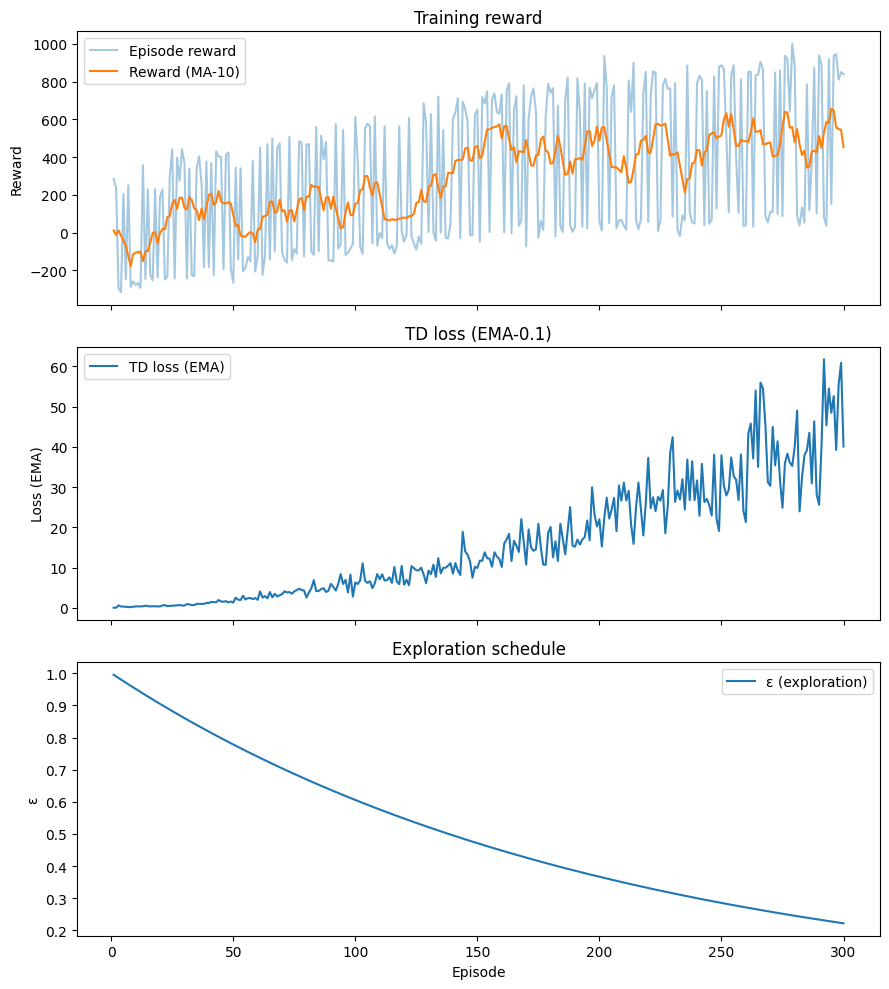

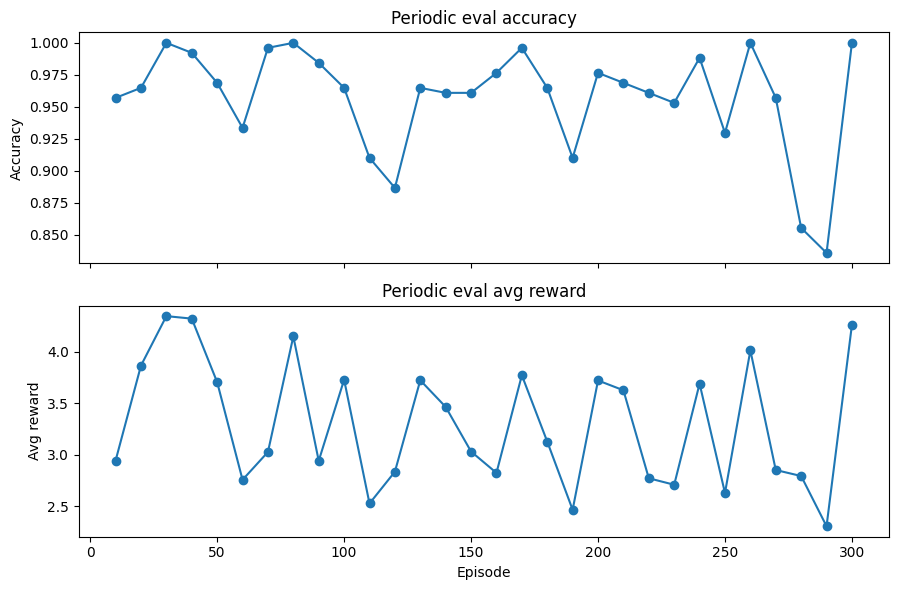


=== Deterministic full-pass report (Safety Valve applied) ===
              precision    recall  f1-score   support

      Normal       0.94      0.90      0.92     40000
     Anomaly       0.97      0.98      0.98    151019

    accuracy                           0.97    191019
   macro avg       0.96      0.94      0.95    191019
weighted avg       0.97      0.97      0.97    191019

3.570820312500001
2.6046875
0.9434778306040963


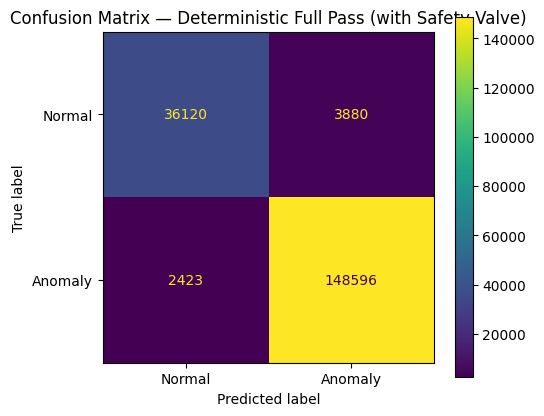

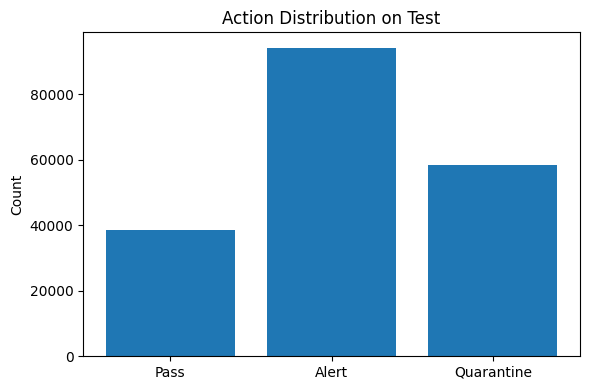

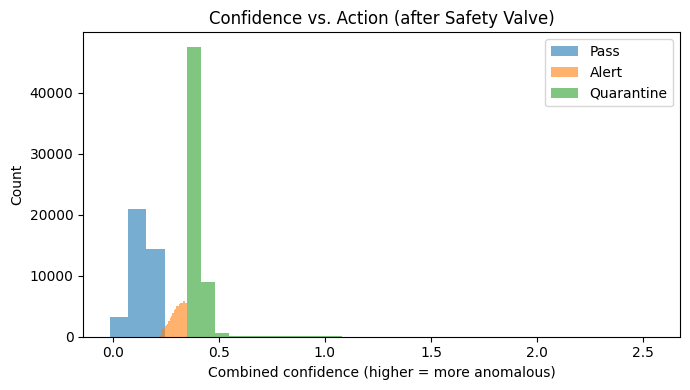


 Done. Bias controls applied (env shaping + safety valve). If Quarantine is still too frequent, increase QUAR_COST_STEP or CONF_PENALTY_LO, or raise SV_CONF_HI.
 Done. Training & testing plots generated (reward, TD-loss, ε, periodic eval accuracy/avgR, confusion matrix, action distribution).


In [ ]:

# STRIDE=1 RL pipeline + anti-quarantine bias controls
# + DQN training logger & the requested plots only
# (Training reward, TD-loss EMA, epsilon, periodic eval accuracy & avg reward)

# ---------------- CONFIG ----------------
WINDOW_SIZE      = 25
STRIDE           = 1
BATCH_SIZE       = 128
N_EPISODES       = 300
LR               = 1e-3
GAMMA            = 0.99
EPS_START        = 1.0
EPS_FINAL        = 0.05
EPS_DECAY        = 0.995
TARGET_UPDATE    = 10
EPISODE_LEN      = 256           # None => run to end

# Window labeling:
LABEL_MODE_TRAIN = "proportion"  # "proportion" or "center"
PROP_THRESHOLD   = 0.20
LABEL_MODE_TEST  = "center"      # prevents bleed-over

# Test redistribution (uniform normals):
NORMAL_BLOCK_SIZE = 100

# Env knobs
ENV_R_ANOM_PASS   = -3.0
ENV_R_ANOM_ALERT  = +1.2
ENV_R_ANOM_QUAR   = +3.8
ENV_R_NORM_PASS   = +1.0
ENV_R_NORM_ALERT  = -2.5
ENV_R_NORM_QUAR   = -1.8
ALERT_COST_STEP   = -0.02
QUAR_COST_STEP    = -0.01

# Confidence shaping
HI_THR            = 0.35
LO_THR            = 0.20

CONF_BONUS_HI     = +1.20
CONF_PENALTY_LO   = -0.10

# Anti-spam / cooldown
STREAK_WINDOW     = 50
STREAK_WARN_RATIO = 0.85
Q_STREAK_PENALTY  = -0.01
USE_COOLDOWN      = False
COOLDOWN_RATIO    = 0.90
COOLDOWN_PENALTY  = -0.05

# Safety valve (used for deterministic full-pass)
SV_CONF_HI        = 0.35
SV_CONF_LO        = 0.20

# ---------------- IMPORTS ----------------
import numpy as np
import pandas as pd
import math, collections
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset

from sklearn.preprocessing import MinMaxScaler
from sklearn.ensemble import IsolationForest
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- SANITY: required objects ----------------
_needed = ['train_df', 'test_df', 'preprocessor', 'model','if_model']
_missing = [k for k in _needed if k not in globals()]
if _missing:
    raise RuntimeError("Missing required variables: " + ", ".join(_missing))


# 0) Redistribute all Normal rows in test uniformly in 100-row blocks

def redistribute_normals_uniform(test_df: pd.DataFrame, block_size: int = 100, random_state: int = 42) -> pd.DataFrame:
    if 'label' not in test_df.columns:
        raise ValueError("test_df must contain a 'label' column (0/1).")
    anoms = test_df[test_df['label'] == 1].copy()
    normals = test_df[test_df['label'] == 0].copy()
    n_norm = len(normals)
    if n_norm == 0:
        return test_df.copy()
    normals = normals.sample(frac=1.0, random_state=random_state).reset_index(drop=True)
    num_blocks = math.ceil(n_norm / block_size)
    blocks = [normals.iloc[i*block_size:(i+1)*block_size].reset_index(drop=True) for i in range(num_blocks)]
    chunks = np.array_split(anoms.reset_index(drop=True), num_blocks + 1)
    mixed = []
    for i in range(num_blocks):
        mixed.append(chunks[i]); mixed.append(blocks[i])
    mixed.append(chunks[-1])
    new_test = pd.concat(mixed, axis=0).reset_index(drop=True)
    assert (new_test['label'] == 0).sum() == (test_df['label'] == 0).sum()
    assert (new_test['label'] == 1).sum() == (test_df['label'] == 1).sum()
    assert len(new_test) == len(test_df)
    return new_test

test_df_uniform = redistribute_normals_uniform(test_df, block_size=NORMAL_BLOCK_SIZE, random_state=42)
print("Original test_df size:", len(test_df), "| normals:", int((test_df['label']==0).sum()))
print("Modified test_df_uniform size:", len(test_df_uniform), "| normals:", int((test_df_uniform['label']==0).sum()))


# 1) Preprocessing + STRIDE=1 windowing

def apply_preprocessing_and_windowing(df: pd.DataFrame, preprocessor, scaler=None,
                                      window_size: int = 64, stride: int = 1,
                                      label_mode: str = "proportion", prop_threshold: float = 0.2):
    if 'label' not in df.columns:
        raise ValueError("Expected 'label' column (0/1).")
    y_rows = df['label'].to_numpy(dtype=int)
    X_rows = df.drop(columns=['label', 'type'], errors='ignore')
    X_rows = preprocessor.transform(X_rows)
    X_rows = np.asarray(X_rows, dtype=np.float32)
    if scaler is not None:
        X_rows = scaler.transform(X_rows).astype(np.float32)
    n = X_rows.shape[0]
    if n < window_size:
        raise ValueError(f"Not enough rows ({n}) for window_size={window_size}.")
    starts = range(0, n - window_size + 1, stride)
    X_win = np.stack([X_rows[s:s+window_size, :] for s in starts], axis=0)
    if label_mode == "proportion":
        y_win = np.array([(y_rows[s:s+window_size].mean() >= prop_threshold).astype(int) for s in starts], dtype=int)
    elif label_mode == "center":
        half = window_size // 2
        y_win = np.array([y_rows[s + half] for s in starts], dtype=int)
    else:
        raise ValueError("label_mode must be 'proportion' or 'center'.")
    return X_win, y_win

if 'train_df_sorted' not in globals():
    train_df_sorted = train_df.sort_values(by='label').reset_index(drop=True)
test_df_structured = test_df_uniform.copy()

X_train_win_all, y_train_win_all = apply_preprocessing_and_windowing(
    train_df_sorted, preprocessor, scaler=None,
    window_size=WINDOW_SIZE, stride=STRIDE,
    label_mode=LABEL_MODE_TRAIN, prop_threshold=PROP_THRESHOLD
)
X_test_win, y_test_win = apply_preprocessing_and_windowing(
    test_df_structured, preprocessor, scaler=None,
    window_size=WINDOW_SIZE, stride=STRIDE,
    label_mode=LABEL_MODE_TEST, prop_threshold=PROP_THRESHOLD
)

def _describe(y, name):
    uniq, cnt = np.unique(y, return_counts=True)
    d = dict(zip(uniq, cnt)); n = len(y)
    print(f"{name}: total={n}, Normal={d.get(0,0)} ({100*d.get(0,0)/n:.2f}%), Anomaly={d.get(1,0)} ({100*d.get(1,0)/n:.2f}%)")
_describe(y_train_win_all, "Train windows")
_describe(y_test_win,  "Test windows")


# 2) SNN scoring (deterministic Poisson)

def make_fixed_poisson(x_tensor: torch.Tensor, seed: int = 0) -> torch.Tensor:
    with torch.random.fork_rng():
        torch.manual_seed(seed)
        T = x_tensor.shape[1]
        return torch.stack(
            [(torch.rand_like(x_tensor[:, t, :]) < x_tensor[:, t, :]).float() for t in range(T)],
            dim=1
        )

@torch.no_grad()
def anomaly_scores_snn(model, loader, device: str | torch.device = "cpu", seed: int = 0):
    model.eval()
    scores, outs = [], []
    for (x_batch,) in loader:
        x_batch = x_batch.to(device)
        poi_spikes = make_fixed_poisson(x_batch, seed=seed).to(device)
        out_spk = model(x_batch, pre_spikes=poi_spikes)
        err = torch.mean((out_spk.sum(dim=1) - x_batch.sum(dim=1)).abs(), dim=1)  # (B,)
        scores.extend(err.detach().cpu().numpy())
        outs.append(out_spk.detach().cpu())
    return np.array(scores), (torch.cat(outs, dim=0) if outs else torch.empty(0))

train_all_loader = DataLoader(TensorDataset(torch.tensor(X_train_win_all, dtype=torch.float32)), batch_size=BATCH_SIZE, shuffle=False)
test_loader      = DataLoader(TensorDataset(torch.tensor(X_test_win,      dtype=torch.float32)), batch_size=BATCH_SIZE, shuffle=False)

train_scores_snn_all, _ = anomaly_scores_snn(model, train_all_loader, device=device, seed=0)
test_scores_snn, _      = anomaly_scores_snn(model, test_loader,      device=device, seed=0)


# 3) IF row-level -> window means (stride=1)

def window_mean_scores(flat_scores: np.ndarray, window_size: int, stride: int, n_rows: int) -> np.ndarray:
    out = []
    for s in range(0, n_rows - window_size + 1, stride):
        out.append(float(np.mean(flat_scores[s:s+window_size])))
    return np.array(out, dtype=float)

if 'if_model' not in globals():
    normal_train_df = train_df[train_df['label'] == 0]
    X_norm = normal_train_df.drop(columns=['label', 'type'], errors='ignore')
    X_norm = preprocessor.transform(X_norm)
    if_model = IsolationForest(n_estimators=100, random_state=42, n_jobs=-1)
    if_model.fit(X_norm)

X_train_rows_if = preprocessor.transform(train_df_sorted.drop(columns=['label', 'type'], errors='ignore'))
X_test_rows_if  = preprocessor.transform(test_df_structured.drop(columns=['label', 'type'], errors='ignore'))

train_if_flat_raw = -if_model.decision_function(X_train_rows_if)
test_if_flat_raw  = -if_model.decision_function(X_test_rows_if)

from sklearn.preprocessing import MinMaxScaler as _MM
_if_row_scaler = _MM().fit(train_if_flat_raw.reshape(-1,1))
train_if_flat  = _MM().fit_transform(train_if_flat_raw.reshape(-1,1)).squeeze()  # keep same scaling behavior
test_if_flat   = _if_row_scaler.transform(test_if_flat_raw.reshape(-1,1)).squeeze()

train_if_win_all   = window_mean_scores(train_if_flat, WINDOW_SIZE, STRIDE, n_rows=len(train_df_sorted))
test_if_win_scores = window_mean_scores(test_if_flat,  WINDOW_SIZE, STRIDE, n_rows=len(test_df_structured))

print("SNN (train/test):", train_scores_snn_all.shape, test_scores_snn.shape)
print("IF  (train/test):", train_if_win_all.shape,     test_if_win_scores.shape)
print("y   (train/test):", y_train_win_all.shape,      y_test_win.shape)
assert train_scores_snn_all.shape[0] == train_if_win_all.shape[0] == y_train_win_all.shape[0]
assert test_scores_snn.shape[0] == test_if_win_scores.shape[0] == y_test_win.shape[0]
print("\n Created variables for RL (stride=1).")


# 4) DQN + Env
class ReplayBuffer:
    def __init__(self, capacity=50000):
        self.capacity = capacity; self.buffer = []; self.pos = 0
    def push(self, s,a,r,ns,d):
        if len(self.buffer) < self.capacity: self.buffer.append(None)
        self.buffer[self.pos] = (s,a,r,ns,d); self.pos = (self.pos+1) % self.capacity
    def sample(self, batch_size):
        import random
        b = random.sample(self.buffer, batch_size)
        s,a,r,ns,d = map(np.stack, zip(*b))
        return s,a,r,ns,d
    def __len__(self): return len(self.buffer)

class DQN(nn.Module):
    def __init__(self, in_dim=2, n_actions=3, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions)
        )
    def forward(self, x): return self.net(x)

# Actions: 0=Pass, 1=Alert, 2=Quarantine
class WindowDecisionEnv:
    def __init__(self, states: np.ndarray, labels: np.ndarray,
                 random_start: bool = True, episode_len: int | None = EPISODE_LEN,
                 r_anom_pass=ENV_R_ANOM_PASS, r_anom_alert=ENV_R_ANOM_ALERT, r_anom_quar=ENV_R_ANOM_QUAR,
                 r_norm_pass=ENV_R_NORM_PASS, r_norm_alert=ENV_R_NORM_ALERT, r_norm_quar=ENV_R_NORM_QUAR,
                 alert_cost_step=ALERT_COST_STEP, quarantine_cost_step=QUAR_COST_STEP,
                 use_confidence=True, hi_thr=HI_THR, lo_thr=LO_THR,
                 conf_bonus_hi=CONF_BONUS_HI, conf_penalty_lo=CONF_PENALTY_LO,
                 streak_window=STREAK_WINDOW, streak_warn_ratio=STREAK_WARN_RATIO, quarantine_streak_penalty=Q_STREAK_PENALTY,
                 use_cooldown=USE_COOLDOWN, cooldown_ratio=COOLDOWN_RATIO, cooldown_penalty=COOLDOWN_PENALTY):
        self.states = states.astype(np.float32)
        self.labels = labels.astype(int)
        self.n = len(self.states)
        self.random_start = random_start
        self.episode_len_default = episode_len
        self.r_anom = {0:r_anom_pass, 1:r_anom_alert, 2:r_anom_quar}
        self.r_norm = {0:r_norm_pass, 1:r_norm_alert, 2:r_norm_quar}
        self.alert_cost_step = alert_cost_step
        self.quarantine_cost_step = quarantine_cost_step
        self.use_confidence = use_confidence
        self.hi_thr = hi_thr; self.lo_thr = lo_thr
        self.conf_bonus_hi = conf_bonus_hi; self.conf_penalty_lo = conf_penalty_lo
        self.streak_window = streak_window; self.streak_warn_ratio = streak_warn_ratio
        self.quarantine_streak_penalty = quarantine_streak_penalty
        self.use_cooldown = use_cooldown; self.cooldown_ratio = cooldown_ratio; self.cooldown_penalty = cooldown_penalty
        self.i = 0; self.steps_left = None; self.recent_actions = []

    # def _conf(self, s):
    #     return 0.5*float(s[0]) + 0.5*float(s[1])

    def _conf(self, s):
        if len(s) == 1:
            self.confidence_rule = "1D"
            return float(s[0])
        elif len(s) >= 2:
            self.confidence_rule = "2D_avg"
            return 0.5 * float(s[0]) + 0.5 * float(s[1])
        else:
            self.confidence_rule = "empty"
            return 0.0

    def reset(self):
        import random
        self.i = random.randrange(0, max(1, self.n - 1)) if self.random_start and self.n > 1 else 0
        self.steps_left = self.episode_len_default
        self.recent_actions.clear()
        return self.states[self.i]

    def _recent_quarantine_ratio(self):
        if not self.recent_actions: return 0.0
        q = sum(1 for a in self.recent_actions if a == 2)
        return q / len(self.recent_actions)

    def step(self, action: int):
        y = int(self.labels[self.i]); s = self.states[self.i]
        base = self.r_anom[action] if y == 1 else self.r_norm[action]
        if action == 1: base += self.alert_cost_step
        elif action == 2:
            base += self.quarantine_cost_step
            if self.use_confidence:
                c = self._conf(s)
                if c >= self.hi_thr: base += self.conf_bonus_hi
                elif c <= self.lo_thr: base += self.conf_penalty_lo
            ratio = self._recent_quarantine_ratio()
            if ratio >= self.streak_warn_ratio: base += self.quarantine_streak_penalty
            if self.use_cooldown and ratio >= self.cooldown_ratio: base += self.cooldown_penalty
        self.recent_actions.append(action)
        if len(self.recent_actions) > self.streak_window: self.recent_actions.pop(0)
        self.i += 1
        data_done = self.i >= self.n
        time_done = False
        if self.steps_left is not None:
            self.steps_left -= 1
            time_done = self.steps_left <= 0
        done = data_done or time_done
        ns = np.zeros_like(self.states[0]) if done else self.states[self.i]
        return ns, float(base), done, {'label': y}

@torch.no_grad()
# def evaluate_policy(policy_net, env, device=device):
#     s = env.reset(); done=False; preds=[]; trues=[]; rewards=[]
#     while not done:
#         q = policy_net(torch.tensor(s, dtype=torch.float32, device=device).unsqueeze(0))
#         a = int(q.argmax().item())
#         ns, r, done, info = env.step(a)
#         preds.append(1 if a in (1,2) else 0)
#         trues.append(int(info['label']))
#         rewards.append(r); s = ns
#     rep = classification_report(trues, preds, output_dict=True, zero_division=0)
#     cm = confusion_matrix(trues, preds)
#     return {"report": rep, "confusion_matrix": cm, "avg_reward": float(np.mean(rewards)),
#             "report_summary": f"acc={rep['accuracy']:.3f}, avgR={np.mean(rewards):.3f}"}

def evaluate_policy(policy_net, env, device=torch.device("cpu")):
    s = env.reset(); done = False
    preds, trues, rewards, actions = [], [], [], []
    while not done:
        # Get action from policy
        q = policy_net(torch.tensor(s, dtype=torch.float32, device=device).unsqueeze(0))
        a = int(q.argmax().item())
        # Step in env
        ns, r, done, info = env.step(a)
        # Collect metrics
        actions.append(a)
        rewards.append(r)
        preds.append(1 if a in (1, 2) else 0)
        trues.append(int(info['label']))
        s = ns

    # Classification metrics
    rep = classification_report(trues, preds, output_dict=True, zero_division=0)
    cm = confusion_matrix(trues, preds)

    # Average reward from env run
    avg_reward_env = float(np.mean(rewards))

    # Label-based reward: based on actions and labels
    avg_reward_label_based = float(np.mean([
        env.r_anom[a] if y == 1 else env.r_norm[a]
        for a, y in zip(actions, trues)
    ]))

    return {
        "report": rep, "confusion_matrix": cm, "avg_reward_env": avg_reward_env, "avg_reward_label_based": avg_reward_label_based,
        "report_summary": f"acc={rep['accuracy']:.3f}, avgR(env)={avg_reward_env:.3f}, avgR(label)={avg_reward_label_based:.3f}"
    }


# 5) Build RL states, train (with logging) & evaluate

states_train = np.stack([train_scores_snn_all, train_if_win_all], axis=1)
states_test  = np.stack([test_scores_snn,      test_if_win_scores], axis=1)
labels_train = y_train_win_all.astype(int)
labels_test  = y_test_win.astype(int)

state_scaler = MinMaxScaler().fit(states_train)
states_train_scaled = state_scaler.transform(states_train)
states_test_scaled  = state_scaler.transform(states_test)

train_env = WindowDecisionEnv(states_train_scaled, labels_train, random_start=True,  episode_len=EPISODE_LEN)
test_env  = WindowDecisionEnv(states_test_scaled,  labels_test,  random_start=True,  episode_len=EPISODE_LEN)

print("\nTraining DQN (stride=1) with cost-aware env...")

# ---------- helpers for logging ----------
def ema_update(prev, new, alpha=0.1):
    return new if prev is None else (alpha*new + (1-alpha)*prev)
def moving_avg(x, k=10):
    if len(x) < 2: return np.array(x, dtype=float)
    k = max(1, min(k, len(x)))
    return np.convolve(np.asarray(x, dtype=float), np.ones(k)/k, mode='same')

def train_dqn_with_logging(env, eval_env,
                           n_episodes=N_EPISODES, batch_size=BATCH_SIZE,
                           gamma=GAMMA, lr=LR,
                           eps_start=EPS_START, eps_final=EPS_FINAL, eps_decay=EPS_DECAY,
                           target_update=TARGET_UPDATE, buffer_capacity=50000,
                           eval_every=10, device=device):
    class _RB:
        def __init__(self, cap=50000): self.cap=cap; self.buf=[]; self.pos=0
        def push(self, s,a,r,ns,d):
            if len(self.buf)<self.cap: self.buf.append(None)
            self.buf[self.pos]=(s,a,r,ns,d); self.pos=(self.pos+1)%self.cap
        def sample(self, n):
            import random; b=random.sample(self.buf, n)
            s,a,r,ns,d = map(np.stack, zip(*b)); return s,a,r,ns,d
        def __len__(self): return len(self.buf)

    obs_dim = env.states.shape[1]; n_actions=3
    policy = DQN(obs_dim, n_actions).to(device)
    target = DQN(obs_dim, n_actions).to(device)
    target.load_state_dict(policy.state_dict())
    opt = optim.Adam(policy.parameters(), lr=lr)
    buf = _RB(buffer_capacity)
    eps = eps_start

    history = {"episode": [], "ep_reward": [], "epsilon": [],
               "loss_ema": [], "eval_ep": [], "eval_acc": [], "eval_avgR": []}
    loss_ema = None

    import random
    for ep in range(1, n_episodes+1):
        s = env.reset(); done=False; ep_reward=0.0
        while not done:
            if random.random() < eps: a = random.randrange(n_actions)
            else:
                with torch.no_grad():
                    q = policy(torch.tensor(s, dtype=torch.float32, device=device).unsqueeze(0))
                    a = int(q.argmax().item())
            ns, r, done, _ = env.step(a)
            buf.push(s,a,r,ns,float(done))
            s = ns; ep_reward += r

            if len(buf) >= batch_size:
                bs,ba,br,bns,bd = buf.sample(batch_size)
                bs  = torch.tensor(bs,  dtype=torch.float32, device=device)
                ba  = torch.tensor(ba,  dtype=torch.int64,   device=device)
                br  = torch.tensor(br,  dtype=torch.float32, device=device)
                bns = torch.tensor(bns, dtype=torch.float32, device=device)
                bd  = torch.tensor(bd,  dtype=torch.float32, device=device)
                qv = policy(bs).gather(1, ba.unsqueeze(1)).squeeze(1)
                with torch.no_grad():
                    nq = target(bns).max(1)[0]
                    tgt = br + (1.0 - bd)*gamma*nq
                loss = nn.MSELoss()(qv, tgt)
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
                opt.step()
                loss_ema = ema_update(loss_ema, float(loss.item()), alpha=0.1)

        eps = max(eps_final, eps * eps_decay)
        if ep % target_update == 0:
            target.load_state_dict(policy.state_dict())

        # log
        history["episode"].append(ep)
        history["ep_reward"].append(ep_reward)
        history["epsilon"].append(eps)
        history["loss_ema"].append(loss_ema if loss_ema is not None else np.nan)

        # periodic eval
        if (ep % eval_every) == 0:
            m = evaluate_policy(policy, eval_env, device=device)
            history["eval_ep"].append(ep)
            history["eval_acc"].append(m["report"]["accuracy"])
            history["eval_avgR"].append(m["avg_reward_env"])
            print(f"[DQN] Ep {ep}/{n_episodes} | trainR={ep_reward:.2f} | "
                  f"eval acc={m['report']['accuracy']:.3f} | eval avgR={m['avg_reward_env']:.3f} | eps={eps:.3f}")
    return policy, history

# Train with logging
policy, hist = train_dqn_with_logging(train_env, test_env, eval_every=10, device=device)

# --- Requested training graphs ---
fig, ax = plt.subplots(3,1, figsize=(9,10), sharex=True)
ax[0].plot(hist["episode"], hist["ep_reward"], alpha=0.4, label="Episode reward")
ax[0].plot(hist["episode"], np.convolve(np.asarray(hist["ep_reward"],float), np.ones(10)/10, mode='same'),
           label="Reward (MA-10)")
ax[0].set_ylabel("Reward"); ax[0].set_title("Training reward"); ax[0].legend()

ax[1].plot(hist["episode"], hist["loss_ema"], label="TD loss (EMA)", linewidth=1.5)
ax[1].set_ylabel("Loss (EMA)"); ax[1].set_title("TD loss (EMA-0.1)"); ax[1].legend()

ax[2].plot(hist["episode"], hist["epsilon"], label="ε (exploration)", linewidth=1.5)
ax[2].set_xlabel("Episode"); ax[2].set_ylabel("ε"); ax[2].set_title("Exploration schedule"); ax[2].legend()
plt.tight_layout(); plt.show()

if len(hist["eval_ep"]):
    fig, ax = plt.subplots(2,1, figsize=(9,6), sharex=True)
    ax[0].plot(hist["eval_ep"], hist["eval_acc"], marker='o')
    ax[0].set_ylabel("Accuracy"); ax[0].set_title("Periodic eval accuracy")
    ax[1].plot(hist["eval_ep"], hist["eval_avgR"], marker='o')
    ax[1].set_xlabel("Episode"); ax[1].set_ylabel("Avg reward")
    ax[1].set_title("Periodic eval avg reward")
    plt.tight_layout(); plt.show()


# 6) Deterministic full-pass with Safety Valve + minimal test plots

# def action_with_confidence_safety(policy_net, state_row, device, conf_hi=SV_CONF_HI, conf_lo=SV_CONF_LO):
#     s = torch.tensor(state_row, dtype=torch.float32, device=device).unsqueeze(0)
#     with torch.no_grad():
#         a = int(policy_net(s).argmax(1).item())
#     conf = 0.5*float(state_row[0]) + 0.5*float(state_row[1])
#     if a == 2:
#         if conf < conf_lo: return 0
#         if conf < conf_hi: return 1
#     return a

def action_with_confidence_safety(policy_net, state_row, device,
                                  conf_hi=SV_CONF_HI, conf_lo=SV_CONF_LO):
    s = torch.tensor(state_row, dtype=torch.float32, device=device).unsqueeze(0)
    with torch.no_grad():
        a = int(policy_net(s).argmax(1).item())

    # Dynamically compute confidence from 1D or 2D input
    if len(state_row) == 1:
        conf = float(state_row[0])
    elif len(state_row) >= 2:
        conf = 0.5 * float(state_row[0]) + 0.5 * float(state_row[1])
    else:
        conf = 0.0  # fallback

    if a == 2:  # quarantine
        if conf < conf_lo:
            return 0  # downgrade to pass
        if conf < conf_hi:
            return 1  # downgrade to alert
    return a

with torch.no_grad():
    _ = policy(torch.tensor(states_test_scaled[:2], dtype=torch.float32, device=device))

actions = np.array([action_with_confidence_safety(policy, states_test_scaled[i], device,
                                                  conf_hi=SV_CONF_HI, conf_lo=SV_CONF_LO)
                    for i in range(len(states_test_scaled))], dtype=int)
preds = (actions > 0).astype(int)

print("\n=== Deterministic full-pass report (Safety Valve applied) ===")
print(classification_report(labels_test, preds, target_names=['Normal', 'Anomaly'], zero_division=0))

# Average reward from env run
avg_reward_env = evaluate_policy(policy, test_env)["avg_reward_env"]


avg_reward_label_based = evaluate_policy(policy, test_env)["avg_reward_label_based"]

print(avg_reward_env)
print(avg_reward_label_based)

try:
  auc = roc_auc_score(labels_test, preds)
except Exception:
  auc = float("nan")

print(auc)

# Confusion matrix (testing graph)
cm = confusion_matrix(labels_test, preds)
fig, ax = plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal','Anomaly']).plot(ax=ax, values_format='d', colorbar=True)
ax.set_title("Confusion Matrix — Deterministic Full Pass (with Safety Valve)")
plt.tight_layout(); plt.show()

# Action distribution (testing graph)
cnt = collections.Counter(actions)
labels_plot = ["Pass","Alert","Quarantine"]; vals = [cnt.get(0,0), cnt.get(1,0), cnt.get(2,0)]
plt.figure(figsize=(6,4))
plt.bar(labels_plot, vals)
plt.title("Action Distribution on Test"); plt.ylabel("Count")
plt.tight_layout(); plt.show()


conf_test = 0.5*states_test_scaled[:,0] + 0.5*states_test_scaled[:,1]
plt.figure(figsize=(7,4))
for act, name in zip([0,1,2], ["Pass","Alert","Quarantine"]):
    c = conf_test[actions==act]
    if len(c): plt.hist(c, bins=30, alpha=0.6, label=name)
plt.xlabel("Combined confidence (higher = more anomalous)")
plt.ylabel("Count"); plt.title("Confidence vs. Action (after Safety Valve)"); plt.legend(); plt.tight_layout(); plt.show()

print("\n Done. Bias controls applied (env shaping + safety valve). If Quarantine is still too frequent, increase QUAR_COST_STEP or CONF_PENALTY_LO, or raise SV_CONF_HI.")


print(" Done. Training & testing plots generated (reward, TD-loss, ε, periodic eval accuracy/avgR, confusion matrix, action distribution).")



[saved] dqn_confidence_histogram_clipped.csv


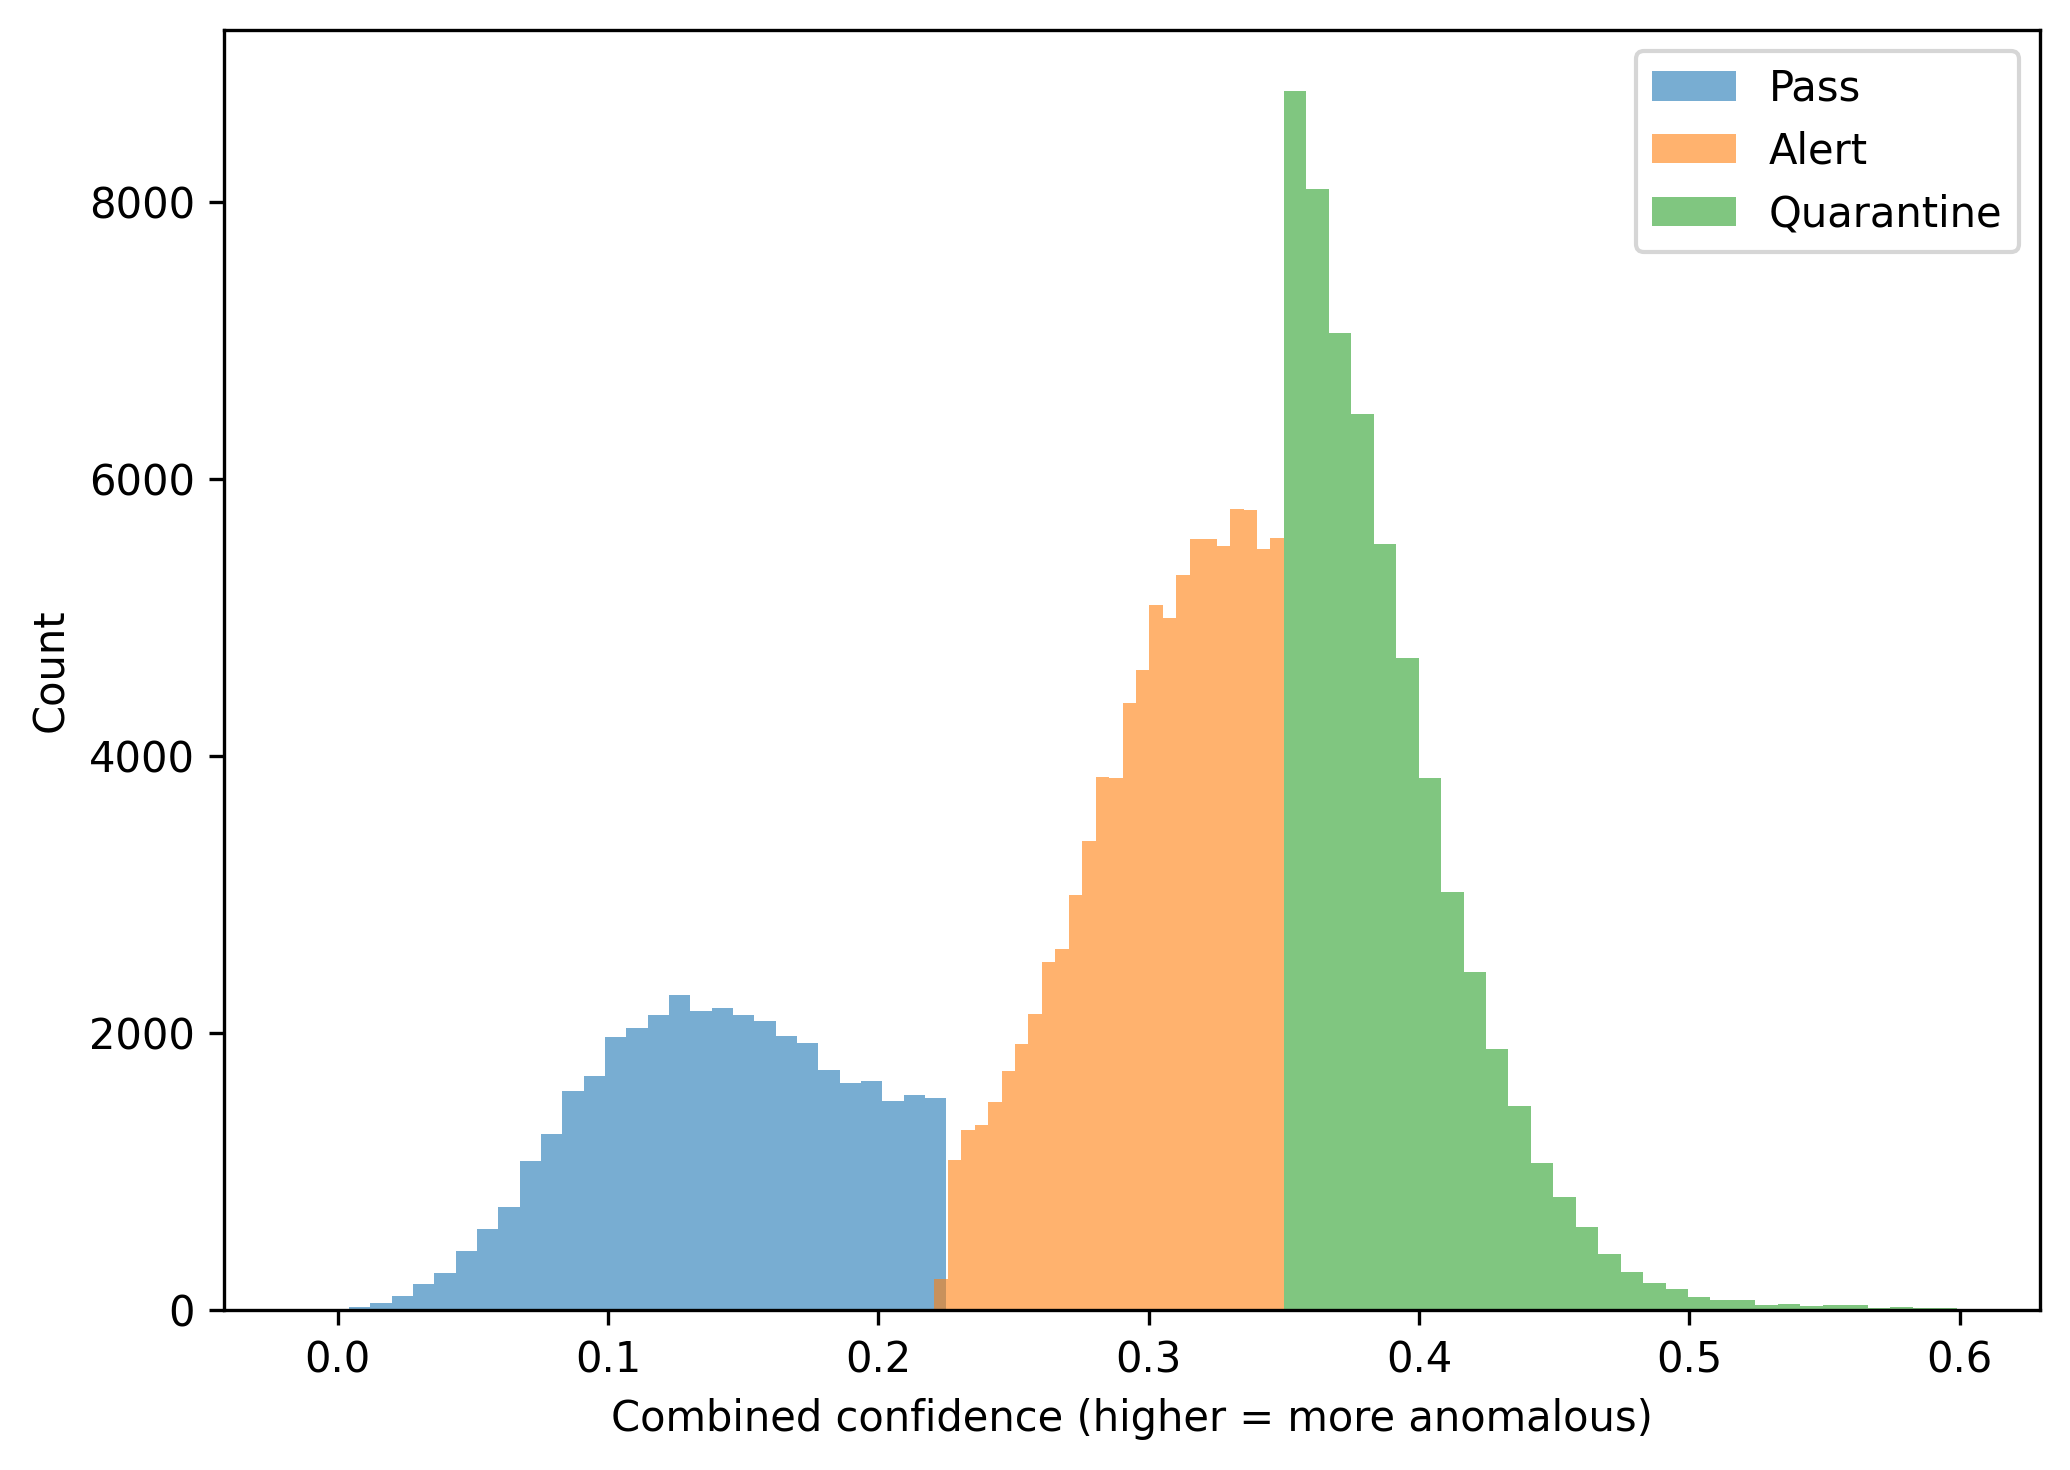

In [ ]:
import pandas as pd

# Compute combined confidence
conf_test_all = 0.5 * states_test_scaled[:, 0] + 0.5 * states_test_scaled[:, 1]

# Apply mask for confidence ≤ 0.6
mask = conf_test_all <= 0.6
conf_test = conf_test_all[mask]
actions_clipped = actions[mask]

# Save as CSV
pd.DataFrame({
    "confidence": conf_test,
    "action": actions_clipped
}).to_csv("dqn_confidence_histogram_clipped.csv", index=False)
print("[saved] dqn_confidence_histogram_clipped.csv")

# Plot histogram (clipped)
plt.figure(figsize=(7, 5), dpi=300)
for act, name in zip([0, 1, 2], ["Pass", "Alert", "Quarantine"]):
    c = conf_test[actions_clipped == act]
    if len(c):
        plt.hist(c, bins=30, alpha=0.6, label=name)

plt.xlabel("Combined confidence (higher = more anomalous)")
plt.ylabel("Count")
# plt.title("Confidence vs. Action (after Safety Valve, ≤ 0.6)")
plt.legend()
plt.tight_layout()
plt.savefig("dqn_confidence_histogram_clipped.pdf", format='pdf', dpi=300)
plt.show()


=== Quarantine latency (on anomaly runs) ===
Segments: 401 | Caught: 401 (100.00%) | Missed: 0
Latency (steps) — mean: 22.67, median: 14.00, p90: 51.00, p95: 67.00, max: 122
[saved] latency_quarantine_latencies.csv


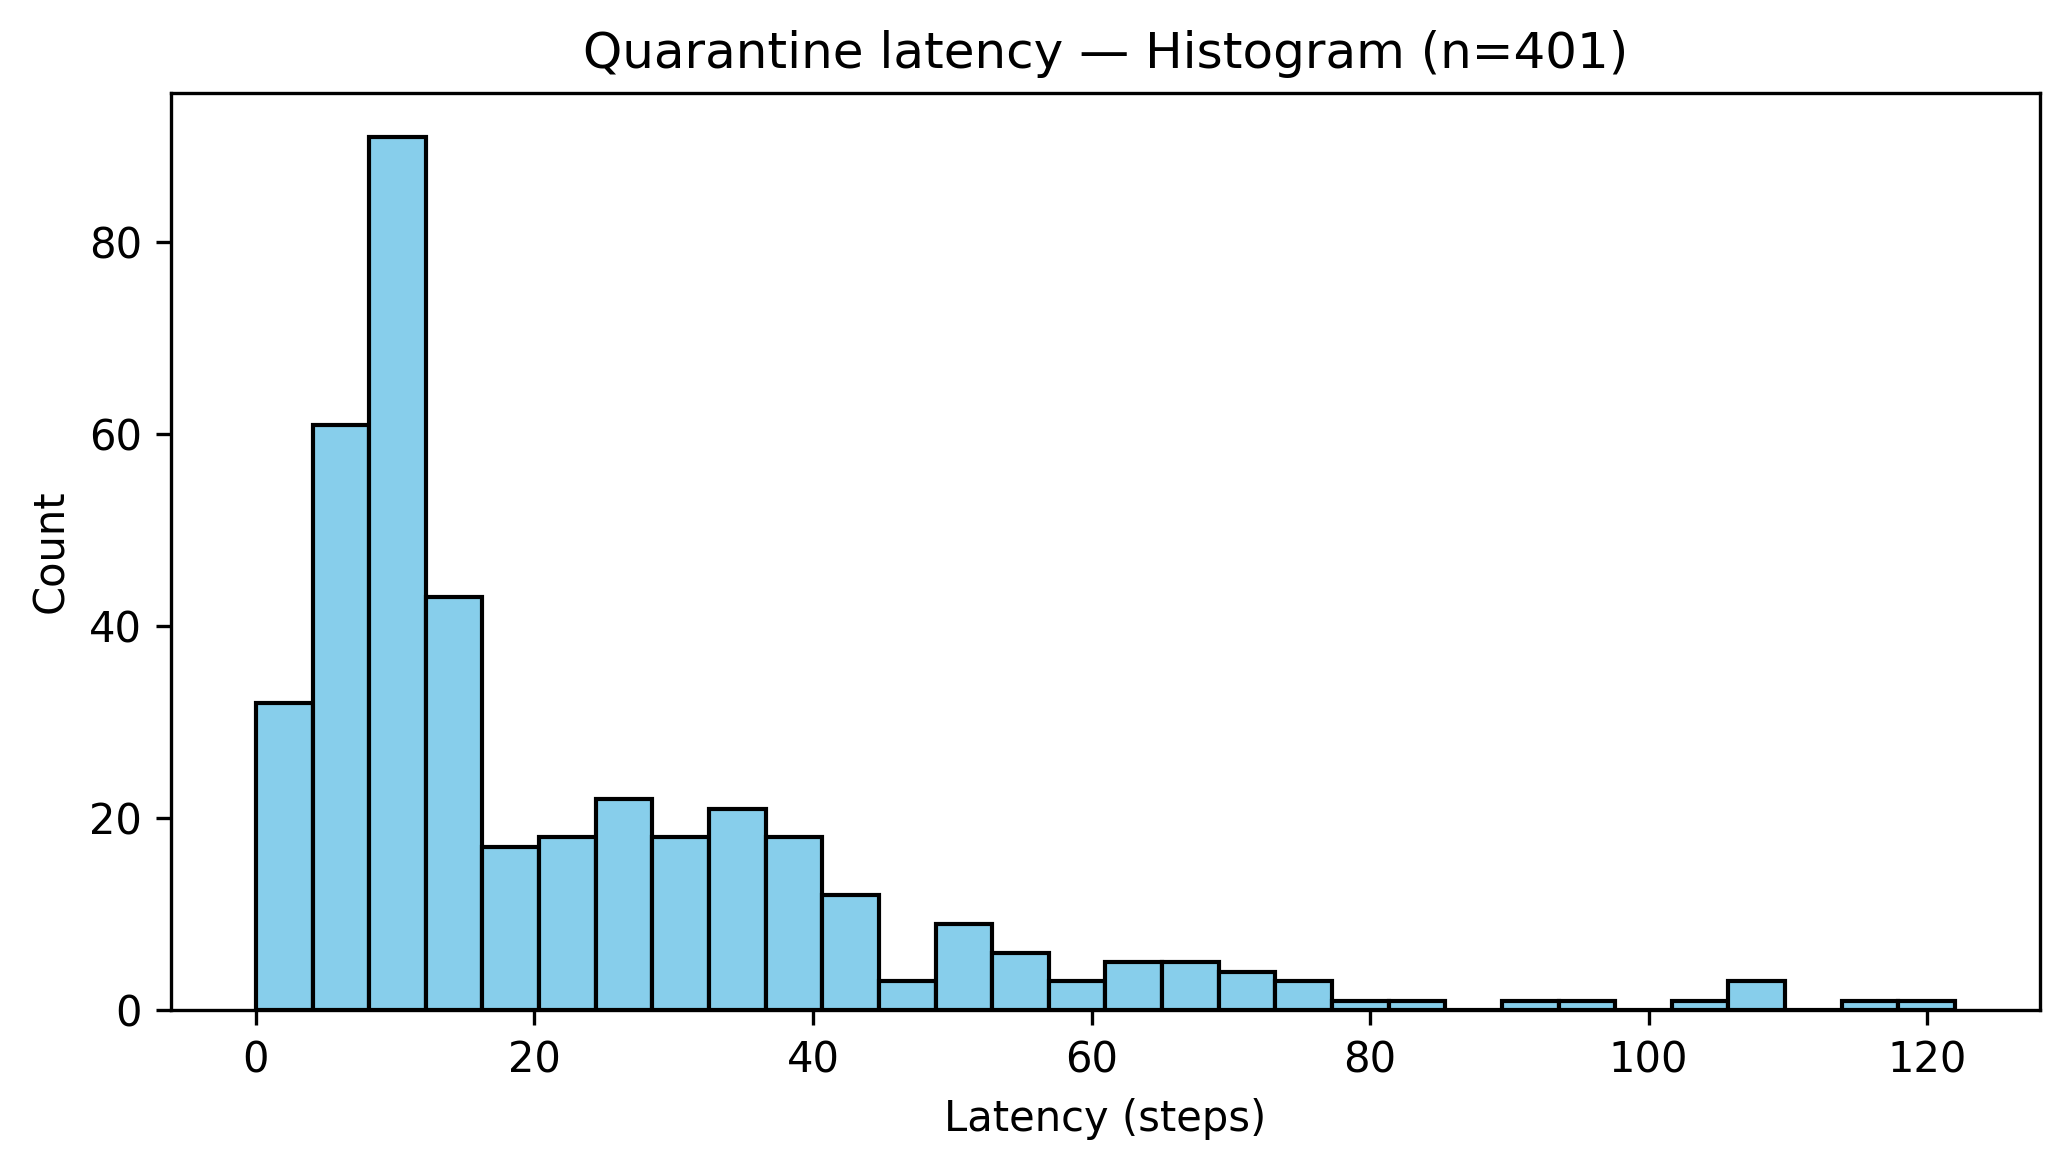

[saved] latency_quarantine_cdf.csv


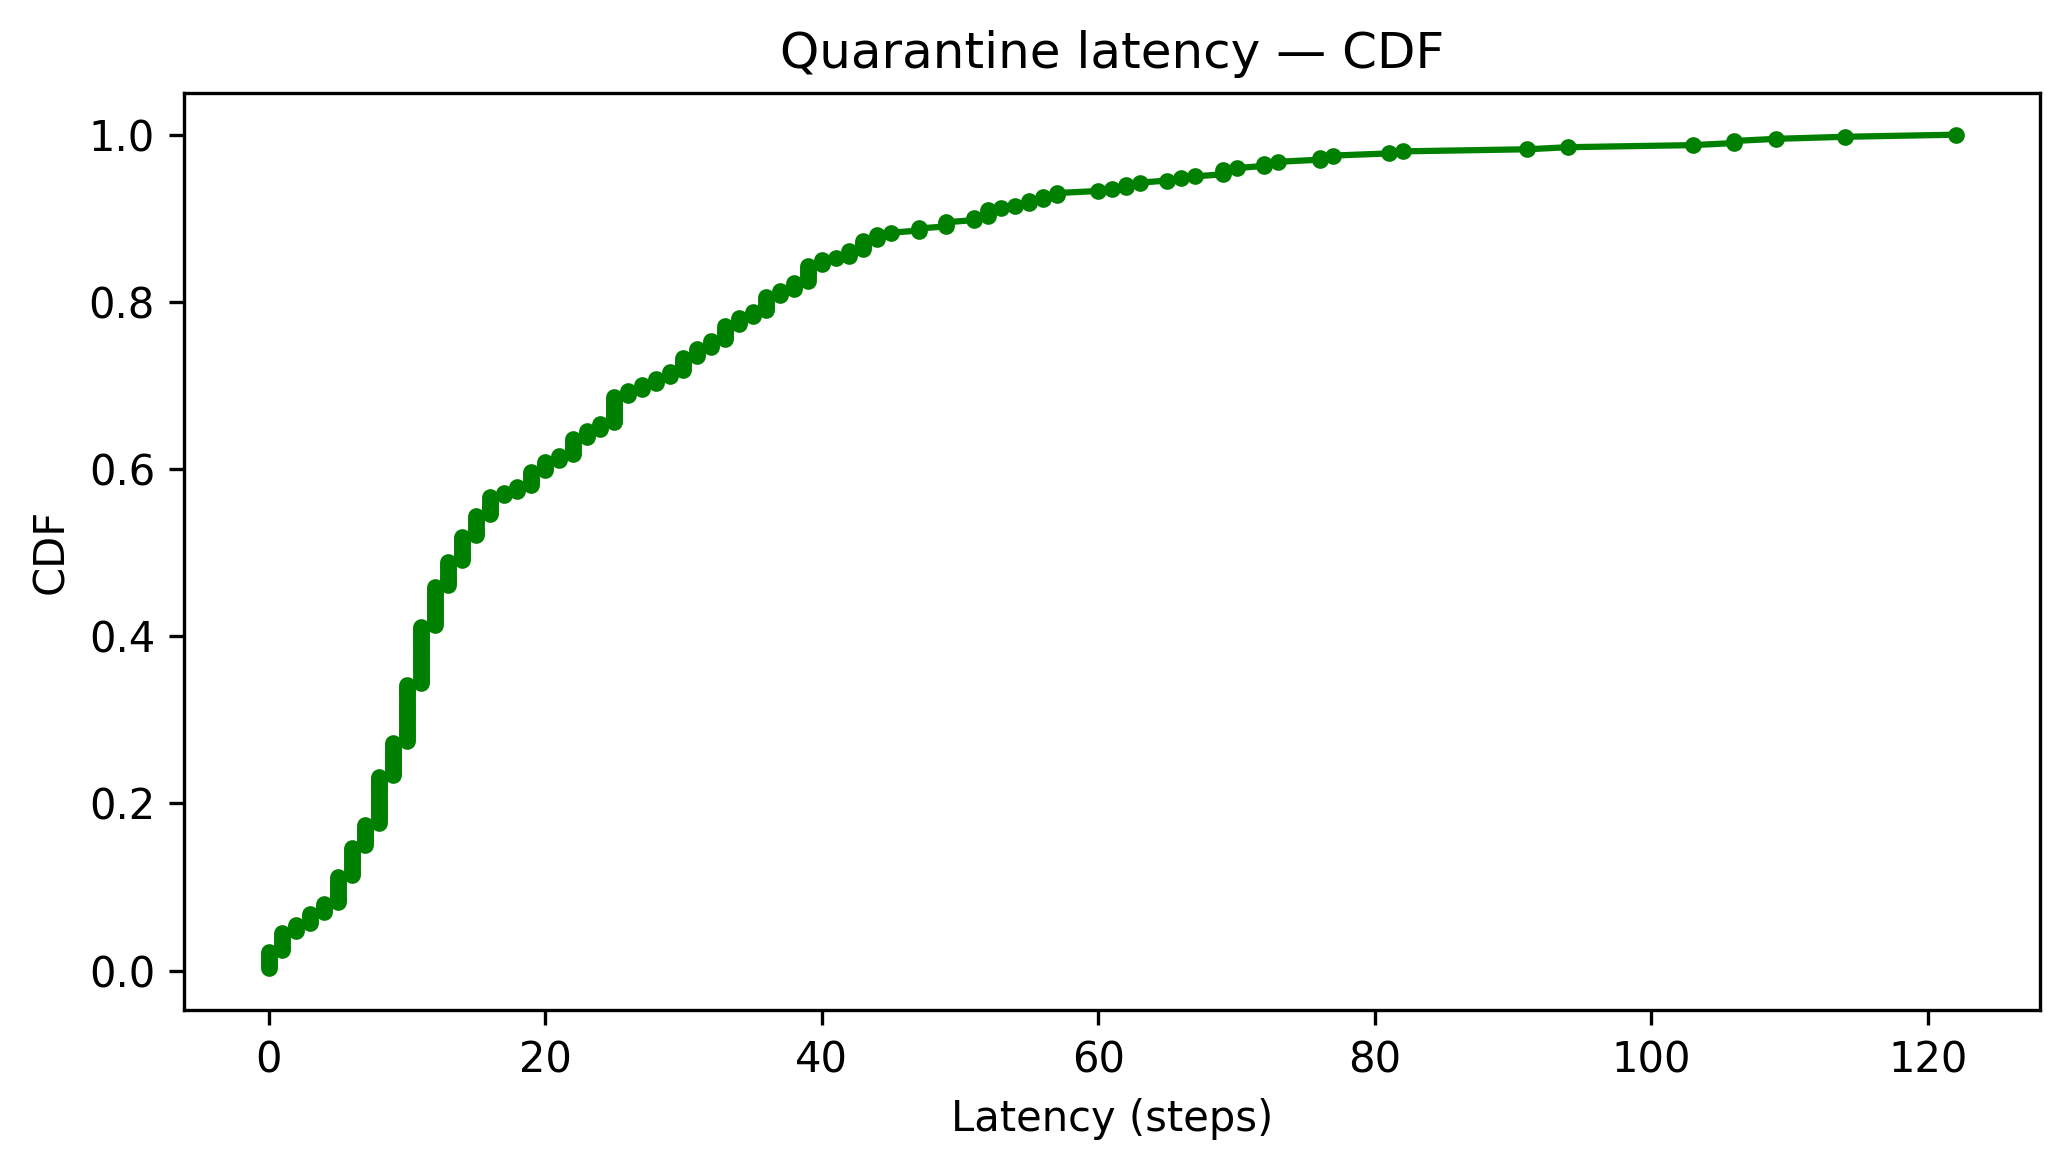


=== Alert latency (on anomaly runs) ===
Segments: 401 | Caught: 401 (100.00%) | Missed: 0
Latency (steps) — mean: 1.97, median: 0.00, p90: 6.00, p95: 8.00, max: 34
[saved] latency_alert_latencies.csv


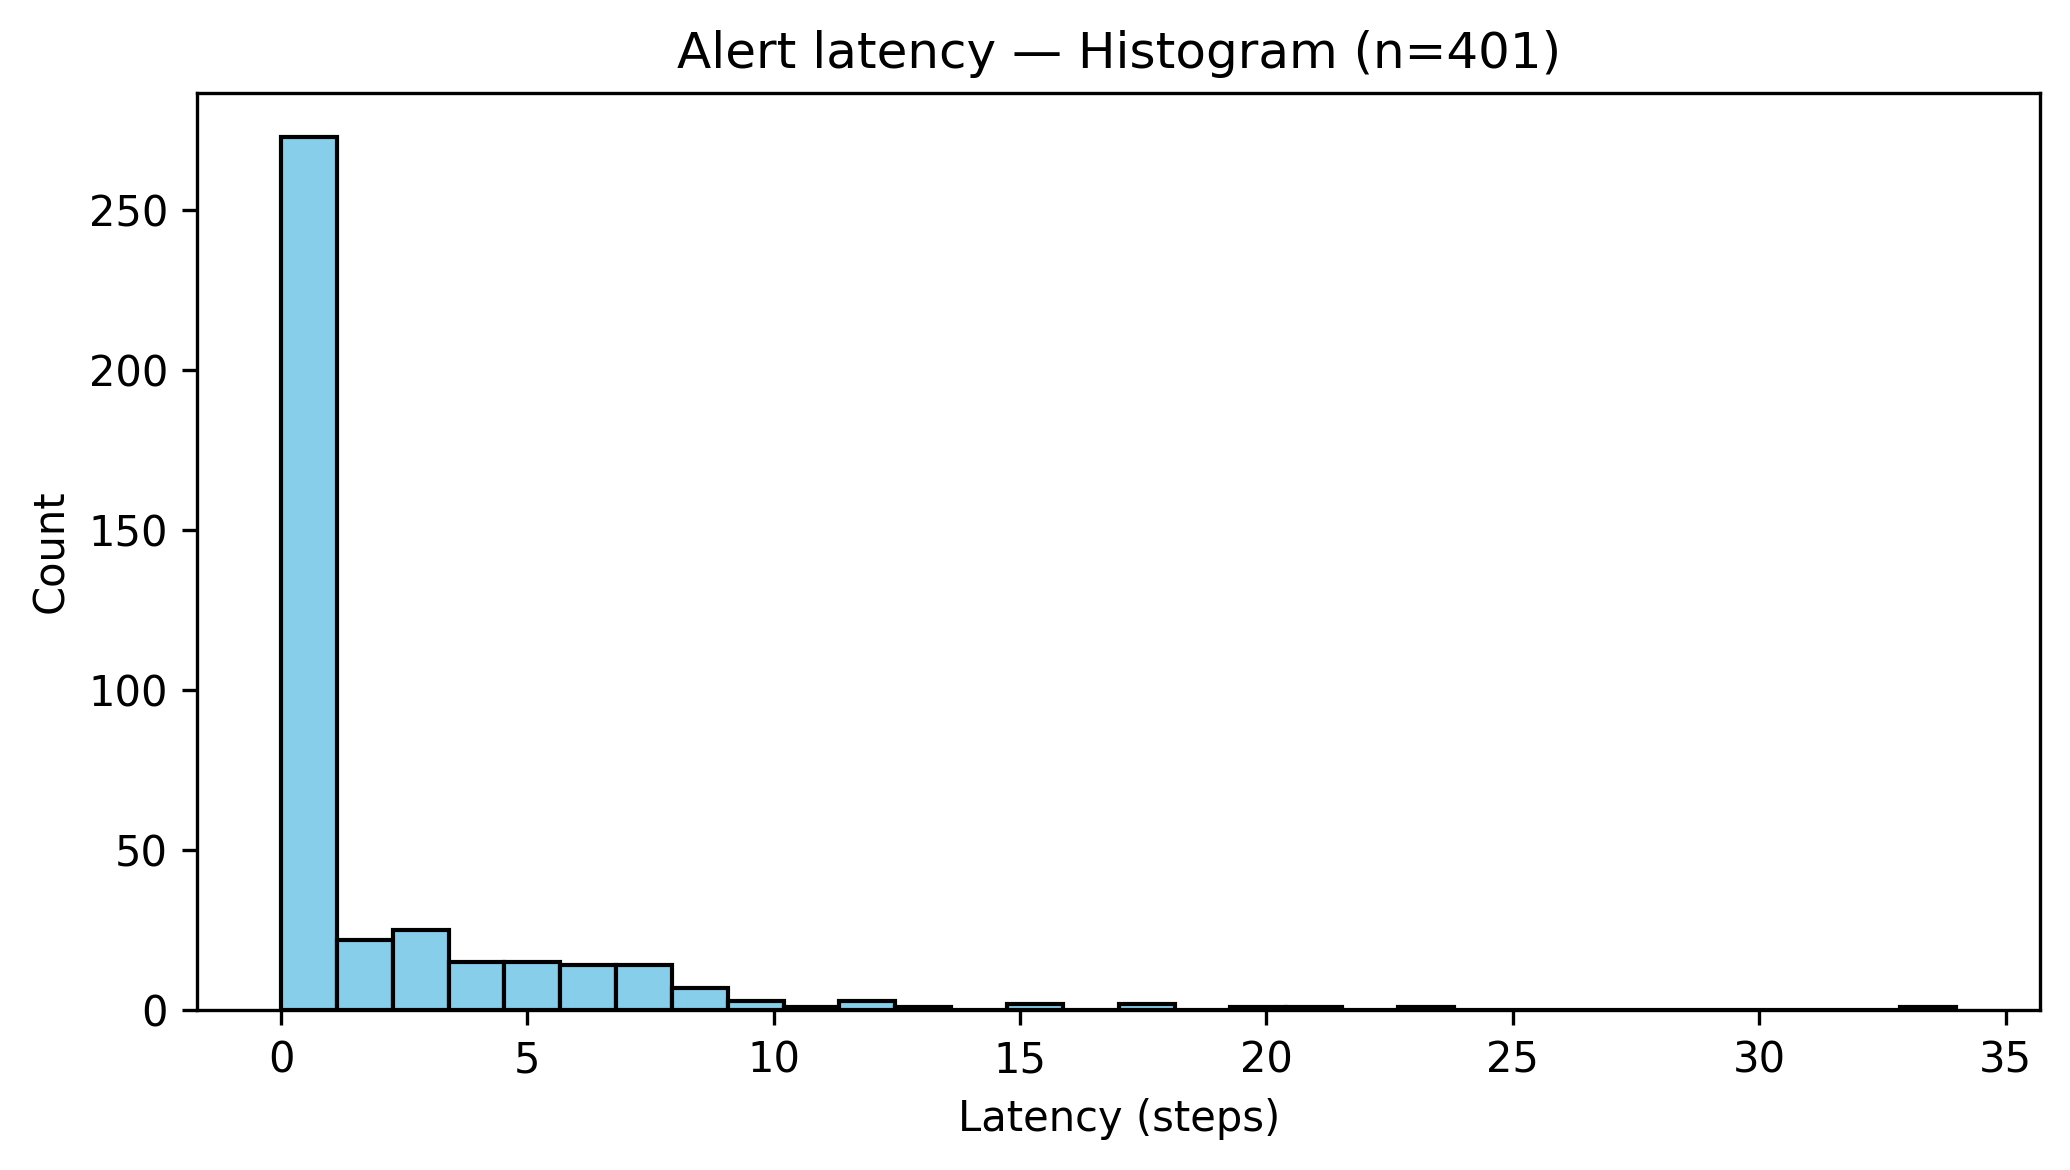

[saved] latency_alert_cdf.csv


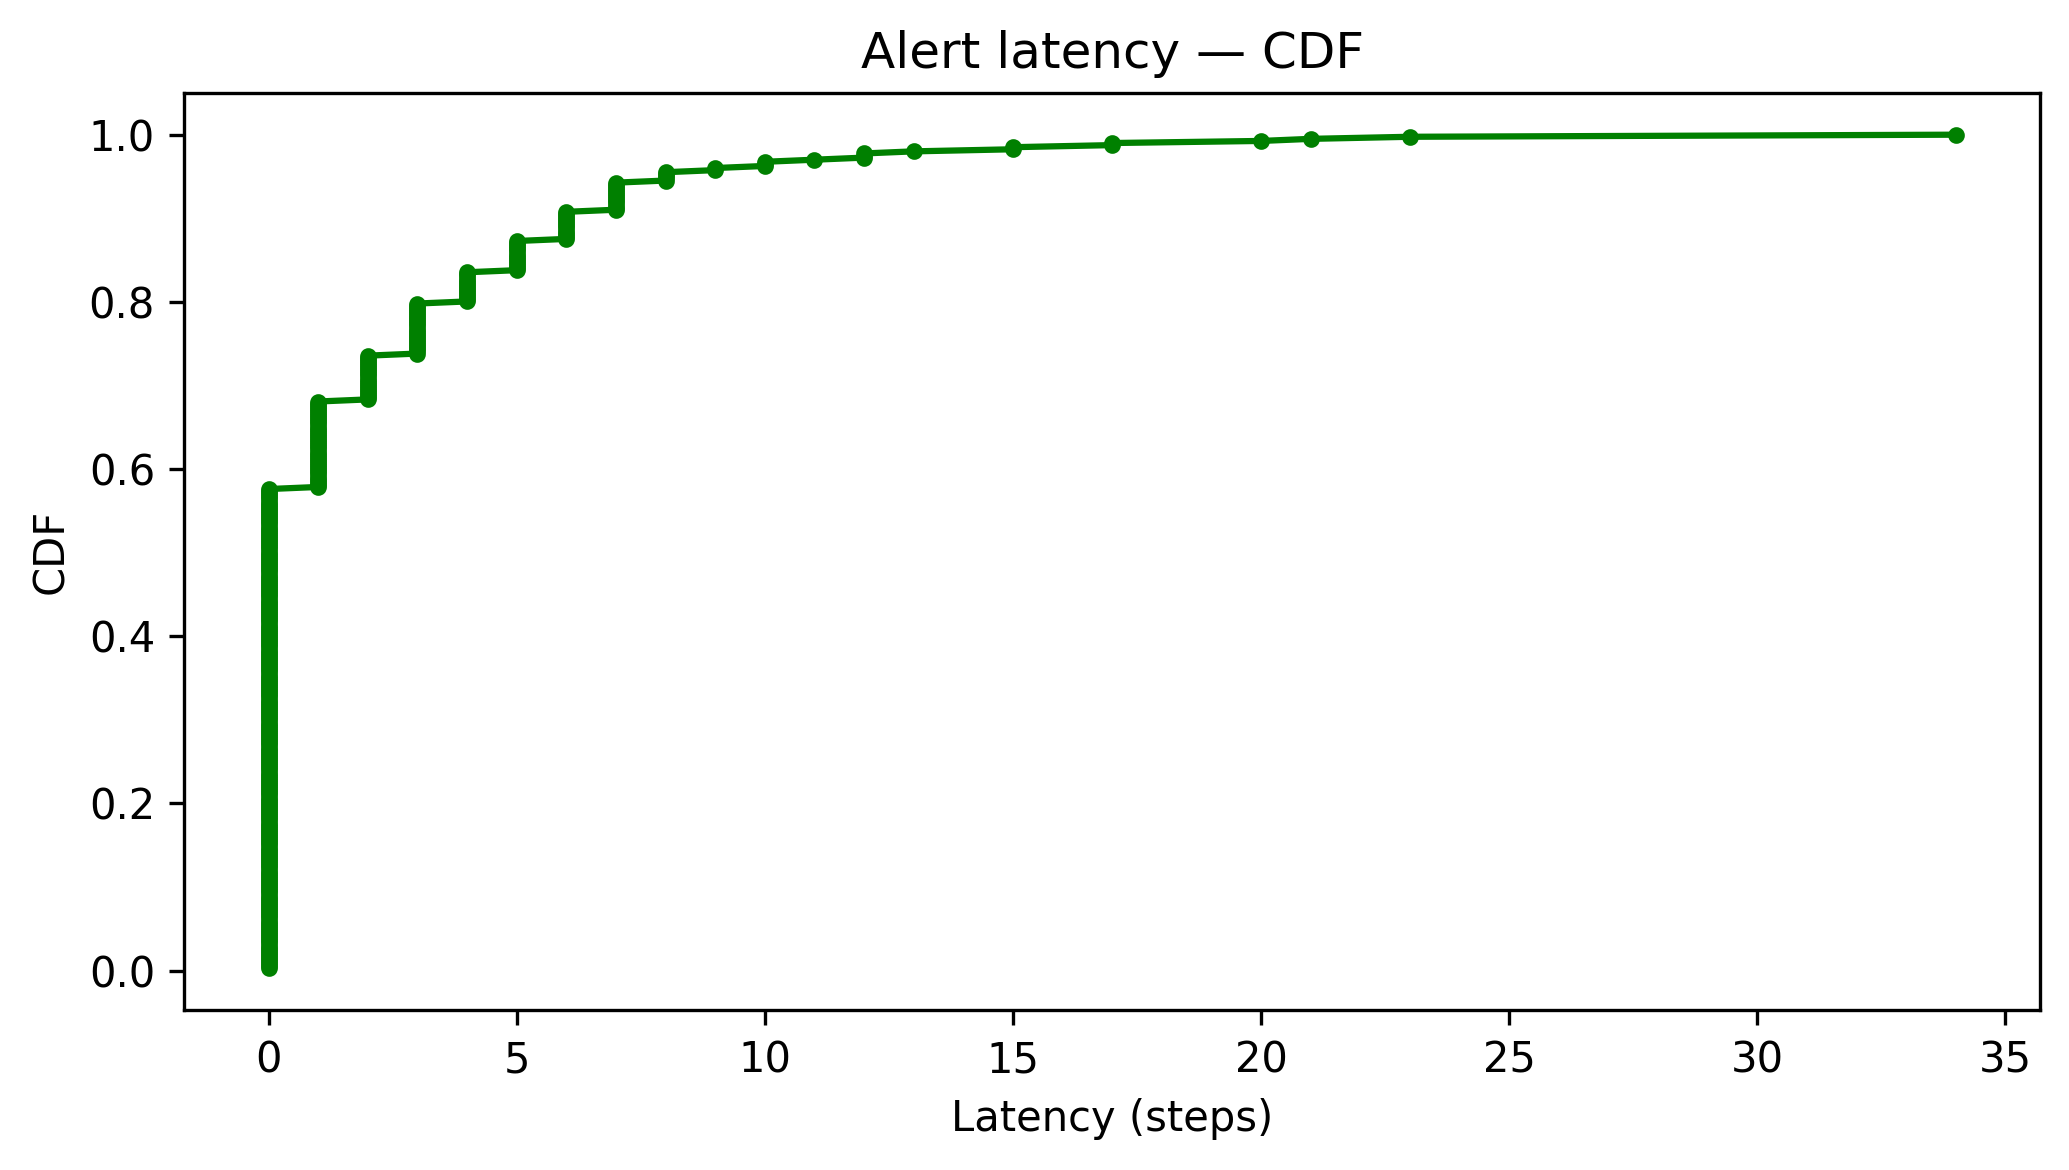


=== Pass latency (on normal runs) ===
Segments: 400 | Caught: 400 (100.00%) | Missed: 0
Latency (steps) — mean: 2.94, median: 1.00, p90: 9.00, p95: 11.00, max: 25
[saved] latency_pass_latencies.csv


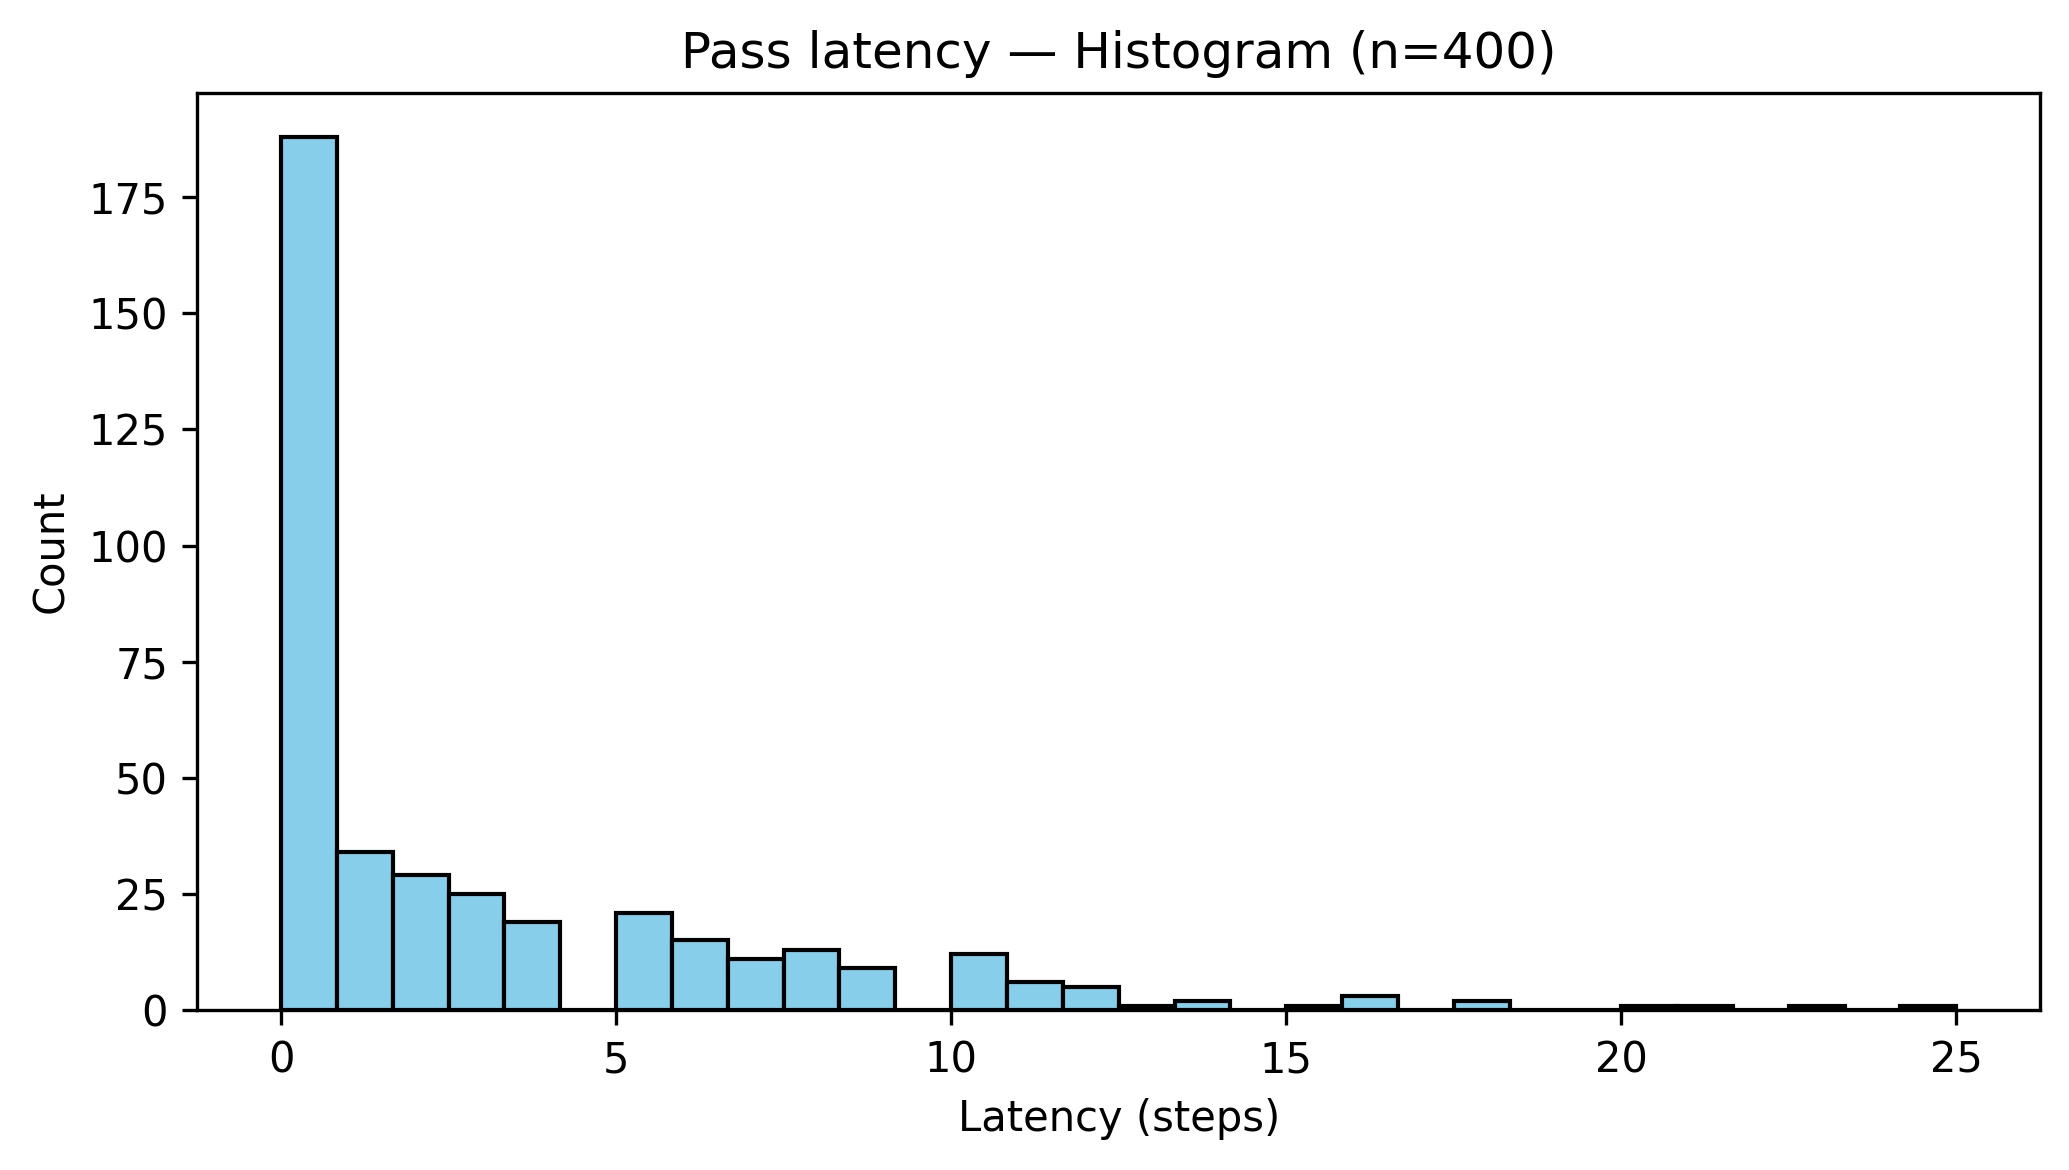

[saved] latency_pass_cdf.csv


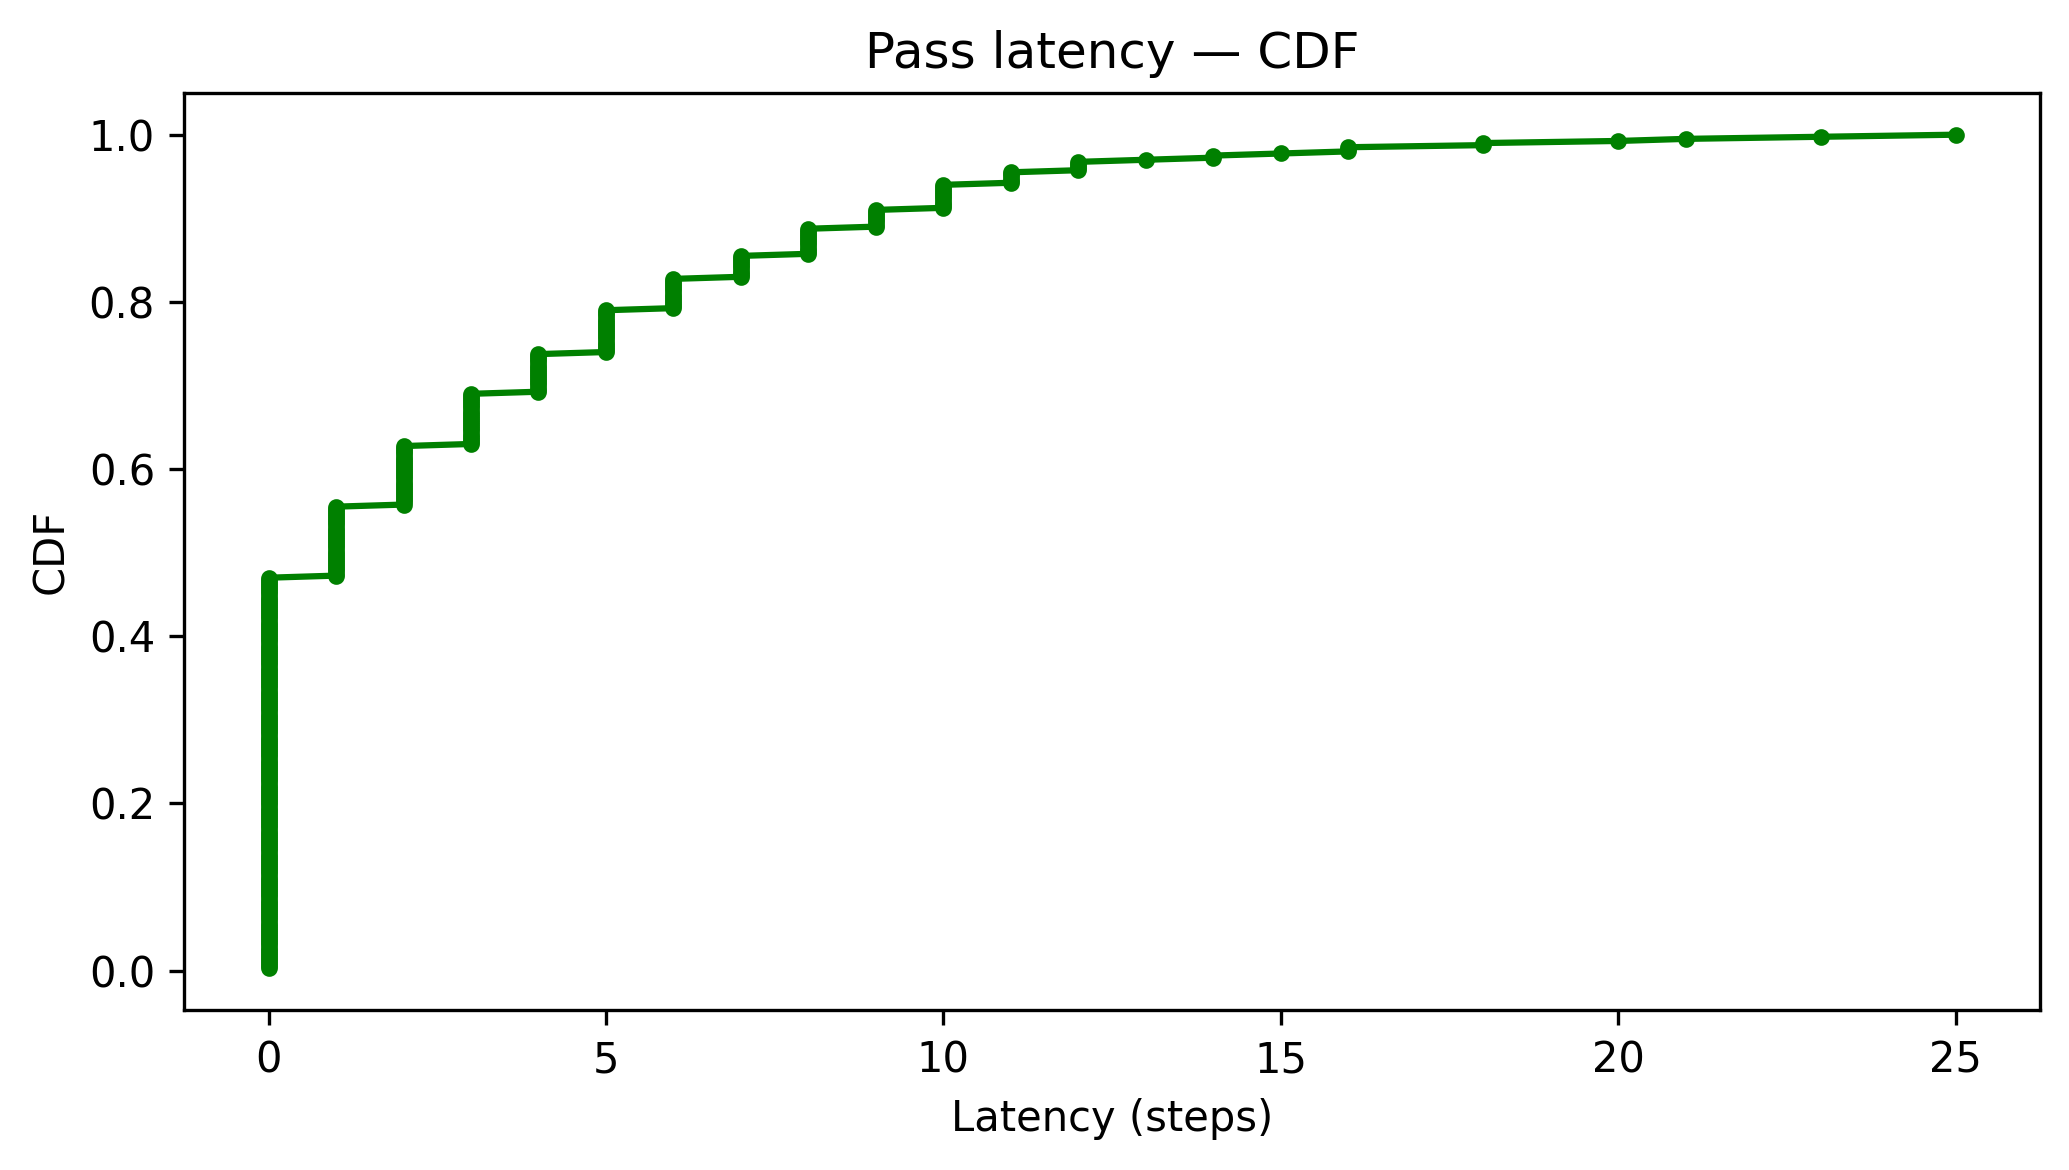


 Latency analysis complete.


In [ ]:

# Latency analysis cell
# - Quarantine latency on anomaly runs
# - Alert latency on anomaly runs
# - Pass latency on normal runs
# Plots: histogram + CDF for each latency type


import numpy as np
import matplotlib.pyplot as plt
from typing import List, Tuple, Dict

# --------- sanity checks ----------
_needed = ['actions', 'labels_test']
_missing = [k for k in _needed if k not in globals()]
if _missing:
    raise RuntimeError("Missing from session: " + ", ".join(_missing))

# Ensure numpy arrays
y = np.asarray(labels_test, dtype=int)
acts = np.asarray(actions, dtype=int)

def save_csv(data_dict, filename):
    import pandas as pd
    pd.DataFrame(data_dict).to_csv(filename, index=False)
    print(f"[saved] {filename}")


# --------- helpers ----------
def find_segments(labels: np.ndarray, segment_label: int) -> List[Tuple[int,int]]:
    """
    Return list of (start, end_exclusive) indices for contiguous segments where labels == segment_label.
    """
    segs = []
    start = None
    for i, lab in enumerate(labels):
        if lab == segment_label and start is None:
            start = i
        if (lab != segment_label and start is not None):
            segs.append((start, i))
            start = None
    if start is not None:
        segs.append((start, len(labels)))
    return segs

def latency_from_segments(actions: np.ndarray,
                          segments: List[Tuple[int,int]],
                          target_action: int) -> Tuple[np.ndarray, int, int]:
    """
    For each segment, compute steps to first occurrence of target_action.
    Returns: (latencies array), caught_count, missed_count
    """
    lat = []
    missed = 0
    for (s, e) in segments:
        local = actions[s:e]
        idx = np.where(local == target_action)[0]
        if len(idx) == 0:
            missed += 1
        else:
            lat.append(idx[0])
    return np.array(lat, dtype=float), len(lat), missed

def summarize_latency(name: str, segs: List[Tuple[int,int]], lat: np.ndarray, missed: int):
    total = len(segs)
    caught = len(lat)
    catch_rate = (100.0 * caught / total) if total else 0.0
    print(f"\n=== {name} ===")
    print(f"Segments: {total} | Caught: {caught} ({catch_rate:.2f}%) | Missed: {missed}")
    if caught:
        stats = {
            "mean": float(np.mean(lat)),
            "median": float(np.median(lat)),
            "p90": float(np.percentile(lat, 90)),
            "p95": float(np.percentile(lat, 95)),
            "max": float(np.max(lat)),
        }
        print("Latency (steps) — "
              f"mean: {stats['mean']:.2f}, median: {stats['median']:.2f}, "
              f"p90: {stats['p90']:.2f}, p95: {stats['p95']:.2f}, max: {stats['max']:.0f}")
    else:
        print("No segments with the target action — skipping plots.")
    return caught > 0

def plot_latency_hist_cdf(latencies: np.ndarray, title_prefix: str, basename: str):
    import pandas as pd
    # Save latencies to CSV
    save_csv({"latency_steps": latencies}, f"{basename}_latencies.csv")

    # Histogram
    plt.figure(figsize=(7, 4), dpi=300)
    plt.hist(latencies, bins=30, color='skyblue', edgecolor='black')
    plt.xlabel("Latency (steps)")
    plt.ylabel("Count")
    plt.title(f"{title_prefix} — Histogram (n={len(latencies)})")
    plt.tight_layout()
    plt.savefig(f"{basename}_histogram.pdf", format='pdf', dpi=300)
    plt.show()

    # CDF
    vals = np.sort(latencies)
    cdf = np.arange(1, len(vals) + 1) / len(vals)
    save_csv({"latency": vals, "cdf": cdf}, f"{basename}_cdf.csv")

    plt.figure(figsize=(7, 4), dpi=300)
    plt.plot(vals, cdf, marker='.', linestyle='-', color='green')
    plt.xlabel("Latency (steps)")
    plt.ylabel("CDF")
    plt.title(f"{title_prefix} — CDF")
    plt.tight_layout()
    plt.savefig(f"{basename}_cdf.pdf", format='pdf', dpi=300)
    plt.show()


# --------- define segments ---------
anom_segments  = find_segments(y, segment_label=1)  # anomaly runs
norm_segments  = find_segments(y, segment_label=0)  # normal runs

# --------- compute latencies ---------
# Quarantine on anomaly runs
q_lat, q_caught, q_missed = latency_from_segments(acts, anom_segments, target_action=2)

# Alert on anomaly runs
a_lat, a_caught, a_missed = latency_from_segments(acts, anom_segments, target_action=1)

# Pass on normal runs
p_lat, p_caught, p_missed = latency_from_segments(acts, norm_segments, target_action=0)

# --------- print summaries & plot ---------
if summarize_latency("Quarantine latency (on anomaly runs)", anom_segments, q_lat, q_missed):
    plot_latency_hist_cdf(q_lat, "Quarantine latency", "latency_quarantine")

if summarize_latency("Alert latency (on anomaly runs)", anom_segments, a_lat, a_missed):
    plot_latency_hist_cdf(a_lat, "Alert latency", "latency_alert")

if summarize_latency("Pass latency (on normal runs)", norm_segments, p_lat, p_missed):
    plot_latency_hist_cdf(p_lat, "Pass latency", "latency_pass")

print("\n Latency analysis complete.")

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

def plot_latency_hist_cdf(latencies: np.ndarray, title_prefix: str, basename: str):
    import pandas as pd

    # Save raw latencies
    save_csv({"latency_steps": latencies}, f"{basename}_latencies.csv")

    # Histogram
    plt.figure(figsize=(7, 4), dpi=300)
    plt.hist(latencies, bins=30, color='skyblue', edgecolor='black')
    plt.xlabel("Latency (steps)")
    plt.ylabel("Count")
    plt.title(f"{title_prefix} — Histogram (n={len(latencies)})")
    plt.tight_layout()
    plt.savefig(f"{basename}_histogram.pdf", format='pdf', dpi=300)
    plt.show()

    # CDF computation
    vals = np.sort(latencies)
    cdf = np.arange(1, len(vals)+1) / len(vals)

    # Compute annotations
    p95 = np.percentile(latencies, 95)
    median = np.median(latencies)

    # Save CDF values
    save_csv({"latency": vals, "cdf": cdf}, f"{basename}_cdf.csv")

    # CDF plot with annotations
    plt.figure(figsize=(7, 4), dpi=300)
    plt.plot(vals, cdf, marker='.', linestyle='-', color='green', label="CDF")

    # Annotate p95
    plt.axvline(p95, color='red', linestyle='--', label=f'95th percentile = {p95:.1f} steps')
    plt.axvline(median, color='orange', linestyle='--', label=f'Median = {median:.1f} steps')

    plt.xlabel("Latency (steps)")
    plt.ylabel("CDF")
    plt.title(f"{title_prefix} — CDF with Annotations")
    plt.legend()
    plt.tight_layout()
    plt.savefig(f"{basename}_cdf_annotated.pdf", format='pdf', dpi=300)
    plt.show()

[saved] latency_alert_latencies.csv


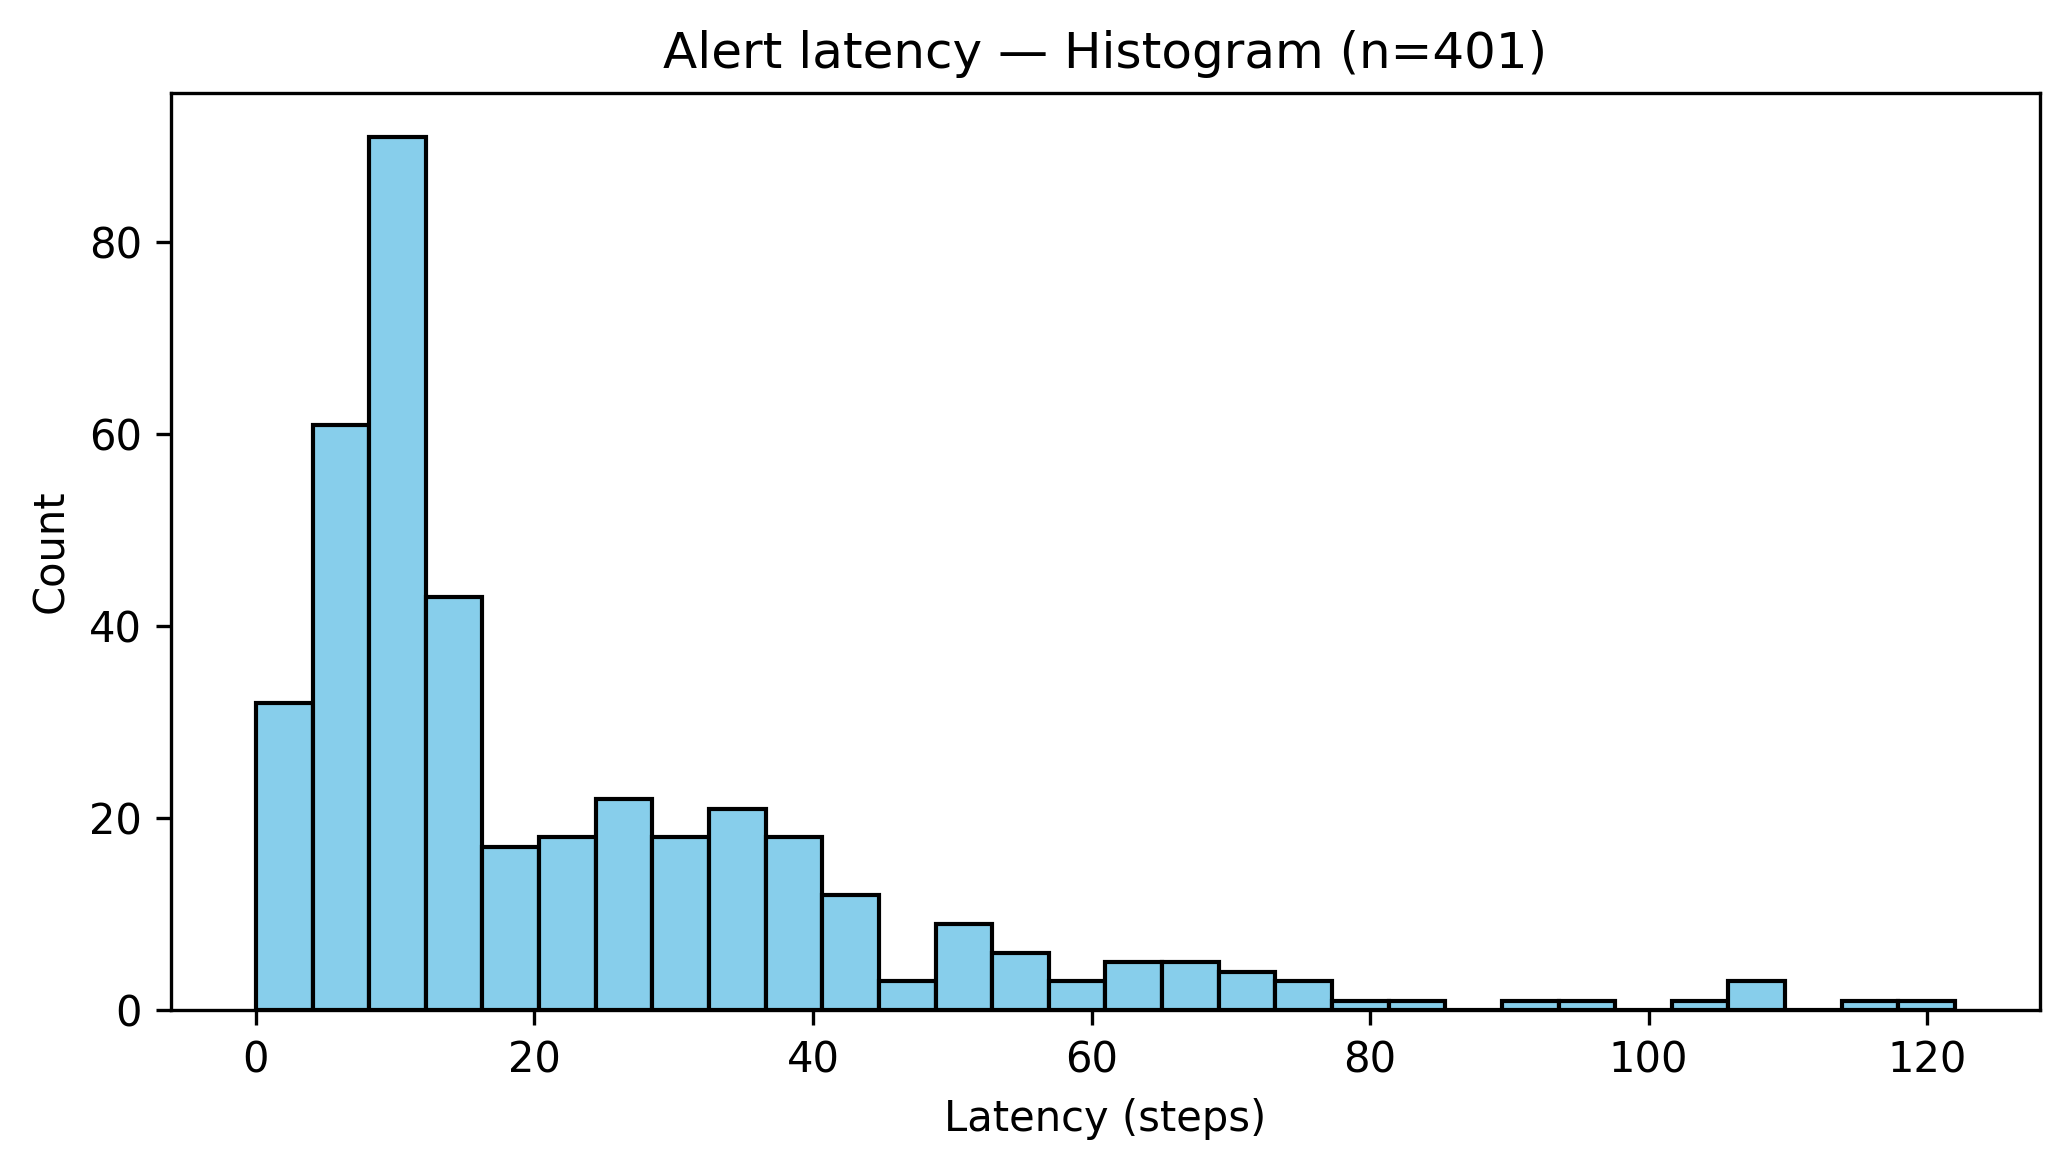

[saved] latency_alert_cdf.csv


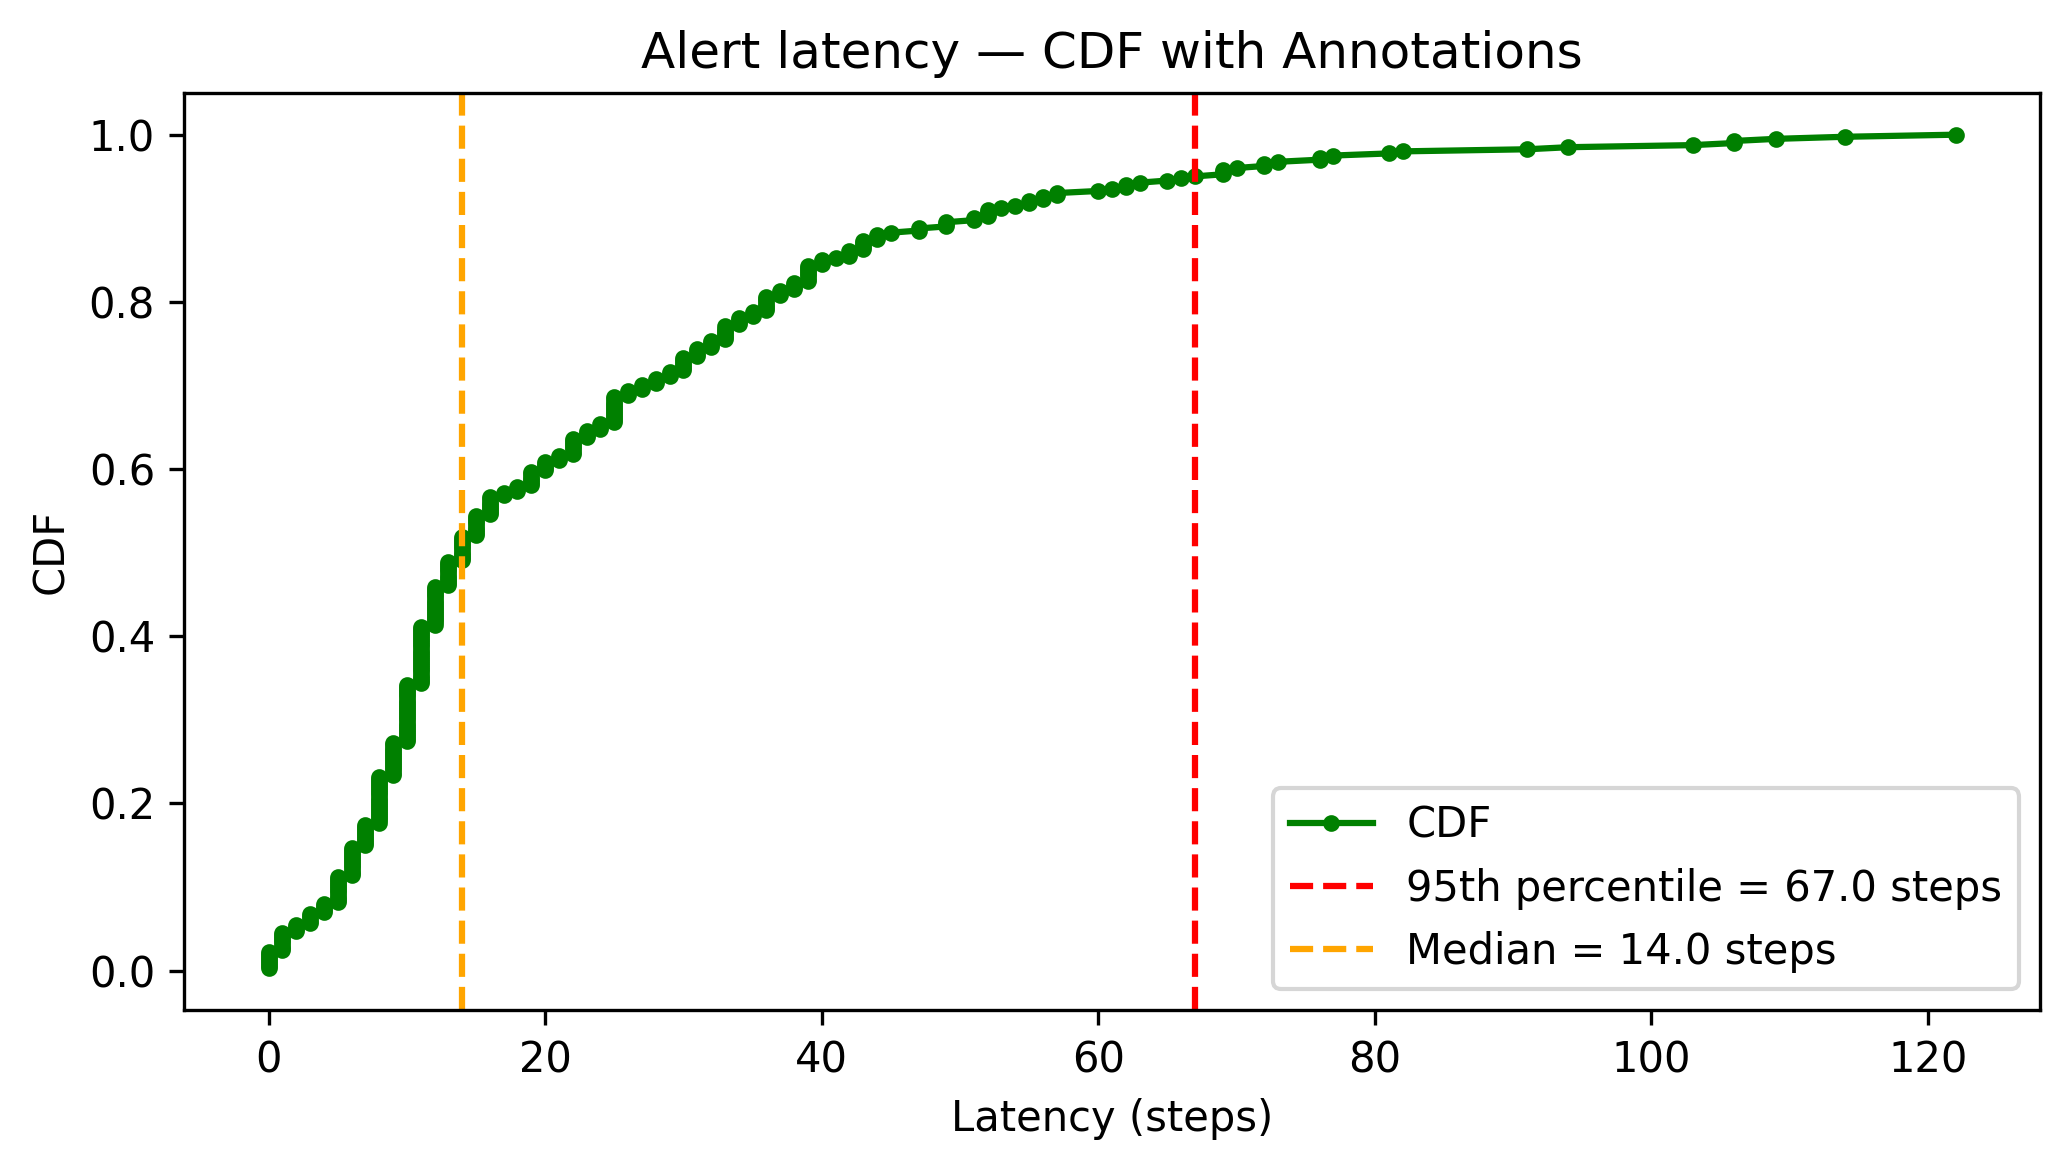

In [ ]:
plot_latency_hist_cdf(q_lat, "Alert latency", "latency_alert")

[saved] latency_alert_latencies.csv


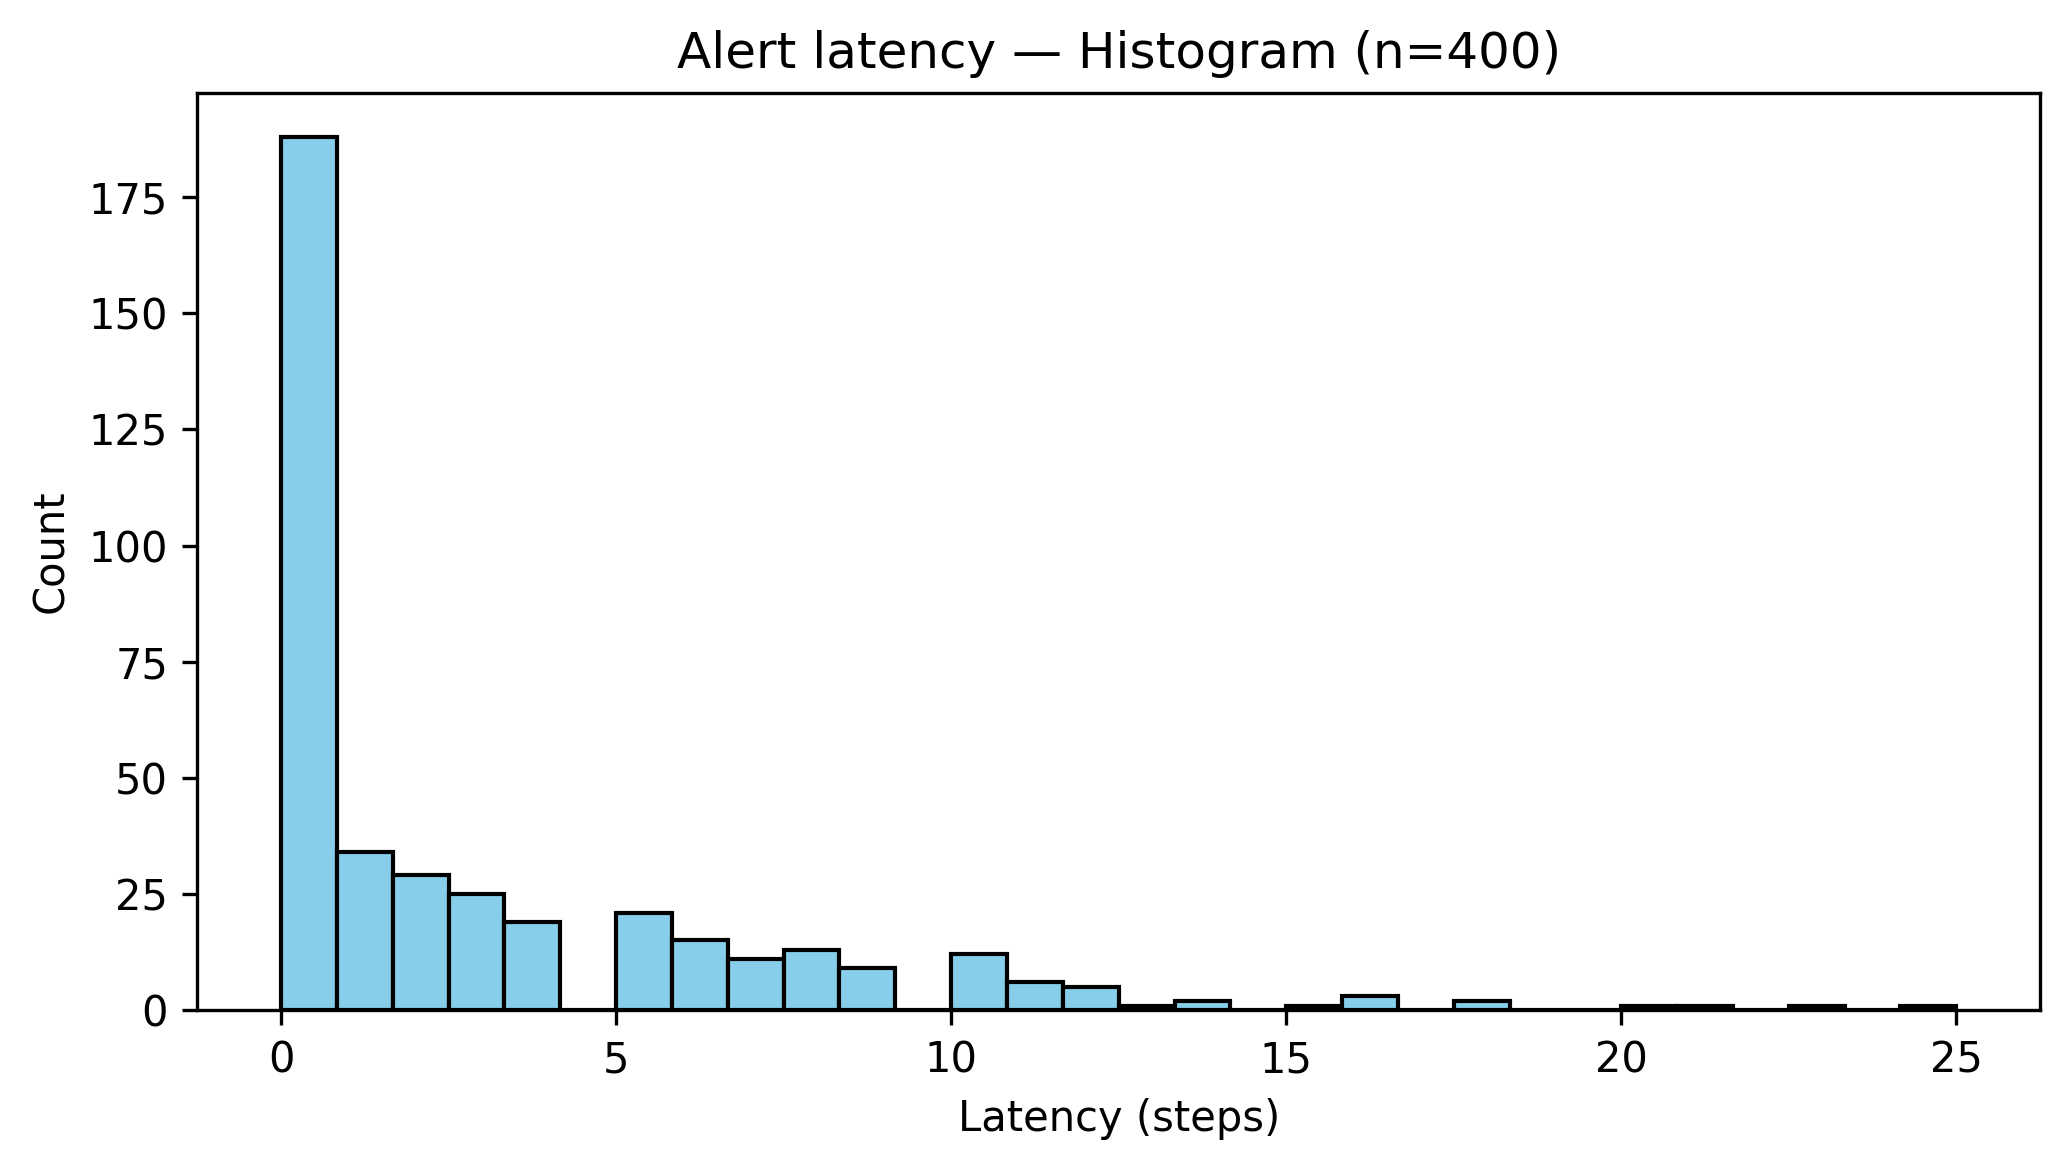

[saved] latency_alert_cdf.csv


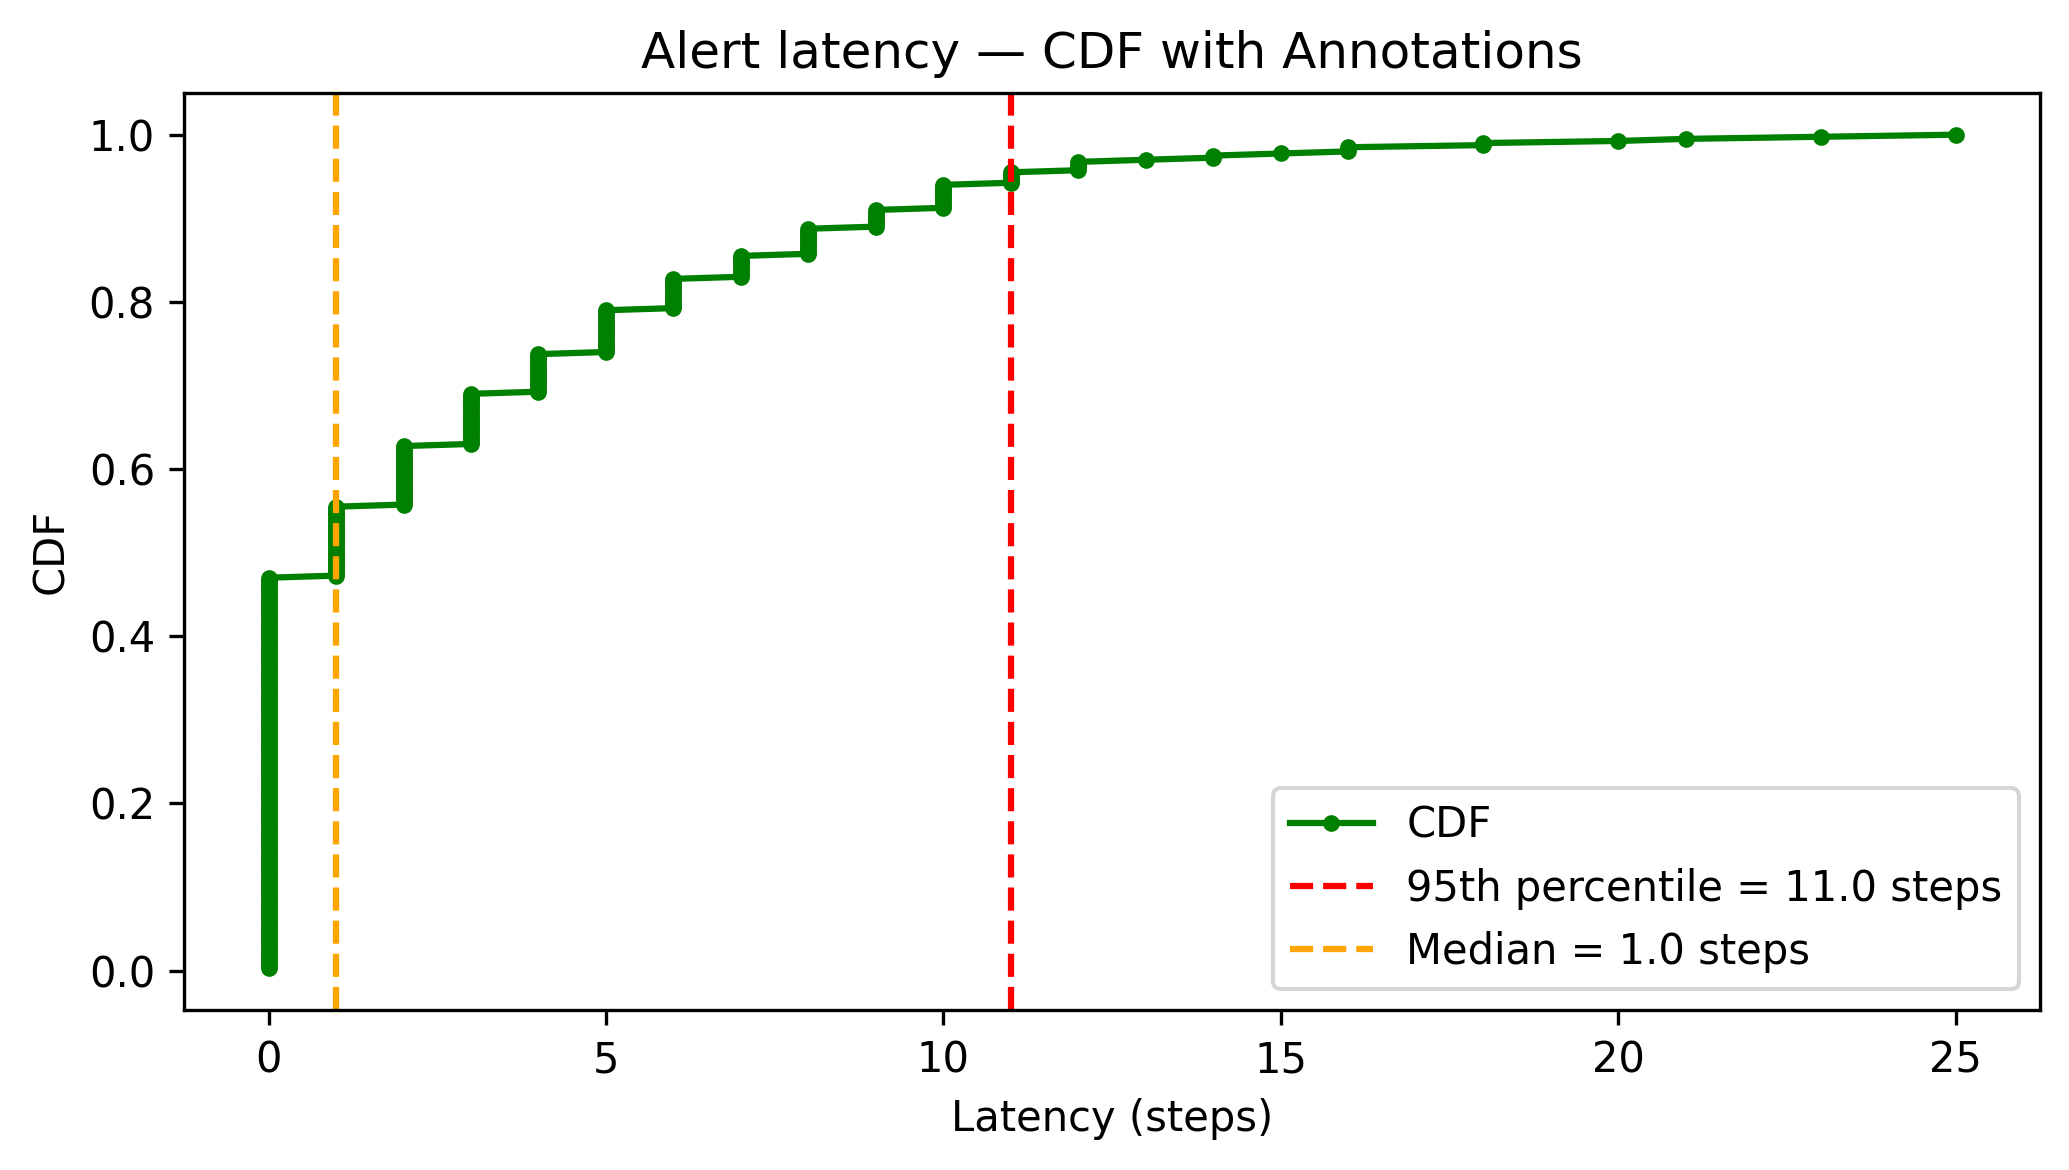

In [ ]:
plot_latency_hist_cdf(p_lat, "Alert latency", "latency_alert")

[saved] latency_alert_latencies.csv


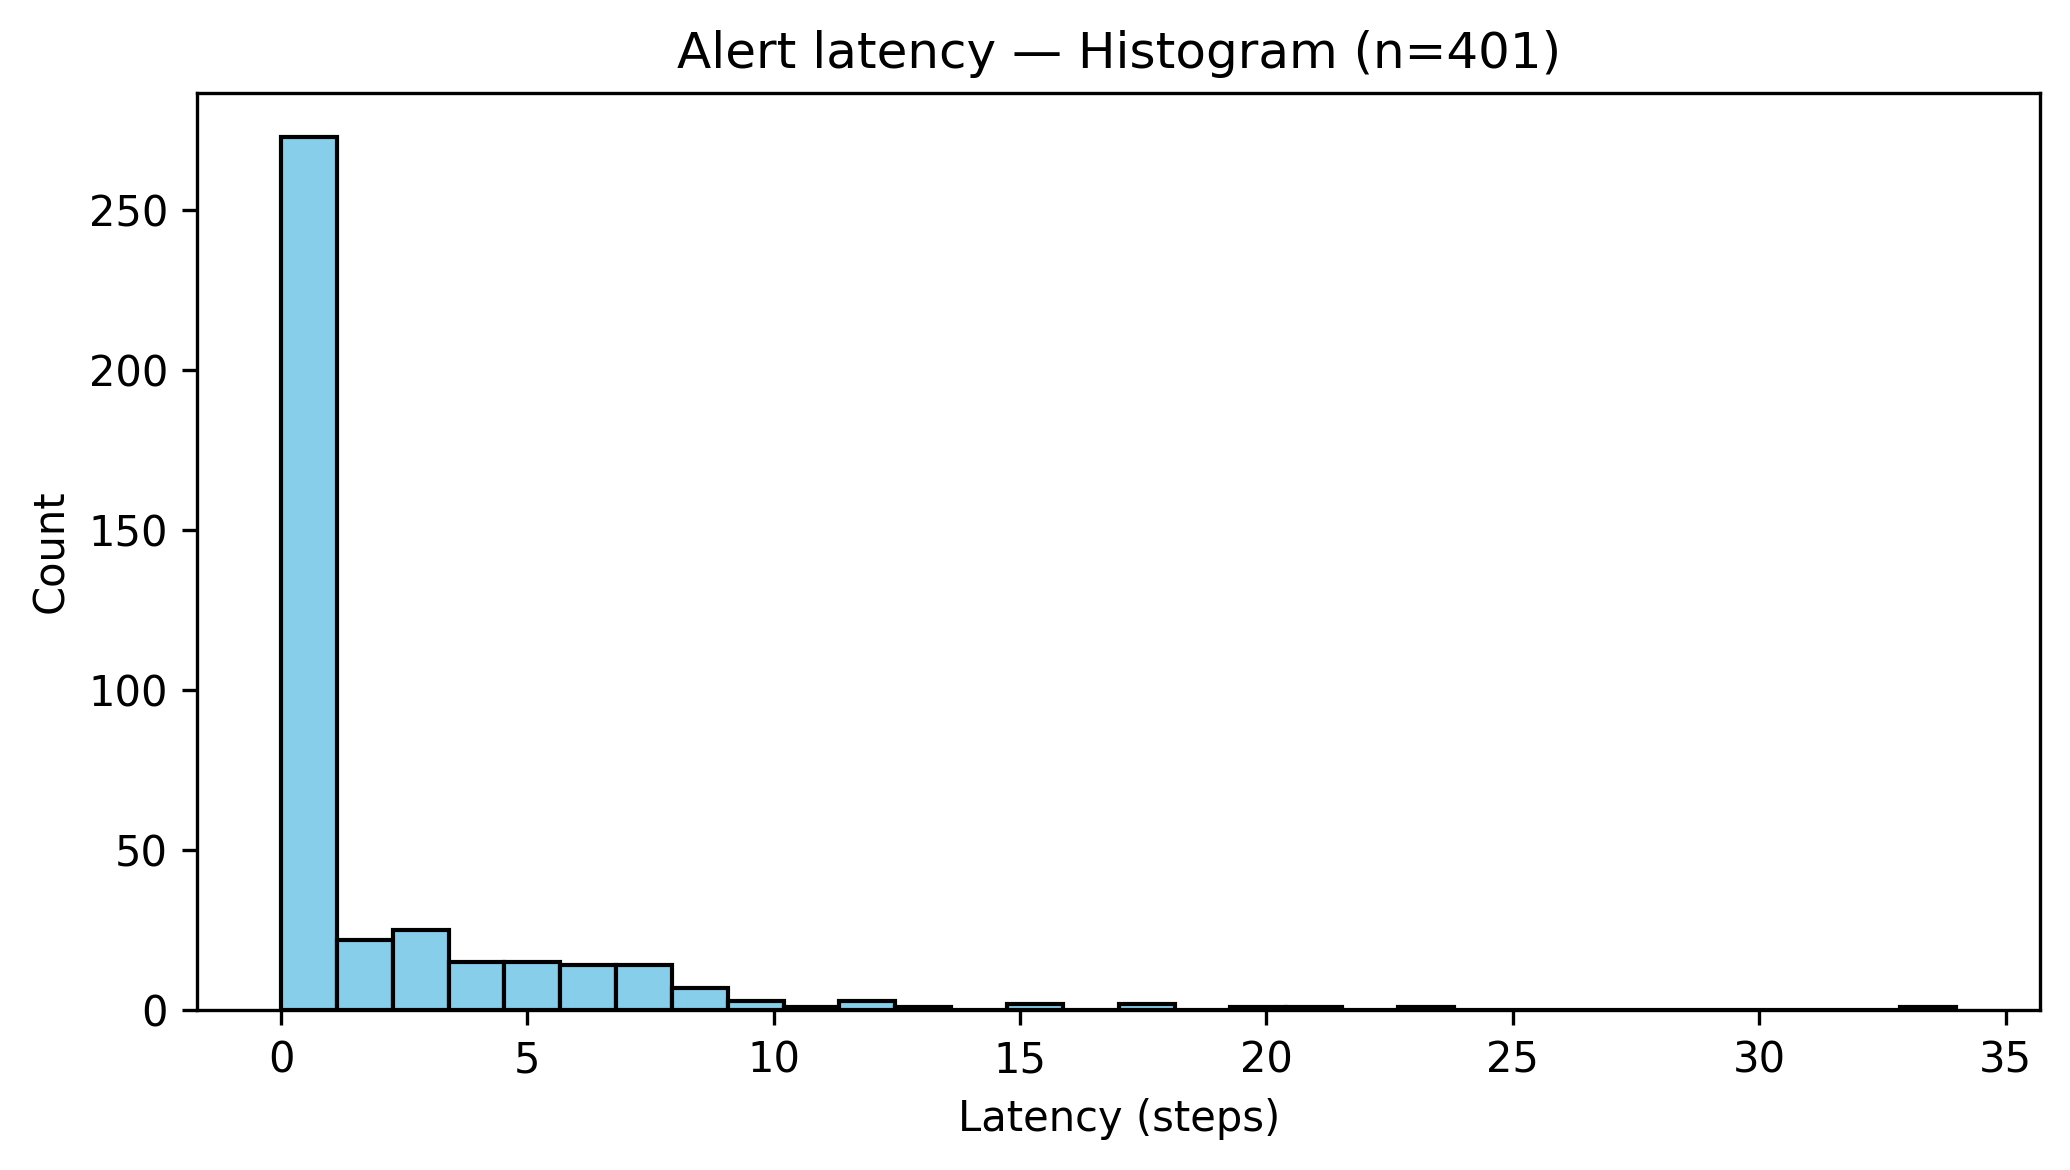

[saved] latency_alert_cdf.csv


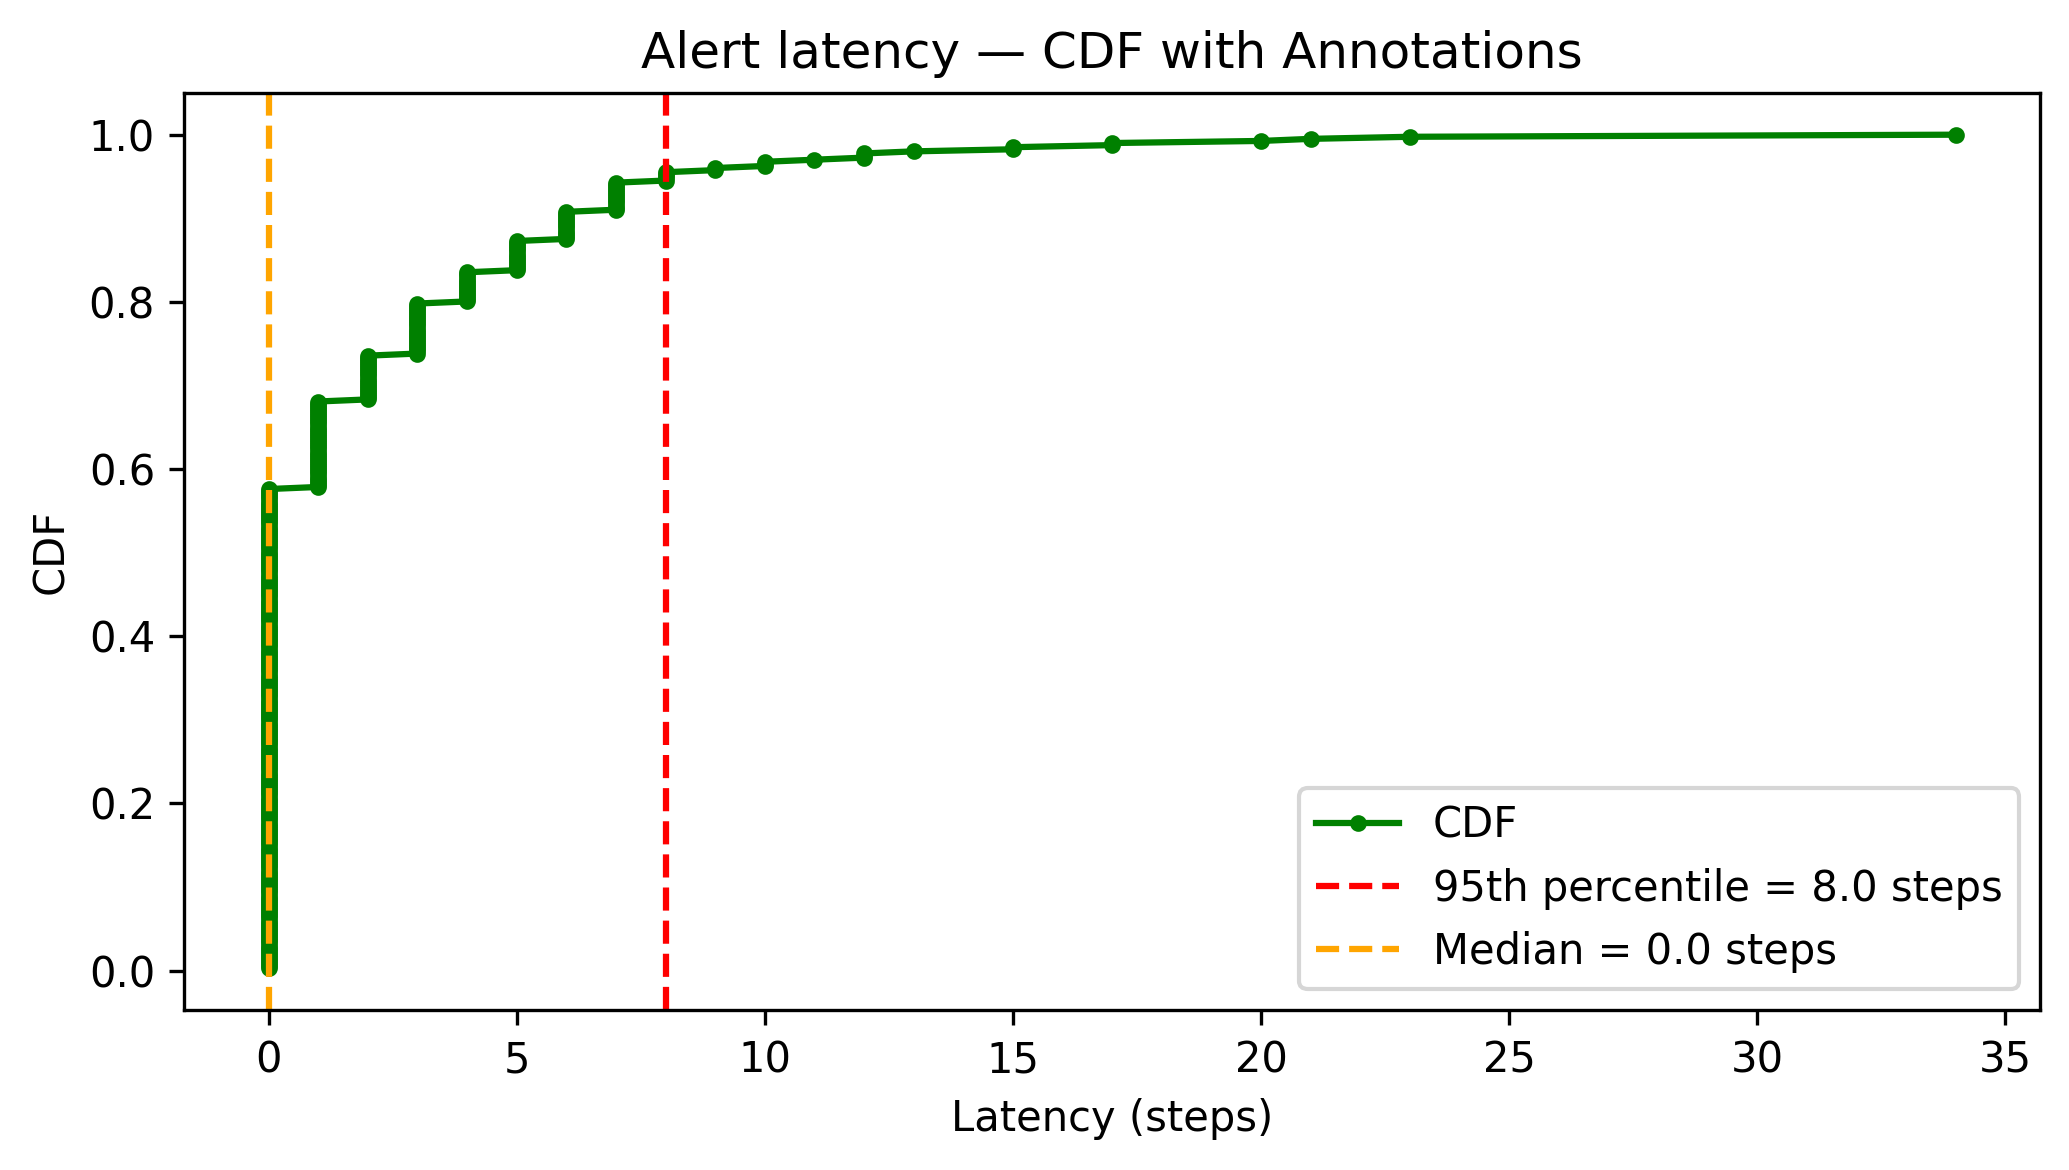

In [ ]:
plot_latency_hist_cdf(a_lat, "Alert latency", "latency_alert")

In [ ]:

# 7) Extended Evaluation Metrics for RL Confidence Calibration
import numpy as np
import pandas as pd
import torch
from scipy.stats import entropy
from scipy.optimize import minimize
from sklearn.metrics import (
    precision_score, recall_score, f1_score, fbeta_score,
    balanced_accuracy_score, matthews_corrcoef, cohen_kappa_score,
    jaccard_score, roc_auc_score, average_precision_score,
    brier_score_loss, log_loss, confusion_matrix, classification_report
)

# ----------- CONFIG -----------
DATASET_SIZES = [
    10000, 20000, 30000, 40000, 50000, 60000, 70000, 80000, 90000,
    100000, 110000, 120000, 130000, 140000, 150000,
    160000, 170000, 180000, len(states_test_scaled)
]
USE_SAFETY_VALVE = True  # set False for raw policy actions


# Helper functions


def combined_conf(row):
    """Combine state confidence features (custom for this RL environment)."""
    return 0.5 * row[0] + 0.5 * row[1]

def action_with_confidence_safety(policy_net, state_row, device, conf_hi=SV_CONF_HI, conf_lo=SV_CONF_LO):
    """RL safety valve logic to avoid overreaction at low confidence."""
    s = torch.tensor(state_row, dtype=torch.float32, device=device).unsqueeze(0)
    with torch.no_grad():
        a = int(policy_net(s).argmax(1).item())
    conf = combined_conf(state_row)
    if a == 2:  # Quarantine
        if conf < conf_lo: return 0  # → Pass
        if conf < conf_hi: return 1  # → Alert
    return a

def predict_actions(policy_net, X, device, use_sv=True):
    """Predict discrete actions and binary anomaly labels."""
    if use_sv:
        acts = np.array([action_with_confidence_safety(policy_net, X[i], device) for i in range(len(X))], dtype=int)
    else:
        with torch.no_grad():
            logits = policy_net(torch.tensor(X, dtype=torch.float32, device=device))
            acts = logits.argmax(1).cpu().numpy()
    preds = (acts > 0).astype(int)
    return preds, acts

# Divergence utilities (JS + Symmetric KL)


def _hist_pdf(x, bins=50):
    """Convert values to a smooth, normalized histogram PDF."""
    pdf, _ = np.histogram(x, bins=bins, range=(0, 1), density=True)
    pdf = pdf.astype(float) + 1e-12
    pdf /= pdf.sum()
    return pdf

def js_divergence(p, q):
    m = 0.5 * (p + q)
    return 0.5 * entropy(p, m) + 0.5 * entropy(q, m)   # nats (0..ln(2))

def symmetric_kl(p, q):
    return 0.5 * (entropy(p, q) + entropy(q, p))


# Temperature optimization (log-loss + KL combo)


def optimize_temperature(y_true, scores, weight_kl=0.3):
    """Find temperature T minimizing (log_loss + λ·KL_div)."""
    eps = 1e-9
    scores = np.clip(scores, eps, 1 - eps)
    y_true = np.array(y_true)

    def objective(params):
        T = np.exp(params[0])  # ensure positivity
        scaled = 1 / (1 + np.exp(-(scores - np.mean(scores)) / (np.std(scores) * T + eps)))

        try:
            ll = log_loss(y_true, scaled, labels=[0, 1])
        except:
            ll = 1.0

        try:
            p_norm, _ = np.histogram(scaled[y_true == 0], bins=50, range=(0, 1), density=True)
            p_anom, _ = np.histogram(scaled[y_true == 1], bins=50, range=(0, 1), density=True)
            p_norm += eps; p_anom += eps
            kl = entropy(p_norm, p_anom)
        except:
            kl = 0.0

        return ll + weight_kl * kl

    res = minimize(objective, x0=[np.log(1.0)], bounds=[(np.log(0.5), np.log(3.0))])
    return float(np.exp(res.x[0]))


# Core metric computation

def compute_metrics(y_true, y_pred, anomaly_scores, calibrate=True, T=2.0):
    """Compute performance + calibration + distribution metrics."""
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    anomaly_scores = np.array(anomaly_scores, dtype=float)

    # --- Step 1: Calibrate scores ---
    if calibrate:
        scores = (anomaly_scores - np.mean(anomaly_scores)) / (np.std(anomaly_scores) + 1e-9)
        probas = 1 / (1 + np.exp(-scores / T))
    else:
        probas = (anomaly_scores - np.min(anomaly_scores)) / (np.max(anomaly_scores) - np.min(anomaly_scores) + 1e-9)
    probas = np.clip(probas, 1e-9, 1 - 1e-9)

    # --- Step 2: Basic rates ---
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    specificity = tn / (tn + fp + 1e-9)
    fpr = fp / (fp + tn + 1e-9)
    fnr = fn / (fn + tp + 1e-9)
    g_mean = np.sqrt(recall_score(y_true, y_pred, zero_division=0) * specificity)

    # --- Step 3: Distribution comparison ---
    p_norm = _hist_pdf(probas[y_true == 0])
    p_anom = _hist_pdf(probas[y_true == 1])
    JS = js_divergence(p_norm, p_anom)
    KL_sym = symmetric_kl(p_norm, p_anom)

    # --- Step 4: Metrics ---
    safe = lambda f, *a, **k: np.nan if np.any(np.isnan(a)) else f(*a, **k)
    return {
        "Precision": safe(precision_score, y_true, y_pred, zero_division=0),
        "Recall": safe(recall_score, y_true, y_pred, zero_division=0),
        "F1_Score": safe(f1_score, y_true, y_pred, zero_division=0),
        "F0.5": safe(fbeta_score, y_true, y_pred, beta=0.5, zero_division=0),
        "F2": safe(fbeta_score, y_true, y_pred, beta=2, zero_division=0),
        "Specificity": specificity,
        "FPR": fpr,
        "FNR": fnr,
        "G_Mean": g_mean,
        "Balanced_Accuracy": safe(balanced_accuracy_score, y_true, y_pred),
        "MCC": safe(matthews_corrcoef, y_true, y_pred),
        "Cohen_Kappa": safe(cohen_kappa_score, y_true, y_pred),
        "Jaccard": safe(jaccard_score, y_true, y_pred, zero_division=0),
        "PR_AUC": safe(average_precision_score, y_true, probas),
        "ROC_AUC": safe(roc_auc_score, y_true, probas),
        "Brier_Score": safe(brier_score_loss, y_true, probas),
        "Log_Loss": safe(log_loss, y_true, probas, labels=[0, 1]),
        "JS_Divergence": JS,
        "Symmetric_KL": KL_sym
    }


# Evaluation loop

print("\n=== RL Evaluation with Auto-Optimized Temperature Calibration ===\n")
detailed_records = {}

for n in DATASET_SIZES:
    X_sub = states_test_scaled[:n]
    y_sub = labels_test[:n]

    preds, actions = predict_actions(policy, X_sub, device=device, use_sv=USE_SAFETY_VALVE)

    anomaly_scores = np.array([combined_conf(s) for s in X_sub])

    # Temperature optimization
    best_T = optimize_temperature(y_sub, anomaly_scores)

    # Metric computation
    metrics = compute_metrics(y_sub, preds, anomaly_scores, calibrate=True, T=best_T)

    # Reward & confusion info
    cm = confusion_matrix(y_sub, preds)
    report_dict = classification_report(y_sub, preds, output_dict=True, zero_division=0)
    counts = pd.Series(actions).map({0: "Pass", 1: "Alert", 2: "Quarantine"}).value_counts()
    counts = counts.reindex(["Pass", "Alert", "Quarantine"], fill_value=0)
    rewards = evaluate_policy(policy, test_env)

    detailed_records[n] = {
        "size": n,
        "best_T": best_T,
        "accuracy": report_dict["accuracy"],
        "avg_reward_env": rewards["avg_reward_env"],
        "avg_reward_label_based": rewards["avg_reward_label_based"],
        "TN": cm[0, 0], "FP": cm[0, 1], "FN": cm[1, 0], "TP": cm[1, 1],
        "Pass": counts["Pass"], "Alert": counts["Alert"], "Quarantine": counts["Quarantine"],
        **metrics
    }


# Save and summarize
df_detailed = pd.DataFrame.from_dict(detailed_records, orient="index")
df_detailed.to_csv("rl_evaluation_detailed_calibrated.csv", index=False)
print("Saved calibrated evaluation to rl_evaluation_detailed_calibrated.csv")

print("\n=== Summary (Accuracy, F1, ROC_AUC, MCC, JS_Divergence, T) ===")
print(df_detailed[["size", "F1_Score", "ROC_AUC", "MCC", "JS_Divergence", "best_T"]].tail())


=== RL Evaluation with Auto-Optimized Temperature Calibration ===

Saved calibrated evaluation to rl_evaluation_detailed_calibrated.csv

=== Summary (Accuracy, F1, ROC_AUC, MCC, JS_Divergence, T) ===
          size  F1_Score   ROC_AUC       MCC  JS_Divergence    best_T
150000  150000  0.979271  0.988982  0.899547       0.565681  0.918257
160000  160000  0.979187  0.988790  0.899119       0.564919  1.000000
170000  170000  0.979181  0.988774  0.899050       0.564674  1.000000
180000  180000  0.979112  0.988610  0.898696       0.563803  0.999993
191019  191019  0.979232  0.988761  0.899237       0.564554  0.999993


## Abalation Analysis

### snn-only RL

In [ ]:
WINDOW_SIZE      = 25
STRIDE           = 1
BATCH_SIZE       = 64
N_EPISODES       = 100
LR               = 1e-3
GAMMA            = 0.99
EPS_START        = 1.0
EPS_FINAL        = 0.05
EPS_DECAY        = 0.999
TARGET_UPDATE    = 10
EPISODE_LEN      = 256

LABEL_MODE_TRAIN = "proportion"
PROP_THRESHOLD   = 0.20
LABEL_MODE_TEST  = "center"

NORMAL_BLOCK_SIZE = 100

# --- Reward Tweaks for Stronger Anomaly Signals ---
ENV_R_ANOM_PASS   = -6.0
ENV_R_ANOM_ALERT  = +5.0
ENV_R_ANOM_QUAR   = +8.0

ENV_R_NORM_PASS   = +1.0
ENV_R_NORM_ALERT  = -3.0
ENV_R_NORM_QUAR   = -4.0

ALERT_COST_STEP   = -0.01
QUAR_COST_STEP    = -0.005

# --- Confidence Boosting and Penalty ---
CONF_BONUS_HI     = +4.0
CONF_PENALTY_LO   = -1.5

LO_THR = 0.9
HI_THR = 0.2

# --- Quarantine streak / cooldown tweaks ---
STREAK_WINDOW     = 50
STREAK_WARN_RATIO = 0.85
Q_STREAK_PENALTY  = -0.01
USE_COOLDOWN      = True
COOLDOWN_RATIO    = 0.90
COOLDOWN_PENALTY  = -0.02

# --- Safety Valve Thresholds ---
SV_CONF_HI        = 0.35
SV_CONF_LO        = 0.20


import numpy as np, pandas as pd, math, collections, os
import matplotlib.pyplot as plt

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader, TensorDataset
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    classification_report, confusion_matrix, ConfusionMatrixDisplay,
    accuracy_score, precision_score, recall_score, f1_score,
    balanced_accuracy_score, matthews_corrcoef, roc_auc_score
)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------------- CHECK REQUIRED ----------------
_needed = ['train_df', 'test_df', 'preprocessor', 'model']
_missing = [k for k in _needed if k not in globals()]
if _missing:
    raise RuntimeError("Missing required variables: " + ", ".join(_missing))

# 0) Redistribute Normal samples uniformly

def redistribute_normals_uniform(test_df, block_size=100, random_state=42):
    if 'label' not in test_df.columns:
        raise ValueError("test_df must contain a 'label' column (0/1).")
    anoms = test_df[test_df['label'] == 1].copy()
    normals = test_df[test_df['label'] == 0].copy()
    n_norm = len(normals)
    if n_norm == 0: return test_df.copy()
    normals = normals.sample(frac=1.0, random_state=random_state).reset_index(drop=True)
    num_blocks = math.ceil(n_norm / block_size)
    blocks = [normals.iloc[i*block_size:(i+1)*block_size].reset_index(drop=True) for i in range(num_blocks)]
    chunks = np.array_split(anoms.reset_index(drop=True), num_blocks + 1)
    mixed = []
    for i in range(num_blocks):
        mixed.append(chunks[i]); mixed.append(blocks[i])
    mixed.append(chunks[-1])
    new_test = pd.concat(mixed, axis=0).reset_index(drop=True)
    return new_test

test_df_uniform = redistribute_normals_uniform(test_df, block_size=NORMAL_BLOCK_SIZE, random_state=42)


# 1) Preprocessing + STRIDE=1 windowing

def apply_preprocessing_and_windowing(df, preprocessor, window_size=64, stride=1,
                                      label_mode="proportion", prop_threshold=0.2):
    y_rows = df['label'].to_numpy(dtype=int)
    X_rows = preprocessor.transform(df.drop(columns=['label','type'], errors='ignore'))
    X_rows = np.asarray(X_rows, dtype=np.float32)
    n = X_rows.shape[0]
    starts = range(0, n - window_size + 1, stride)
    X_win = np.stack([X_rows[s:s+window_size, :] for s in starts], axis=0)
    if label_mode == "proportion":
        y_win = np.array([(y_rows[s:s+window_size].mean() >= prop_threshold).astype(int) for s in starts])
    elif label_mode == "center":
        half = window_size // 2
        y_win = np.array([y_rows[s + half] for s in starts])
    else:
        raise ValueError("label_mode must be 'proportion' or 'center'.")
    return X_win, y_win

train_df_sorted = train_df.sort_values(by='label').reset_index(drop=True)
test_df_structured = test_df_uniform.copy()
# test_df_structured = test_df.copy()

X_train_win_all, y_train_win_all = apply_preprocessing_and_windowing(
    train_df_sorted, preprocessor, window_size=WINDOW_SIZE, stride=STRIDE,
    label_mode=LABEL_MODE_TRAIN, prop_threshold=PROP_THRESHOLD
)
X_test_win, y_test_win = apply_preprocessing_and_windowing(
    test_df_structured, preprocessor, window_size=WINDOW_SIZE, stride=STRIDE,
    label_mode=LABEL_MODE_TEST, prop_threshold=PROP_THRESHOLD
)


# 2) SNN Scoring

def make_fixed_poisson(x_tensor, seed=0):
    with torch.random.fork_rng():
        torch.manual_seed(seed)
        T = x_tensor.shape[1]
        return torch.stack(
            [(torch.rand_like(x_tensor[:, t, :]) < x_tensor[:, t, :]).float() for t in range(T)],
            dim=1
        )

# @torch.no_grad()
# def anomaly_scores_snn(model, loader, device="cpu", seed=0):
#     model.eval()
#     scores, outs = [], []
#     for (x_batch,) in loader:
#         x_batch = x_batch.to(device)
#         poi_spikes = make_fixed_poisson(x_batch, seed=seed).to(device)
#         out_spk = model(x_batch, pre_spikes=poi_spikes)
#         err = torch.mean((out_spk.sum(dim=1) - x_batch.sum(dim=1)).abs(), dim=1)
#         scores.extend(err.detach().cpu().numpy())
#         outs.append(out_spk.detach().cpu())
#     return np.array(scores), (torch.cat(outs, dim=0) if outs else torch.empty(0))

@torch.no_grad()
def anomaly_scores_snn_enhanced(model, loader, device="cpu", seed=0):
    model.eval()
    features_list = []

    for (x_batch,) in loader:
        x_batch = x_batch.to(device)
        poi_spikes = make_fixed_poisson(x_batch, seed=seed).to(device)
        out_spk = model(x_batch, pre_spikes=poi_spikes)

        # Multiple error metrics
        mae = torch.mean((out_spk.sum(dim=1) - x_batch.sum(dim=1)).abs(), dim=1)
        mse = torch.mean((out_spk.sum(dim=1) - x_batch.sum(dim=1)).pow(2), dim=1)

        # Temporal variance of reconstruction error
        temporal_err = (out_spk - x_batch).abs().mean(dim=2)  # [B, T]
        err_variance = temporal_err.var(dim=1)
        err_max = temporal_err.max(dim=1)[0]

        # Spike rate statistics
        spike_rate_out = out_spk.sum(dim=1).mean(dim=1)
        spike_rate_in = x_batch.sum(dim=1).mean(dim=1)
        spike_ratio = spike_rate_out / (spike_rate_in + 1e-8)

        # Stack all features
        features = torch.stack([mae, mse, err_variance, err_max, spike_ratio], dim=1)
        features_list.append(features.cpu())

    return torch.cat(features_list, dim=0).numpy()


train_loader = DataLoader(TensorDataset(torch.tensor(X_train_win_all, dtype=torch.float32)),
                          batch_size=BATCH_SIZE, shuffle=False)
test_loader = DataLoader(TensorDataset(torch.tensor(X_test_win, dtype=torch.float32)),
                         batch_size=BATCH_SIZE, shuffle=False)

train_scores_snn_all = anomaly_scores_snn_enhanced(model, train_loader, device=device)
test_scores_snn = anomaly_scores_snn_enhanced(model, test_loader, device=device)

print("SNN (train/test):", train_scores_snn_all.shape, test_scores_snn.shape)


# 3) RL Environment + DQN (SNN-only)
class DQN(nn.Module):
    def __init__(self, in_dim=1, n_actions=3, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions)
        )
    def forward(self, x): return self.net(x)

class WindowDecisionEnv:
    def __init__(self, states, labels,
                 random_start=True, episode_len=EPISODE_LEN,
                 r_anom_pass=ENV_R_ANOM_PASS, r_anom_alert=ENV_R_ANOM_ALERT, r_anom_quar=ENV_R_ANOM_QUAR,
                 r_norm_pass=ENV_R_NORM_PASS, r_norm_alert=ENV_R_NORM_ALERT, r_norm_quar=ENV_R_NORM_QUAR,
                 alert_cost_step=ALERT_COST_STEP, quarantine_cost_step=QUAR_COST_STEP,
                 use_confidence=True, hi_thr=HI_THR, lo_thr=LO_THR,
                 conf_bonus_hi=CONF_BONUS_HI, conf_penalty_lo=CONF_PENALTY_LO,
                 streak_window=STREAK_WINDOW, streak_warn_ratio=STREAK_WARN_RATIO, quarantine_streak_penalty=Q_STREAK_PENALTY,
                 use_cooldown=USE_COOLDOWN, cooldown_ratio=COOLDOWN_RATIO, cooldown_penalty=COOLDOWN_PENALTY):
        self.states = states.astype(np.float32)
        self.labels = labels.astype(int)
        self.n = len(self.states)
        self.random_start = random_start
        self.episode_len_default = episode_len
        self.r_anom = {0:r_anom_pass, 1:r_anom_alert, 2:r_anom_quar}
        self.r_norm = {0:r_norm_pass, 1:r_norm_alert, 2:r_norm_quar}
        self.alert_cost_step = alert_cost_step
        self.quarantine_cost_step = quarantine_cost_step
        self.use_confidence = use_confidence
        self.hi_thr = hi_thr; self.lo_thr = lo_thr
        self.conf_bonus_hi = conf_bonus_hi; self.conf_penalty_lo = conf_penalty_lo
        self.streak_window = streak_window; self.streak_warn_ratio = streak_warn_ratio
        self.quarantine_streak_penalty = quarantine_streak_penalty
        self.use_cooldown = use_cooldown; self.cooldown_ratio = cooldown_ratio; self.cooldown_penalty = cooldown_penalty
        self.i = 0; self.steps_left = None; self.recent_actions = []

    def _conf(self, s): return float(s[0])

    def reset(self):
        import random
        self.i = random.randrange(0, max(1, self.n - 1)) if self.random_start and self.n > 1 else 0
        self.steps_left = self.episode_len_default
        self.recent_actions.clear()
        return self.states[self.i]

    def _recent_quarantine_ratio(self):
        if not self.recent_actions: return 0.0
        q = sum(1 for a in self.recent_actions if a == 2)
        return q / len(self.recent_actions)

    def step(self, action):
        y = int(self.labels[self.i]); s = self.states[self.i]
        base = self.r_anom[action] if y == 1 else self.r_norm[action]
        if action == 1: base += self.alert_cost_step
        elif action == 2:
            base += self.quarantine_cost_step
            if self.use_confidence:
                c = self._conf(s)
                if c >= self.hi_thr: base += self.conf_bonus_hi
                elif c <= self.lo_thr: base += self.conf_penalty_lo
            ratio = self._recent_quarantine_ratio()
            if ratio >= self.streak_warn_ratio: base += self.quarantine_streak_penalty
            if self.use_cooldown and ratio >= self.cooldown_ratio: base += self.cooldown_penalty
        self.recent_actions.append(action)
        if len(self.recent_actions) > self.streak_window: self.recent_actions.pop(0)
        self.i += 1
        data_done = self.i >= self.n
        if self.steps_left is not None:
            self.steps_left -= 1
            time_done = self.steps_left <= 0
        else: time_done = False
        done = data_done or time_done
        ns = np.zeros_like(self.states[0]) if done else self.states[self.i]
        return ns, float(base), done, {'label': y}

@torch.no_grad()
def evaluate_policy(policy_net, env, device=device):
    s = env.reset(); done=False; preds=[]; trues=[]; rewards=[]
    while not done:
        q = policy_net(torch.tensor(s, dtype=torch.float32, device=device).unsqueeze(0))
        a = int(q.argmax().item())
        ns, r, done, info = env.step(a)
        preds.append(1 if a in (1,2) else 0)
        trues.append(int(info['label']))
        rewards.append(r); s = ns
    rep = classification_report(trues, preds, output_dict=True, zero_division=0)
    return {"report": rep, "avg_reward_env": float(np.mean(rewards))}



# 4) Prepare states and train

from sklearn.preprocessing import StandardScaler
import numpy as np

train_scores_snn_exp = np.exp(train_scores_snn_all)
test_scores_snn_exp  = np.exp(test_scores_snn)

train_scores_clipped = np.clip(train_scores_snn_all, a_min=None, a_max=10)
test_scores_clipped = np.clip(test_scores_snn, a_min=None, a_max=10)

train_scores_exp = np.exp(train_scores_clipped)
test_scores_exp = np.exp(test_scores_clipped)

# scaler = StandardScaler().fit(train_scores_exp.reshape(-1, 1))
# states_train_scaled = scaler.transform(train_scores_exp.reshape(-1, 1))
# states_test_scaled = scaler.transform(test_scores_exp.reshape(-1, 1))


from sklearn.preprocessing import QuantileTransformer

# Quantile transform to uniform distribution, then to normal
state_scaler = QuantileTransformer(output_distribution='normal', n_quantiles=1000)
states_train_scaled = state_scaler.fit_transform(train_scores_exp)
states_test_scaled = state_scaler.transform(test_scores_exp)

# --- Labels remain unchanged ---
labels_train = y_train_win_all.astype(int)
labels_test  = y_test_win.astype(int)

# Visualize the transformation
plt.figure(figsize=(12, 4))
for i in range(min(5, states_train_scaled.shape[1])):
    plt.subplot(1, 5, i+1)
    plt.hist(states_train_scaled[labels_train==0, i], bins=50, alpha=0.5, label='Normal')
    plt.hist(states_train_scaled[labels_train==1, i], bins=50, alpha=0.5, label='Anomaly')
    plt.title(f'Feature {i}')
    plt.legend()
plt.tight_layout()
plt.show()


import matplotlib.pyplot as plt

plt.figure(figsize=(8,4))
plt.hist(states_train_scaled, bins=100, alpha=0.7, label='Train')
plt.hist(states_test_scaled, bins=100, alpha=0.7, label='Test')
plt.title("Transformed (log + standardized) SNN Scores for RL")
plt.xlabel("Scaled SNN score")
plt.ylabel("Count")
plt.legend()
plt.tight_layout()
plt.show()


train_env = WindowDecisionEnv(
    states_train_scaled, labels_train,
    hi_thr=HI_THR, lo_thr=LO_THR,
    r_anom_pass=ENV_R_ANOM_PASS,
    r_anom_alert=ENV_R_ANOM_ALERT,
    r_anom_quar=ENV_R_ANOM_QUAR,
    r_norm_pass=ENV_R_NORM_PASS,
    r_norm_alert=ENV_R_NORM_ALERT,
    r_norm_quar=ENV_R_NORM_QUAR,
    alert_cost_step=ALERT_COST_STEP,
    quarantine_cost_step=QUAR_COST_STEP,
    conf_bonus_hi=CONF_BONUS_HI,
    conf_penalty_lo=CONF_PENALTY_LO,
    streak_window=STREAK_WINDOW,
    streak_warn_ratio=STREAK_WARN_RATIO,
    quarantine_streak_penalty=Q_STREAK_PENALTY,
    use_cooldown=USE_COOLDOWN,
    cooldown_ratio=COOLDOWN_RATIO,
    cooldown_penalty=COOLDOWN_PENALTY,
)

test_env = WindowDecisionEnv(
    states_test_scaled, labels_test,
    hi_thr=HI_THR, lo_thr=LO_THR,
    r_anom_pass=ENV_R_ANOM_PASS,
    r_anom_alert=ENV_R_ANOM_ALERT,
    r_anom_quar=ENV_R_ANOM_QUAR,
    r_norm_pass=ENV_R_NORM_PASS,
    r_norm_alert=ENV_R_NORM_ALERT,
    r_norm_quar=ENV_R_NORM_QUAR,
    alert_cost_step=ALERT_COST_STEP,
    quarantine_cost_step=QUAR_COST_STEP,
    conf_bonus_hi=CONF_BONUS_HI,
    conf_penalty_lo=CONF_PENALTY_LO,
    streak_window=STREAK_WINDOW,
    streak_warn_ratio=STREAK_WARN_RATIO,
    quarantine_streak_penalty=Q_STREAK_PENALTY,
    use_cooldown=USE_COOLDOWN,
    cooldown_ratio=COOLDOWN_RATIO,
    cooldown_penalty=COOLDOWN_PENALTY,
)


# --- Training function ---
def ema_update(prev, new, alpha=0.1):
    return new if prev is None else (alpha*new + (1-alpha)*prev)

def train_dqn_with_logging(env, eval_env, n_episodes=N_EPISODES, batch_size=BATCH_SIZE,
                           gamma=GAMMA, lr=LR, eps_start=EPS_START, eps_final=EPS_FINAL,
                           eps_decay=EPS_DECAY, target_update=TARGET_UPDATE, eval_every=10):
    obs_dim = env.states.shape[1]; n_actions=3
    policy = DQN(obs_dim, n_actions).to(device)
    target = DQN(obs_dim, n_actions).to(device)
    target.load_state_dict(policy.state_dict())
    opt = optim.Adam(policy.parameters(), lr=lr)
    buffer = []
    eps = eps_start
    loss_ema = None

    history = {"episode": [], "reward": [], "epsilon": [], "loss": [], "eval_acc": [], "eval_avgR": []}

    for ep in range(1, n_episodes+1):
        s = env.reset(); done=False; ep_reward=0
        while not done:
            if np.random.rand() < eps:
                a = np.random.randint(0,3)
            else:
                with torch.no_grad():
                    q = policy(torch.tensor(s, dtype=torch.float32, device=device).unsqueeze(0))
                    a = int(q.argmax().item())
            ns, r, done, _ = env.step(a)
            buffer.append((s,a,r,ns,done))
            s = ns; ep_reward += r

            if len(buffer) >= batch_size:
                import random
                b = random.sample(buffer, batch_size)
                bs,ba,br,bns,bd = map(np.stack, zip(*b))
                bs  = torch.tensor(bs,  dtype=torch.float32, device=device)
                ba  = torch.tensor(ba,  dtype=torch.int64,   device=device)
                br  = torch.tensor(br,  dtype=torch.float32, device=device)
                bns = torch.tensor(bns, dtype=torch.float32, device=device)
                bd  = torch.tensor(bd,  dtype=torch.float32, device=device)
                qv = policy(bs).gather(1, ba.unsqueeze(1)).squeeze(1)
                with torch.no_grad():
                    nq = target(bns).max(1)[0]
                    tgt = br + (1.0 - bd)*gamma*nq
                loss = nn.MSELoss()(qv, tgt)
                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
                opt.step()
                loss_ema = ema_update(loss_ema, float(loss.item()), alpha=0.1)

        eps = max(eps_final, eps * eps_decay)
        if ep % target_update == 0:
            target.load_state_dict(policy.state_dict())
        history["episode"].append(ep)
        history["reward"].append(ep_reward)
        history["epsilon"].append(eps)
        history["loss"].append(loss_ema or np.nan)
        if ep % eval_every == 0:
            res = evaluate_policy(policy, eval_env)
            acc = res["report"]["accuracy"]
            history["eval_acc"].append(acc)
            history["eval_avgR"].append(res["avg_reward_env"])
            print(f"[DQN] Ep {ep}/{n_episodes} | acc={acc:.3f} | avgR={res['avg_reward_env']:.3f} | eps={eps:.3f}")
    return policy, history

print("\n[INFO] Training DQN (SNN-only)...")
policy, hist = train_dqn_with_logging(train_env, test_env)

# ============================================================
# 5) Deterministic full-pass + metrics CSV
# ============================================================
def action_with_confidence_safety(policy_net, state_row, device, conf_hi=SV_CONF_HI, conf_lo=SV_CONF_LO):
    s = torch.tensor(state_row, dtype=torch.float32, device=device).unsqueeze(0)
    with torch.no_grad():
        a = int(policy_net(s).argmax(1).item())
    conf = float(state_row[0])
    if a == 2:
        if conf < conf_lo: return 0
        if conf < conf_hi: return 1
    return a

actions = np.array([action_with_confidence_safety(policy, states_test_scaled[i], device)
                    for i in range(len(states_test_scaled))], dtype=int)
preds = (actions > 0).astype(int)
trues = labels_test

# --- metrics ---
acc  = accuracy_score(trues, preds)
precision = precision_score(trues, preds, zero_division=0)
recall = recall_score(trues, preds, zero_division=0)
f1 = f1_score(trues, preds, zero_division=0)
bal_acc = balanced_accuracy_score(trues, preds)
mcc = matthews_corrcoef(trues, preds)
try:
    auc = roc_auc_score(trues, preds)
except:
    auc = np.nan
# Average reward from env run
avg_reward_env = evaluate_policy(policy, test_env)["avg_reward_env"]


# Action distribution
cnt = collections.Counter(actions)
a_pass = cnt.get(0, 0)
a_alert = cnt.get(1, 0)
a_quar = cnt.get(2, 0)
total_actions = len(actions)
a_pass_pct = a_pass / total_actions if total_actions > 0 else 0
a_alert_pct = a_alert / total_actions if total_actions > 0 else 0
a_quar_pct = a_quar / total_actions if total_actions > 0 else 0

mode = "snn_only"
n_episodes = N_EPISODES

# Compose metrics dict
metrics = {
    "Mode": mode,
    "Accuracy": acc,
    "Precision": precision,
    "Recall": recall,
    "F1_Score": f1,
    "Balanced_Accuracy": bal_acc,
    "Matthews_Corrcoef": mcc,
    "ROC_AUC": auc,
    "Avg_Reward": avg_reward_env,
    "Episodes": n_episodes,
    "Window_Size": WINDOW_SIZE,
    "Stride": STRIDE,
    "Confidence_Rule": getattr(test_env, "confidence_rule", "unknown"),
    "Action_Pass_Count": a_pass,
    "Action_Alert_Count": a_alert,
    "Action_Quarantine_Count": a_quar,
    "Action_Pass_Pct": round(a_pass_pct, 4),
    "Action_Alert_Pct": round(a_alert_pct, 4),
    "Action_Quarantine_Pct": round(a_quar_pct, 4)
}

# Save metrics as CSV
metrics_path = os.path.join(os.getcwd(), f"metrics_snn_only.csv")
pd.DataFrame([metrics]).to_csv(metrics_path, index=False)
print(f"\n Metrics saved to: {metrics_path}")
print(metrics)

# ============================================================
# 6) Evaluation Reports + Plots
# ============================================================
print("\n=== Deterministic Full-Pass Report (SNN-Only) ===")
print(classification_report(trues, preds, target_names=['Normal', 'Anomaly'], zero_division=0))

# Confusion Matrix
cm = confusion_matrix(trues, preds)
fig, ax = plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal','Anomaly']).plot(ax=ax, values_format='d', colorbar=True)
ax.set_title("Confusion Matrix — SNN-Only (Safety Valve)")
plt.tight_layout(); plt.show()

# Action distribution
plt.figure(figsize=(6,4))
plt.bar(["Pass","Alert","Quarantine"], [a_pass, a_alert, a_quar])
plt.title("Action Distribution (SNN-Only)")
plt.ylabel("Count"); plt.tight_layout(); plt.show()

# Confidence histogram
conf_test = states_test_scaled[:, 0]
plt.figure(figsize=(7,4))
for act, name in zip([0,1,2], ["Pass","Alert","Quarantine"]):
    c = conf_test[actions == act]
    if len(c): plt.hist(c, bins=30, alpha=0.6, label=name)
plt.xlabel("SNN Score (Normalized)")
plt.ylabel("Count")
plt.title("Confidence vs Action (SNN-Only, After Safety Valve)")
plt.legend(); plt.tight_layout(); plt.show()

# Training reward and loss trends
fig, ax = plt.subplots(3, 1, figsize=(9,10), sharex=True)
ax[0].plot(hist["episode"], hist["reward"], alpha=0.5, label="Episode Reward")
ax[0].set_ylabel("Reward"); ax[0].legend(); ax[0].set_title("Training Reward (SNN-Only)")

ax[1].plot(hist["episode"], hist["loss"], label="TD Loss (EMA)", color="orange")
ax[1].set_ylabel("Loss"); ax[1].legend(); ax[1].set_title("TD Loss (EMA=0.1)")

ax[2].plot(hist["episode"], hist["epsilon"], label="Epsilon (Exploration)", color="green")
ax[2].set_xlabel("Episode"); ax[2].set_ylabel("ε"); ax[2].legend(); ax[2].set_title("Exploration Schedule")
plt.tight_layout(); plt.show()

# Periodic evaluation plots
if len(hist["eval_acc"]) > 0:
    fig, ax = plt.subplots(2, 1, figsize=(9,6), sharex=True)
    ax[0].plot(range(len(hist["eval_acc"])), hist["eval_acc"], marker='o')
    ax[0].set_ylabel("Accuracy"); ax[0].set_title("Periodic Evaluation Accuracy (SNN-Only)")
    ax[1].plot(range(len(hist["eval_avgR"])), hist["eval_avgR"], marker='o')
    ax[1].set_xlabel("Evaluation #"); ax[1].set_ylabel("Avg Reward")
    ax[1].set_title("Periodic Evaluation Avg Reward (SNN-Only)")
    plt.tight_layout(); plt.show()

print("\n Done. SNN-only ablation analysis complete. All metrics and plots generated.")

### if-only with RL

In [ ]:
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import (
    precision_score, recall_score, f1_score, accuracy_score,
    balanced_accuracy_score, matthews_corrcoef, roc_auc_score,
    classification_report, confusion_matrix, ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
import numpy as np
import collections
import torch
import torch.nn as nn
import torch.optim as optim

# ------------------ PARAMETERS ------------------
EPISODE_LEN = 256
N_EPISODES = 300
BATCH_SIZE = 128
GAMMA = 0.99
LR = 1e-3
EPS_START = 1.0
EPS_FINAL = 0.05
EPS_DECAY = 0.995
TARGET_UPDATE = 10
SV_CONF_HI = 0.35
SV_CONF_LO = 0.20

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------ DQN / ENV / SAFETY VALVE ------------------
class ReplayBuffer:
    def __init__(self, capacity=50000):
        self.capacity = capacity; self.buffer = []; self.pos = 0
    def push(self, s,a,r,ns,d):
        if len(self.buffer) < self.capacity: self.buffer.append(None)
        self.buffer[self.pos] = (s,a,r,ns,d); self.pos = (self.pos+1) % self.capacity
    def sample(self, batch_size):
        import random
        b = random.sample(self.buffer, batch_size)
        s,a,r,ns,d = map(np.stack, zip(*b))
        return s,a,r,ns,d
    def __len__(self): return len(self.buffer)

class DQN(nn.Module):
    def __init__(self, in_dim=1, n_actions=3, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, n_actions)
        )
    def forward(self, x): return self.net(x)

class WindowDecisionEnv:
    def __init__(self, states, labels, random_start=True, episode_len=EPISODE_LEN):
        self.states = states.astype(np.float32)
        self.labels = labels.astype(int)
        self.n = len(self.states)
        self.random_start = random_start
        self.episode_len_default = episode_len
        self.r_anom = {0: -3.0, 1: +1.2, 2: +3.8}
        self.r_norm = {0: +1.0, 1: -2.5, 2: -1.8}
        self.alert_cost_step = -0.02
        self.quarantine_cost_step = -0.01
        self.hi_thr = SV_CONF_HI; self.lo_thr = SV_CONF_LO
        self.conf_bonus_hi = +1.2; self.conf_penalty_lo = -0.1
        self.i = 0; self.steps_left = None
        self.recent_actions = []

    def _conf(self, s):
        return float(s[0])  # IF-only: 1D state

    def reset(self):
        import random
        self.i = random.randrange(0, max(1, self.n - 1)) if self.random_start and self.n > 1 else 0
        self.steps_left = self.episode_len_default
        self.recent_actions.clear()
        return self.states[self.i]

    def step(self, action):
      y = int(self.labels[self.i])
      s = self.states[self.i]
      base = self.r_anom[action] if y == 1 else self.r_norm[action]
      if action == 1: base += self.alert_cost_step
      elif action == 2:
          base += self.quarantine_cost_step
          c = self._conf(s)
          if c >= self.hi_thr: base += self.conf_bonus_hi
          elif c <= self.lo_thr: base += self.conf_penalty_lo

      self.recent_actions.append(action)
      if len(self.recent_actions) > 50:
          self.recent_actions.pop(0)

      self.i += 1

      # FIXED SECTION
      time_done = False
      if self.steps_left is not None:
          self.steps_left -= 1
          time_done = self.steps_left <= 0

      done = self.i >= self.n or time_done
      ns = np.zeros_like(self.states[0]) if done else self.states[self.i]
      return ns, float(base), done, {'label': y}


@torch.no_grad()
def action_with_confidence_safety(policy_net, state_row, device, conf_hi=SV_CONF_HI, conf_lo=SV_CONF_LO):
    s = torch.tensor(state_row, dtype=torch.float32, device=device).unsqueeze(0)
    a = int(policy_net(s).argmax(1).item())
    conf = float(state_row[0])
    if a == 2:
        if conf < conf_lo: return 0
        if conf < conf_hi: return 1
    return a

@torch.no_grad()
def evaluate_policy_if(policy_net, states_test, labels_test, device):
    actions = [action_with_confidence_safety(policy_net, states_test[i], device) for i in range(len(states_test))]
    preds = (np.array(actions) > 0).astype(int)
    metrics = {
        "acc": accuracy_score(labels_test, preds),
        "precision": precision_score(labels_test, preds, zero_division=0),
        "recall": recall_score(labels_test, preds, zero_division=0),
        "f1": f1_score(labels_test, preds, zero_division=0),
        "bal_acc": balanced_accuracy_score(labels_test, preds),
        "mcc": matthews_corrcoef(labels_test, preds),
        "auc": roc_auc_score(labels_test, preds) if len(np.unique(labels_test)) > 1 else float("nan"),
        "actions": actions,
        "preds": preds,
    }
    return metrics

@torch.no_grad()
def compute_avg_reward_env(policy_net, env, device):
    """Run through env deterministically and return average reward from env.step()."""
    s = env.reset(); done = False
    total_reward = 0.0; steps = 0
    while not done:
        q = policy_net(torch.tensor(s, dtype=torch.float32, device=device).unsqueeze(0))
        a = int(q.argmax().item())
        ns, r, done, _ = env.step(a)
        total_reward += r
        steps += 1
        s = ns
    return float(total_reward / max(1, steps))

def train_dqn(env, test_env, n_episodes=N_EPISODES):
    obs_dim = env.states.shape[1]
    policy = DQN(obs_dim).to(device)
    target = DQN(obs_dim).to(device)
    target.load_state_dict(policy.state_dict())
    opt = optim.Adam(policy.parameters(), lr=LR)
    buf = ReplayBuffer(50000)
    eps = EPS_START
    loss_ema = None

    history = {"episode": [], "ep_reward": [], "loss_ema": [], "epsilon": []}
    for ep in range(1, n_episodes+1):
        s = env.reset(); done = False; ep_reward = 0.0
        while not done:
            a = np.random.randint(3) if np.random.rand() < eps else int(policy(torch.tensor(s, dtype=torch.float32, device=device).unsqueeze(0)).argmax())
            ns, r, done, _ = env.step(a)
            buf.push(s,a,r,ns,float(done)); s = ns; ep_reward += r

            if len(buf) >= BATCH_SIZE:
                bs, ba, br, bns, bd = buf.sample(BATCH_SIZE)
                bs = torch.tensor(bs, dtype=torch.float32, device=device)
                ba = torch.tensor(ba, dtype=torch.int64, device=device)
                br = torch.tensor(br, dtype=torch.float32, device=device)
                bns = torch.tensor(bns, dtype=torch.float32, device=device)
                bd = torch.tensor(bd, dtype=torch.float32, device=device)

                qv = policy(bs).gather(1, ba.unsqueeze(1)).squeeze(1)
                nq = target(bns).max(1)[0].detach()
                tgt = br + (1.0 - bd) * GAMMA * nq
                loss = nn.MSELoss()(qv, tgt)

                opt.zero_grad(); loss.backward()
                nn.utils.clip_grad_norm_(policy.parameters(), 1.0)
                opt.step()
                loss_ema = loss.item() if loss_ema is None else 0.1 * loss.item() + 0.9 * loss_ema

        eps = max(EPS_FINAL, eps * EPS_DECAY)
        if ep % TARGET_UPDATE == 0:
            target.load_state_dict(policy.state_dict())
        history["episode"].append(ep)
        history["ep_reward"].append(ep_reward)
        history["loss_ema"].append(loss_ema if loss_ema is not None else np.nan)
        history["epsilon"].append(eps)
        # if ep % 50 == 0:
        #     print(f"[{ep}/{n_episodes}] Reward: {ep_reward:.2f} | Eps: {eps:.3f} | Loss EMA: {loss_ema:.4f}")

        if ep % 50 == 0:
          eval_metrics = evaluate_policy_if(policy, test_env.states, test_env.labels, device=device)
          avg_reward_env = compute_avg_reward_env(policy, test_env, device)
          print(f"[{ep}/{n_episodes}] Reward: {ep_reward:.2f} | Eps: {eps:.3f} | "
                f"Loss EMA: {loss_ema:.4f} | Eval Acc: {eval_metrics['acc']:.3f} | Eval avgR: {avg_reward_env:.3f}")

    return policy, history

# ------------------ RUN IF-ONLY RL ------------------
states_train = train_if_win_all.reshape(-1, 1)
states_test  = test_if_win_scores.reshape(-1, 1)
labels_train = y_train_win_all.astype(int)
labels_test  = y_test_win.astype(int)

scaler = MinMaxScaler().fit(states_train)
states_train_scaled = scaler.transform(states_train)
states_test_scaled  = scaler.transform(states_test)

train_env = WindowDecisionEnv(states_train_scaled, labels_train)
test_env  = WindowDecisionEnv(states_test_scaled,  labels_test)

print(" Training DQN with IF-only state...")
policy, hist = train_dqn(train_env, test_env)

print(" Evaluating IF-only policy...")
metrics = evaluate_policy_if(policy, states_test_scaled, labels_test, device=device)

print("\n=== Evaluation Metrics (IF-only) ===")
for k, v in metrics.items():
    if k not in ("actions", "preds"):
        print(f"{k:>12}: {v:.4f}")

# Confusion Matrix
cm = confusion_matrix(labels_test, metrics["preds"])
fig, ax = plt.subplots(figsize=(5.5,4.5))
ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=['Normal','Anomaly']).plot(ax=ax, values_format='d', colorbar=True)
ax.set_title("Confusion Matrix — IF-only RL"); plt.tight_layout(); plt.show()

# Action Distribution
cnt = collections.Counter(metrics["actions"])
vals = [cnt.get(0,0), cnt.get(1,0), cnt.get(2,0)]
plt.bar(["Pass","Alert","Quarantine"], vals)
plt.title("Action Distribution (IF-only)"); plt.ylabel("Count")
plt.tight_layout(); plt.show()

# Confidence Histogram
conf_test = states_test_scaled.squeeze()
plt.figure(figsize=(7,4))
for act, name in zip([0,1,2], ["Pass","Alert","Quarantine"]):
    c = conf_test[np.array(metrics["actions"]) == act]
    if len(c): plt.hist(c, bins=30, alpha=0.6, label=name)
plt.xlabel("IF Score (scaled)"); plt.ylabel("Count")
plt.title("Confidence vs. Action (IF-only)"); plt.legend(); plt.tight_layout(); plt.show()

In [ ]:
import json, csv
from pathlib import Path

# --- Reward calculations ---
# (1) Label-based reward: static mapping
avg_reward_label_based = float(np.mean([
    test_env.r_anom[a] if y == 1 else test_env.r_norm[a]
    for a, y in zip(metrics["actions"], labels_test)
]))

# (2) True env-based reward: dynamic (includes confidence shaping)
avg_reward_env = compute_avg_reward_env(policy, test_env, device)


# Count actions
cnt = collections.Counter(metrics["actions"])
n_total = len(metrics["actions"])
a_pass = cnt.get(0, 0)
a_alert = cnt.get(1, 0)
a_quar = cnt.get(2, 0)
a_pass_pct = a_pass / n_total if n_total else 0
a_alert_pct = a_alert / n_total if n_total else 0
a_quar_pct = a_quar / n_total if n_total else 0

# Combine all metrics into exportable dict
metrics_export = {
    "Mode": "if_only",
    "Accuracy": metrics["acc"],
    "Precision": metrics["precision"],
    "Recall": metrics["recall"],
    "F1_Score": metrics["f1"],
    "Balanced_Accuracy": metrics["bal_acc"],
    "Matthews_Corrcoef": metrics["mcc"],
    "ROC_AUC": metrics["auc"],
    # "Avg_Reward": avg_reward,
    "Avg_Reward_LabelBased": avg_reward_label_based,
    "Avg_Reward_Env": avg_reward_env,
    "Episodes": N_EPISODES,
    "Window_Size": WINDOW_SIZE,
    "Stride": STRIDE,
    "Confidence_Rule": getattr(test_env, "confidence_rule", "fixed"),
    "Action_Pass_Count": a_pass,
    "Action_Alert_Count": a_alert,
    "Action_Quarantine_Count": a_quar,
    "Action_Pass_Pct": round(a_pass_pct, 4),
    "Action_Alert_Pct": round(a_alert_pct, 4),
    "Action_Quarantine_Pct": round(a_quar_pct, 4)
}

# Output paths
OUT_DIR = Path("reports_4_if_rl/ablation_results")
OUT_DIR.mkdir(parents=True, exist_ok=True)

json_path = OUT_DIR / "metrics_if_only.json"
csv_path = OUT_DIR / "metrics_summary.csv"


with open(json_path, "w") as f:
    json.dump(metrics_export, f, indent=4)

# Append or write CSV
if not csv_path.exists():
    with open(csv_path, "w", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=metrics_export.keys())
        writer.writeheader()
        writer.writerow(metrics_export)
else:
    with open(csv_path, "a", newline="") as f:
        writer = csv.DictWriter(f, fieldnames=metrics_export.keys())
        writer.writerow(metrics_export)

print(f"\n Metrics saved: {json_path}")
print(f" Appended to summary CSV: {csv_path}")